# Predicting diabetes from health indicators (BRFSS 2015) — one unified, annotated notebook

**Data:** 253,680 survey responses, 21 predictors + the target `Diabetes_012` (0 = no diabetes, 1 = prediabetes, 2 = diabetes).

## What the notebook contains
| Part | Content |
|---|---|
| 1 · EDA | structure, types, outliers, correlations, duplicates, label quality, interactions → decisions → **one** train/test split |
| 2 · Regression (BMI) | OLS with inference and diagnostics, CV-compared improvements, variable selection (filter / wrapper / lasso), **ridge, PCR, PLS, AIC/BIC/Cp**, polynomial, **additive splines (GAM-like)**, model tree, tree, **random forest (OOB)**, boosting, **SVR**, KNN, test evaluation |
| 3 · Classification | logistic (GLM, splines, lasso), LDA, **QDA, Naive Bayes, KNN**, trees, RF, boosting/XGBoost, **SVM (tuned)**, random-search tuning, **grid / random / halving / Bayesian comparison**, **nested CV**, ablations, tests (Nadeau–Bengio, Friedman), calibration, final test with bootstrap CIs, **ROC/PR/confusion matrices**, interpretation, **cost-sensitive thresholds and decision curve**, **subgroup analysis**, **learning curves**, **SMOTE comparison**, **all models saved** |
| 4 · Unsupervised | PCA + k-means (silhouette, stability), Ward check, profiling, **GMM, DBSCAN, linkages + dendrogram, clusters as features in the classifier** |
| 5 · Scorecard | verdict on every hypothesis (H1–H11), limitations, exported tables |

## How does the notebook work:
1. *The test set is touched once, at the very end of each part.* Any decision made while looking at test would make the final numbers optimistic.
2. *Everything that learns from data (scalers, feature selection, calibration, tuning) lives inside a `Pipeline` / inside the CV fold.* Otherwise information leaks from the validation fold into training.
3. *Every model is trained with `sample_weight = w` and every metric is weighted with `w`.* This is the consequence of the duplicate decision in §1.8 and makes the numbers describe the original population of 253,680 people.

## Objectives
**General:** estimate, from health indicators and habits, the **probability** that a person has prediabetes or diabetes, and make sure that probability is **well calibrated** (a "30 %" should correspond to ~30 % real cases).

- **O1 · Classification:** a model returning P(no diabetes), P(prediabetes), P(diabetes) and the joint risk P(prediabetes) + P(diabetes). Discrimination (AUC, macro-F1) and probability quality (log-loss, Brier, calibration curve) are going to be evaluated.
- **O2 · Regression:** predict BMI from the remaining indicators and quantify how much of it can be explained.
- **O3 · Unsupervised:** look for groups of health profiles and check whether they relate to diabetes status.

**Scope:** the data are cross-sectional (one survey, one moment in time). The model estimates the probability of *having* prediabetes/diabetes with a given profile, **not** of developing it in the future, and it says nothing about causality.

## Hypotheses (with their criteria, fixed *before* seeing results)
Fixing them in advance matters: it prevents adjusting the question to fit the answer. They are checked in the scorecard of Part 5.

- **H1** Moderate performance: AUC of diabetes-vs-rest between 0.70 and 0.85 on test.
- **H2** Non-linear models improve only a little over logistic regression: AUC gain < 0.02 (repeated CV).
- **H3** Prediabetes is the worst-predicted class: its F1 and per-class AUC are the lowest.
- **H4** A subset of ≤ 10 variables keeps almost all the performance: AUC loss < 0.01.
- **H5** Education and Income add little: removing them lowers AUC by < 0.005.
- **H6** Trees, boosting and SVM *without* calibration are worse calibrated than logistic regression; calibrating them (isotonic or Platt) improves their Brier score.
- **H7** (regression) Associations with BMI are weak (|ρ| ≤ 0.23): test R² < 0.30; the relation with Age is non-linear, so splines beat the linear fit.
- **H8** (clustering) Clusters differ in diabetes prevalence (highest at least twice the lowest) even though they barely coincide with the target (low ARI).
- **H9** (regression, added with the extension blocks, before running them) Ridge, PCR and PLS improve the CV RMSE of plain OLS by less than 0.01 BMI units (p = 22 ≪ n).
- **H10** (clustering → classification, same remark) Cluster membership and centroid distances, computed inside each CV fold, improve the AUC of the tuned boosting model by less than 0.005.
- **H11** (subgroups, same remark) The AUC of the joint risk for people aged 60+ is more than 0.03 lower than for people aged 18–39.

# Part 0 · Setup

In [1]:
import os, re, sys, json, time, warnings, inspect, hashlib
from itertools import combinations
from pathlib import Path
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import loguniform, randint

import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, SplineTransformer, OneHotEncoder, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold,
                                     RepeatedStratifiedKFold, RandomizedSearchCV)
from sklearn.experimental import enable_halving_search_cv          # noqa: F401  (needed to import Halving*)
from sklearn.model_selection import GridSearchCV, HalvingRandomSearchCV, learning_curve
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, ClassifierMixin
from sklearn.preprocessing import PolynomialFeatures, KBinsDiscretizer
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression, Lasso, Ridge, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.cross_decomposition import PLSRegression
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              HistGradientBoostingRegressor, RandomForestRegressor)
from sklearn.svm import LinearSVC, SVC, SVR, LinearSVR
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, f1_score, balanced_accuracy_score, log_loss,
                             confusion_matrix, silhouette_score, adjusted_rand_score,
                             roc_curve, precision_recall_curve, average_precision_score)
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ---------------- global configuration ----------------
SEED = 42                    
FAST = False                   # True = quick smoke run (few folds / iterations / small subsamples)
DATA_DIR = Path("Data")
CSV_PATH = DATA_DIR / "diabetes_012_health_indicators_BRFSS2015.csv"

N_SPLITS, N_REPEATS = (3, 1) if FAST else (5, 2)   # repeated stratified CV
N_ITER = 4 if FAST else 15                         # iterations of the random hyper-parameter search
N_TUNE = 8000 if FAST else 60000                   # rows used by the search (stratified subsample)
N_SVM  = 3000 if FAST else 10000                   # rows used by the SVMs (cost grows ~ O(n^2))

# compute budget for the extension blocks (every one of them runs on a FIXED subsample, stated where it is used)
N_REG_SUB = 6000 if FAST else 40000                # rows for the heavier regressors (trees, RF, boosting search)
N_SVR     = 1500 if FAST else 5000                 # rows for SVR (kernel methods: cost ~ O(n^2))
N_KNN     = 3000 if FAST else 20000                # rows for KNN classification (prediction cost ~ O(n_train * n_val))
N_CLUST   = 5000 if FAST else 20000                # people used by the clustering part
N_LEARN   = (0.25, 0.5, 1.0) if FAST else (0.05, 0.1, 0.25, 0.5, 1.0)     # fractions of train for the learning curves

# ---------------- run-management: results on disk, cache, figures ----------------
T_START = time.time()          # to report the total run time at the end
FORCE_RECOMPUTE = False        # True = ignore the on-disk cache and recompute everything from scratch
SAVE_FIGS       = True         # every plt.show() also saves the figure to figures/ (handy for the report)
RESULTS_DIR, MODELS_DIR, FIG_DIR = Path("results"), Path("models"), Path("figures")
CACHE_DIR = RESULTS_DIR / "cache"
for _d in (RESULTS_DIR, MODELS_DIR, FIG_DIR, CACHE_DIR): _d.mkdir(exist_ok=True)

CFG_TAG  = f"{'fast' if FAST else 'full'}-seed{SEED}-cv{N_SPLITS}x{N_REPEATS}"
DATA_SIG = ""                  # fingerprint of the train/test split; filled in at the end of the EDA (section 1.12)

def cached(key, fn, sig=""):
    sig = re.sub(r"0x[0-9a-fA-F]+", "", str(sig))                     
    h = hashlib.md5((CFG_TAG + "|" + DATA_SIG + "|" + sig).encode()).hexdigest()[:8]
    path = CACHE_DIR / f"{re.sub(r'[^A-Za-z0-9_.+-]', '_', key)}-{h}.joblib"
    if path.exists() and not FORCE_RECOMPUTE:
        return joblib.load(path)
    out = fn(); joblib.dump(out, path)
    return out

FIG_TAG, _fig_counter = "eda", [0]
if SAVE_FIGS:
    # Start from an empty figures/ folder: the counter restarts at 0, so every Run All rewrites the same file names
    # and no stale copies can accumulate.
    for _old in FIG_DIR.glob("*_[0-9]*.png"):
        _old.unlink()
    # Keep a reference to the REAL plt.show. The guard makes the cell safe to re-run: without it the wrapper would
    # capture itself and end in a RecursionError.
    if not hasattr(plt, "_original_show"):
        plt._original_show = plt.show
    def _show_and_save(*a, **k):
        for num in plt.get_fignums():
            fig = plt.figure(num)
            if getattr(fig, "_saved_to_disk", False):          # each figure is written once, however many times show() runs
                continue
            fig._saved_to_disk = True
            _fig_counter[0] += 1
            fig.savefig(FIG_DIR / f"{FIG_TAG}_{_fig_counter[0]:02d}.png", dpi=130, bbox_inches="tight")
        return plt._original_show(*a, **k)
    plt.show = _show_and_save
else:
    if hasattr(plt, "_original_show"):
        plt.show = plt._original_show

VERDICT = {}                  
print("scikit-learn", sklearn.__version__, "| config:", CFG_TAG)

scikit-learn 1.9.1 | config: full-seed42-cv5x2


# Part 1 · Exploratory data analysis (EDA)

**Purpose of the EDA:** before fitting anything it is needed to understand what the data *are* (types, ranges, quality), what the target looks like, how variables relate to it and to each other, and which **decisions** are needed to take (duplicates, outliers, how to treat ordinal variables, how much to trust the label).

## 1.1 Loading the data

In [2]:
df = pd.read_csv(CSV_PATH)
print(df.shape)
df.head()

(253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


**Codebook** (needed because the file only contains numbers; the *order* of the ordinal codes comes from here, it cannot be detected automatically).

**Education (1–6):** 1 = no schooling / kindergarten only · 2 = elementary (grades 1–8) · 3 = some high school (grades 9–11) · 4 = high-school graduate / GED · 5 = some college or technical school (1–3 years) · 6 = college graduate (4+ years).

**Income (1–8), yearly household income in 2015 US$:** 1 = < 10,000 · 2 = 10,000–15,000 · 3 = 15,000–20,000 · 4 = 20,000–25,000 · 5 = 25,000–35,000 · 6 = 35,000–50,000 · 7 = 50,000–75,000 · 8 = ≥ 75,000.

**GenHlth (1–5), self-rated general health:** 1 = excellent · 2 = very good · 3 = good · 4 = fair · 5 = poor.

**Age (1–13), 5-year bands:** 1 = 18–24 · 2 = 25–29 · 3 = 30–34 · 4 = 35–39 · 5 = 40–44 · 6 = 45–49 · 7 = 50–54 · 8 = 55–59 · 9 = 60–64 · 10 = 65–69 · 11 = 70–74 · 12 = 75–79 · 13 = 80 or older.

**Binary variables (0 = no, 1 = yes):** HighBP, HighChol, CholCheck (cholesterol check in last 5 years), Smoker (≥ 100 cigarettes in lifetime), Stroke, HeartDiseaseorAttack, PhysActivity (physical activity in last 30 days), Fruits and Veggies (daily consumption), HvyAlcoholConsump (heavy drinking), AnyHealthcare, NoDocbcCost (skipped doctor because of cost), DiffWalk (difficulty walking), Sex (0 = female, 1 = male).

**BMI:** body-mass index. **MentHlth / PhysHlth:** days (0–30) of poor mental / physical health in the last month.

## 1.2 Overview: shape, types, missing values, duplicates
**Why:** Wrong dtypes, missing values or an unexpected number of distinct values would change everything downstream.

In [3]:
print(df.shape)
df.info()
print(df.isna().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicated rows")
print(df.describe().T)

for c in df.columns:
    print(f"{c:22s} {df[c].nunique():3d} -> {sorted(df[c].unique())[:12]}")

(253680, 22)
<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15

253,680 rows × 22 columns, **0 missing values**. All columns are `float`, but almost all of them are really categorical (binary or ordinal). That is why the next step classifies variables by type: the right plot, the right association measure and the right preprocessing all depend on the type.

## 1.3 Variable types and the target

In [4]:
def classify_variables(df, target=None, max_cat=15):
    """
    Classify columns into: binary, categorical (text), ordinal (numeric with few distinct
    values) and numeric (continuous or with many values).
    max_cat: maximum number of distinct values for a numeric column to be treated as discrete/ordinal.
    """
    res = {'binary': [], 'ordinal': [], 'numeric': [], 'categorical': [], 'other': []}

    for c in df.columns:
        if c == target:
            continue
        s = df[c].dropna()
        n = s.nunique()

        if pd.api.types.is_datetime64_any_dtype(s):
            res['other'].append(c)
        elif not pd.api.types.is_numeric_dtype(s):
            res['binary' if n == 2 else 'categorical'].append(c)
        elif n == 2:
            res['binary'].append(c)
        elif n <= max_cat:
            res['ordinal'].append(c)
        else:
            res['numeric'].append(c)

    return res

target = 'Diabetes_012'
types = classify_variables(df, target=target)
bin_cols, ord_cols, num_cols = types['binary'], types['ordinal'], types['numeric']
cat_cols = bin_cols + ord_cols            # "categorical-like": analysed with frequency bars and Cramér's V

for k, v in types.items():
    print(f"{k:12s} ({len(v)}): {v}")

binary       (14): ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
ordinal      (4): ['GenHlth', 'Age', 'Education', 'Income']
numeric      (3): ['BMI', 'MentHlth', 'PhysHlth']
categorical  (0): []
other        (0): []


The classification is a heuristic (threshold = 15 distinct values): **14 binary, 4 ordinal (GenHlth, Age, Education, Income) and 3 numeric (BMI, MentHlth, PhysHlth)**. These three lists (`bin_cols`, `ord_cols`, `num_cols`) are reused by every modelling part, so the preprocessing in Parts 2–4 is built from exactly what was decided here.

**The target.** Its class balance determines which metrics are meaningful at all.

**Heavily imbalanced target:** 84.24 % (0) · 1.83 % (1) · 13.93 % (2).

**Consequences that shape the whole project:**
- *Accuracy is useless*: predicting "no diabetes" for everyone already scores 84 %. It is used **macro-F1, balanced accuracy and AUC** for discrimination.
- Because the goal is a *probability*, it is also used **log-loss, Brier score and calibration curves**, which punish badly calibrated probabilities that accuracy would never notice.
- The test set must be *stratified* (same class mix as train) so that the rare prediabetes class is represented in both.

## 1.4 Numeric variables and outliers
**Why:** BMI, MentHlth and PhysHlth are the only continuous-like predictors. Their distributions show whether transformations or special handling are needed.

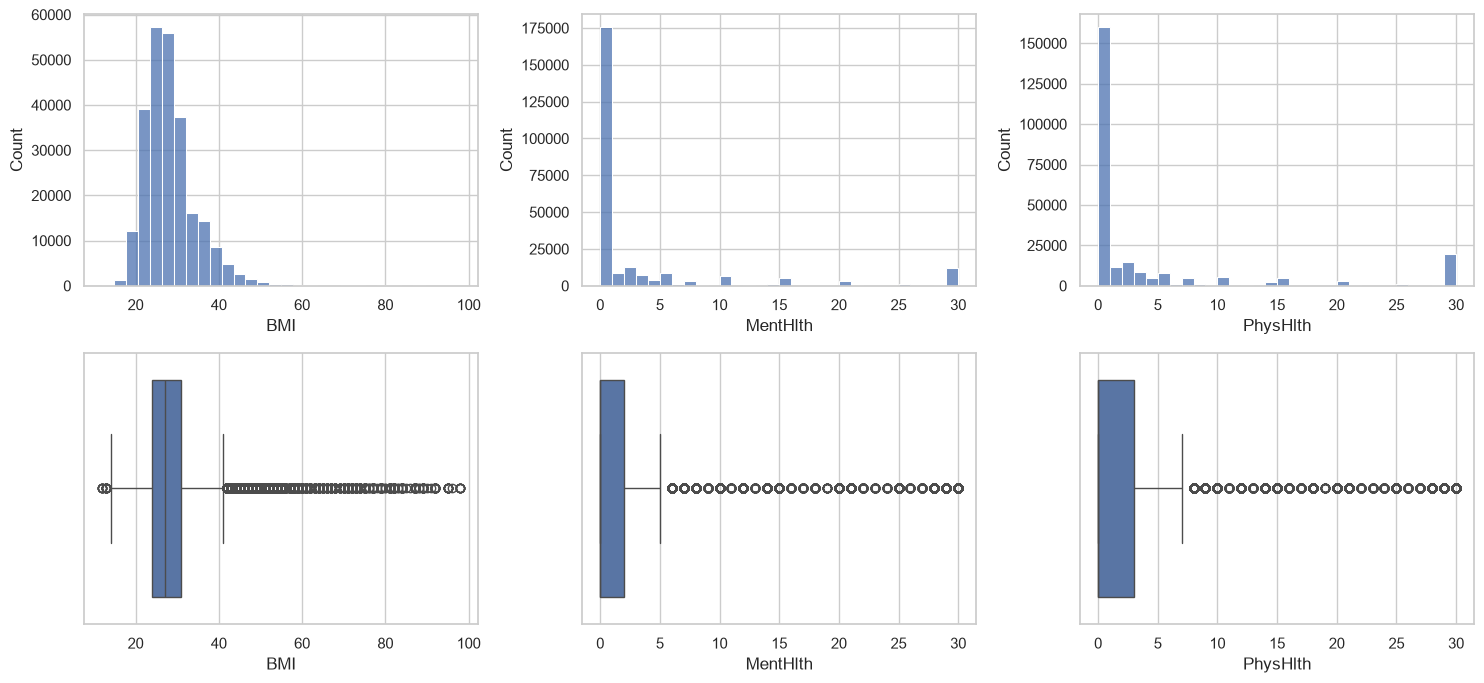

MentHlth: 0 days = 69.3% | 30 days = 4.8% | rest = 26.0%
PhysHlth: 0 days = 63.1% | 30 days = 7.6% | rest = 29.3%


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, c in enumerate(num_cols):
    sns.histplot(df[c], bins=30, ax=axes[0, i])
    sns.boxplot(x=df[c], ax=axes[1, i])
plt.tight_layout(); plt.show()

# Check of the spike at 30 days (MentHlth and PhysHlth)
for c in ['MentHlth', 'PhysHlth']:
    vc = df[c].value_counts(normalize=True).sort_index() * 100
    print(f"{c}: 0 days = {vc.loc[0]:.1f}% | 30 days = {vc.loc[30]:.1f}% | rest = {100 - vc.loc[0] - vc.loc[30]:.1f}%")

MentHlth and PhysHlth have a huge spike at **0** (63–69 %) and a second one at the ceiling of **30** days. A boxplot flags a huge number of "outliers" in them, but these are not errors: they are the tail of a variable with an excess of zeros.

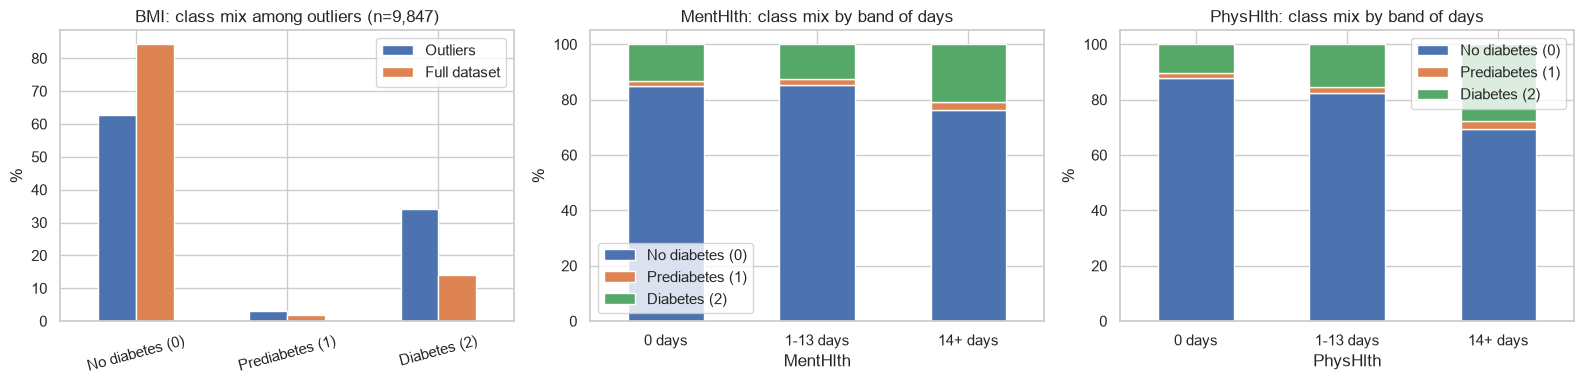

BMI outliers: 9847 | % diabetes among them: 34.2 | overall: 13.9

MentHlth: n per band and % diabetes (class 2)
                n  % diabetes
MentHlth                     
0 days     175680        13.3
1-13 days   53463        12.7
14+ days    24537        21.0

PhysHlth: n per band and % diabetes (class 2)
                n  % diabetes
PhysHlth                     
0 days     160052        10.5
1-13 days   59968        15.4
14+ days    33660        27.8


In [6]:
def outlier_mask(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

class_labels = ['No diabetes (0)', 'Prediabetes (1)', 'Diabetes (2)']
overall = df[target].value_counts(normalize=True).sort_index() * 100   

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# BMI: 
m = outlier_mask(df['BMI'])
comp = pd.DataFrame({'Outliers': df.loc[m, target].value_counts(normalize=True).sort_index() * 100,
                     'Full dataset': overall}).fillna(0)
comp.index = class_labels
comp.plot(kind='bar', ax=axes[0], rot=15, title=f"BMI: class mix among outliers (n={m.sum():,})")
axes[0].set_ylabel('%')

# MentHlth and PhysHlth: many zeros and a ceiling at 30 -> analysed by bands
day_bins, day_labels = [-1, 0, 13, 30], ['0 days', '1-13 days', '14+ days']
for ax, c in zip(axes[1:], ['MentHlth', 'PhysHlth']):
    band = pd.cut(df[c], day_bins, labels=day_labels)
    ct = pd.crosstab(band, df[target], normalize='index') * 100
    ct.columns = class_labels
    ct.plot(kind='bar', stacked=True, ax=ax, rot=0, title=f"{c}: class mix by band of days")
    ax.set_ylabel('%')
plt.tight_layout(); plt.show()

print("BMI outliers:", int(m.sum()), "| % diabetes among them:", round((df.loc[m, target] == 2).mean() * 100, 1),
      "| overall:", round(overall[2], 1))
for c in ['MentHlth', 'PhysHlth']:
    band = pd.cut(df[c], day_bins, labels=day_labels)
    print(f"\n{c}: n per band and % diabetes (class 2)")
    print(pd.DataFrame({'n': band.value_counts().sort_index(),
                        '% diabetes': ((df[target] == 2).groupby(band, observed=True).mean() * 100).round(1)}))

**Decision 1 — outliers are kept.** BMI outliers (severe obesity) are plausible values and informative: **34.2 % of them are diabetes vs 13.9 % overall**. They are over-represented, yet most are still class 0. Deleting them would remove exactly the people with the highest risk.

**Decision 2 — MentHlth/PhysHlth are kept and also offered as bands.** With 14+ days of poor health the diabetes share rises (~21 % for MentHlth, ~28 % for PhysHlth). So the band (0 / 1–13 / 14+) carries signal that a linear term would blur; Parts 2 and 3 test this "binning" as a feature variant.

## 1.5 Categorical variables: distribution and relation with the target
**Why:** very unbalanced binaries carry little information and can mislead; bars of "class mix inside each category" show the direction and size of each association at a glance.

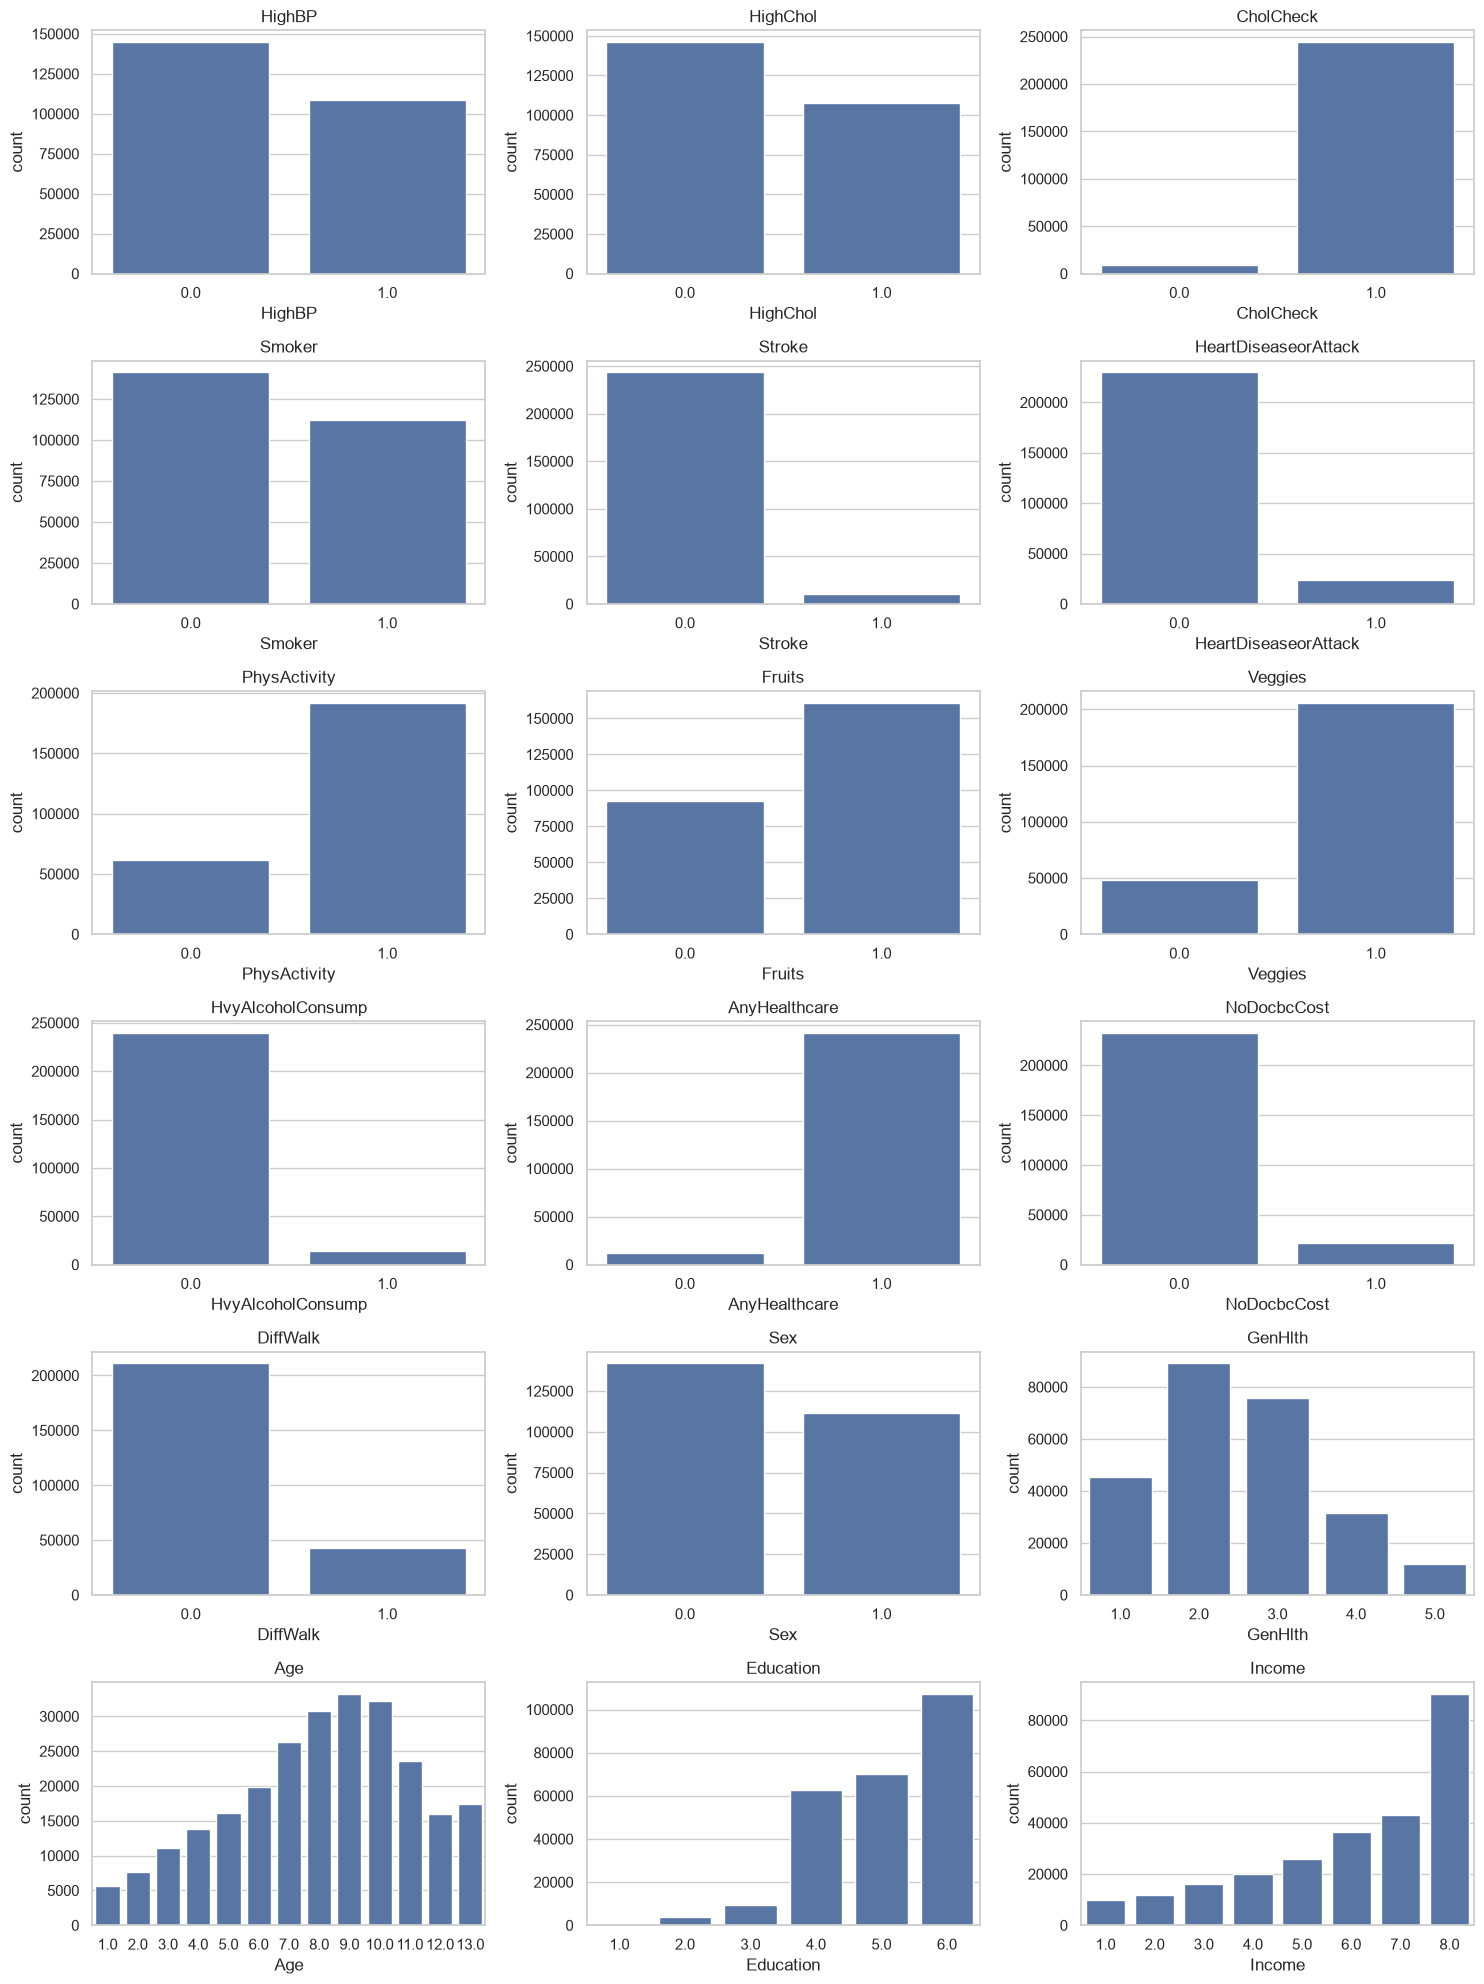

In [7]:
fig, axes = plt.subplots(6, 3, figsize=(15, 20))
for ax, c in zip(axes.ravel(), cat_cols):
    sns.countplot(x=c, data=df, ax=ax)
    ax.set_title(c)
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

Several binaries are very unbalanced: CholCheck (~96 % = 1), AnyHealthcare (~95 %), HvyAlcoholConsump (~6 %), Stroke (~4 %). Education levels 1 and 2 have very few cases. The sample is therefore skewed towards high education and income — a *representativity* limitation to state in the final discussion.

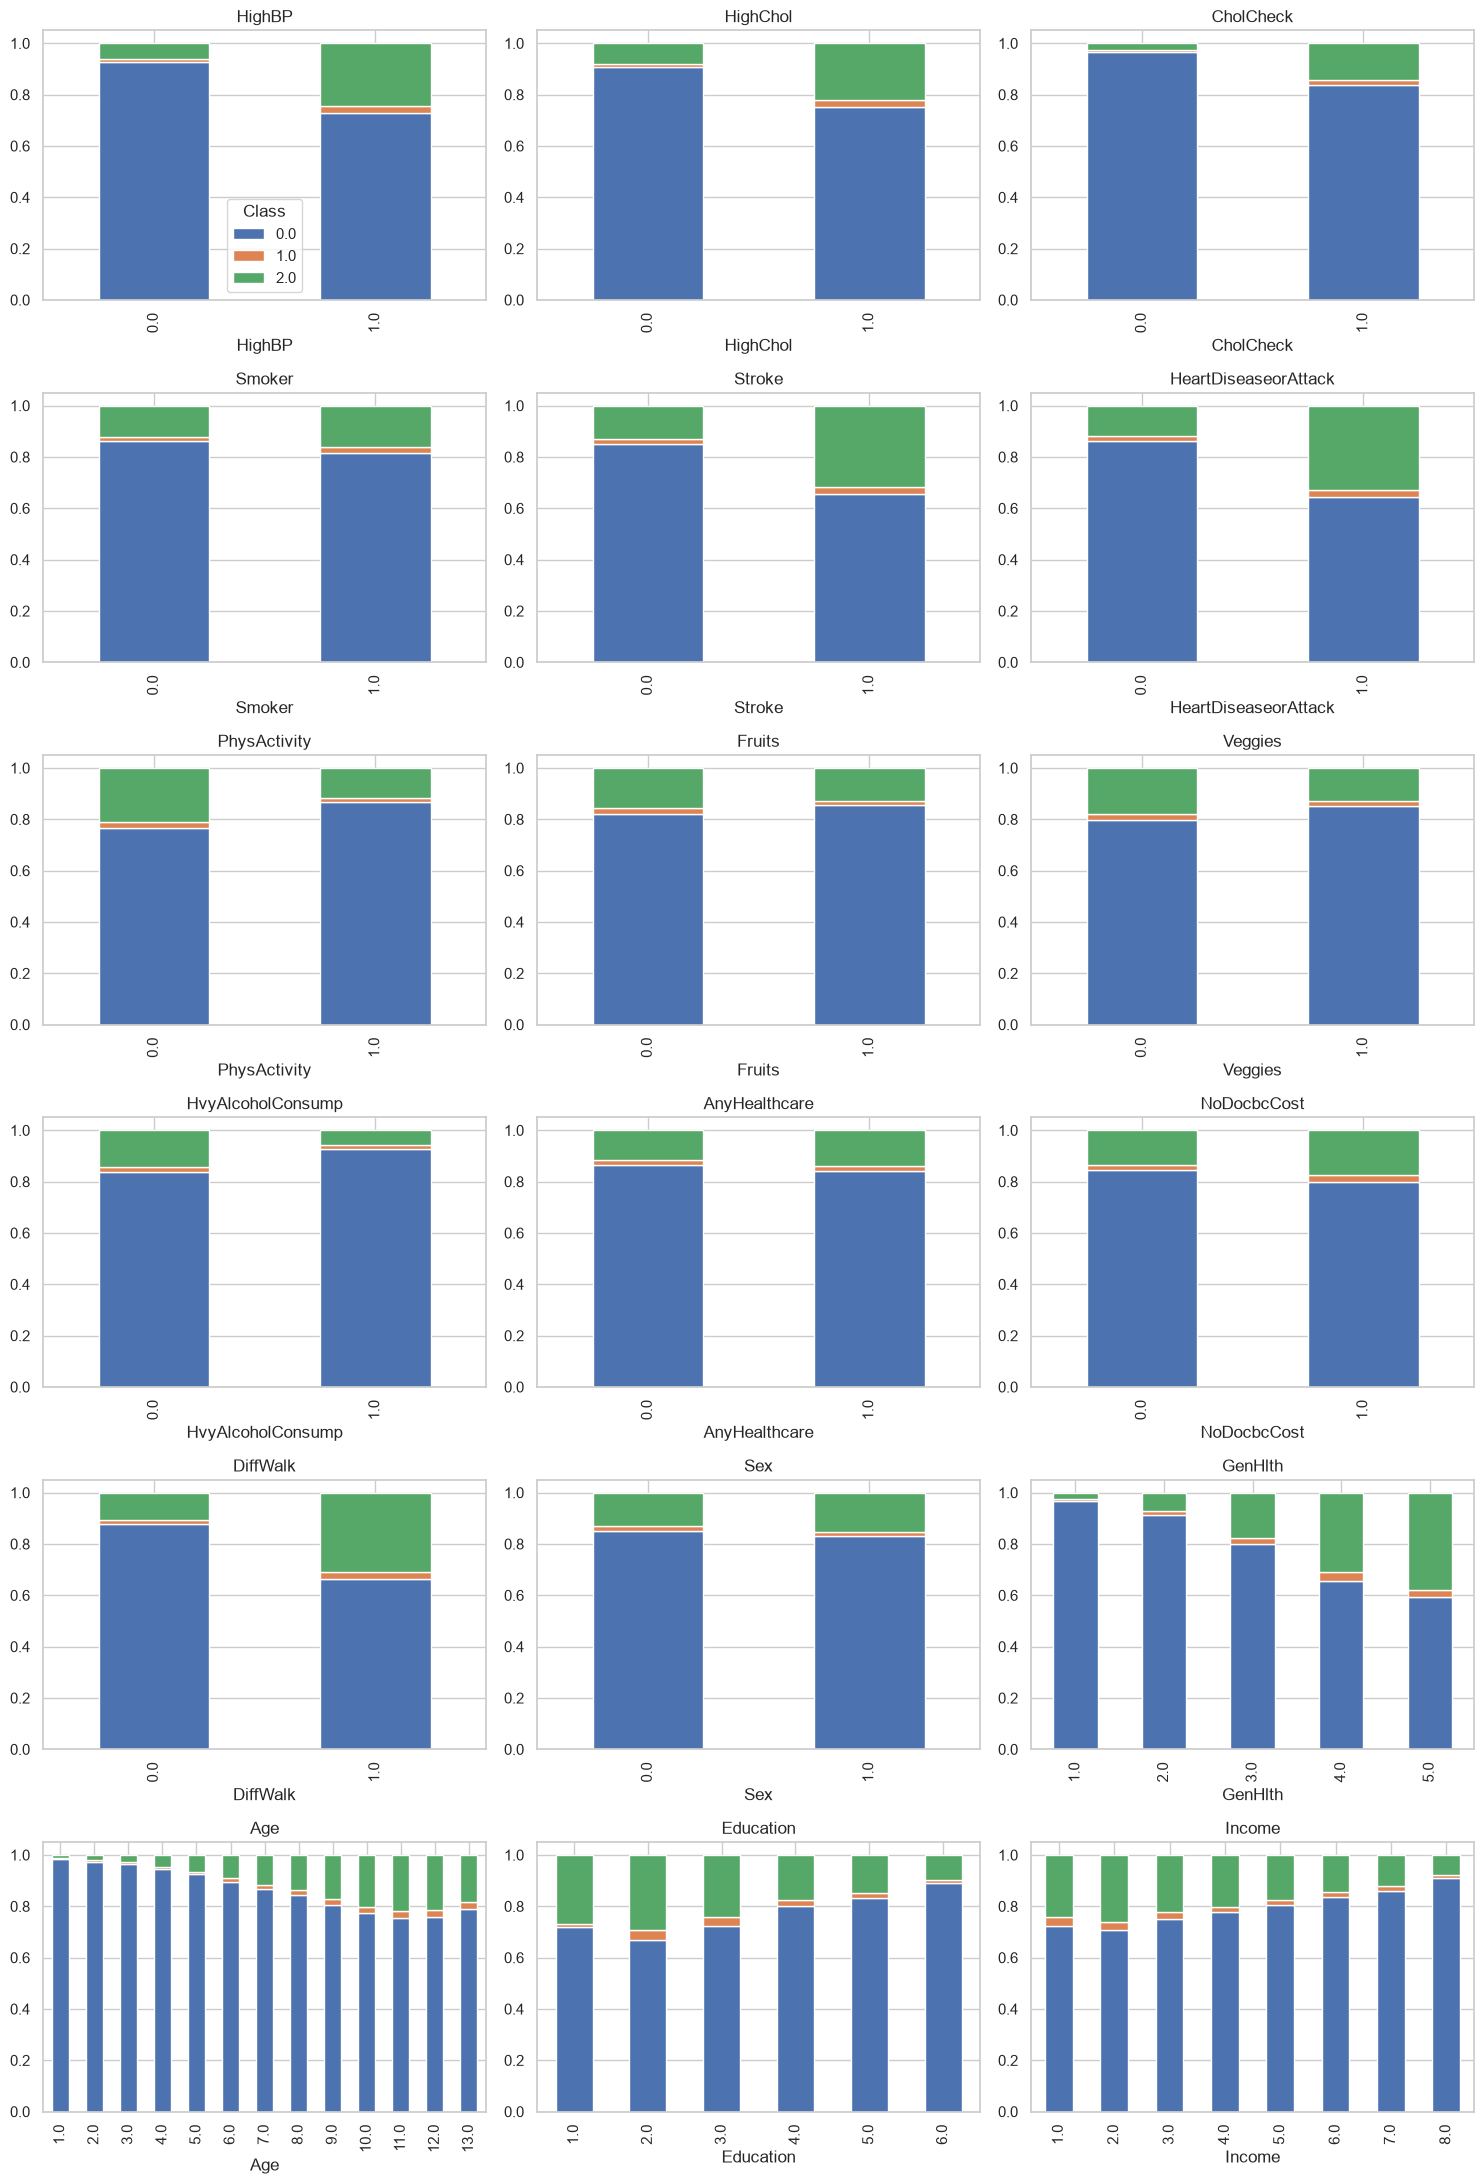

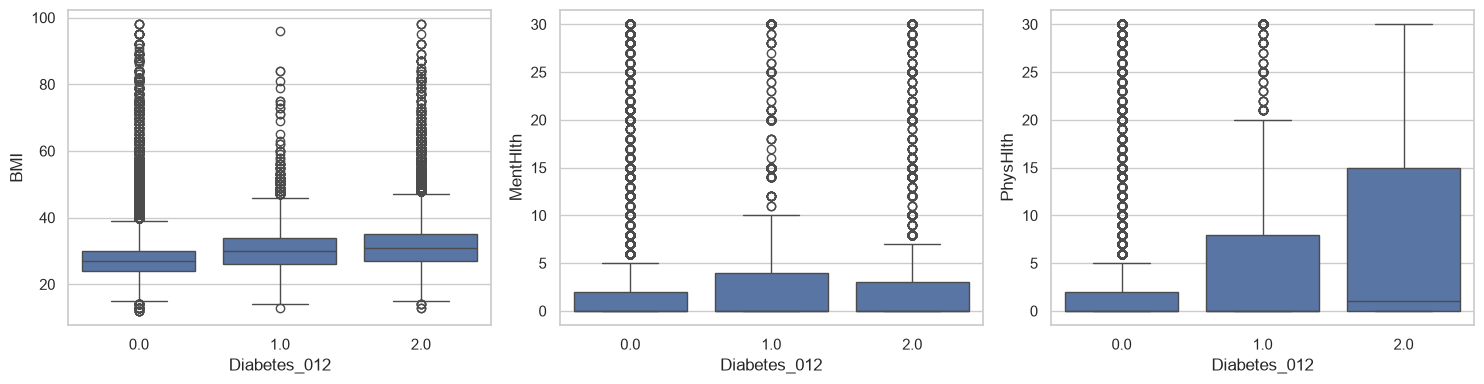

HighBP                  0.272
DiffWalk                0.224
GenHlth                 0.219
HighChol                0.211
HeartDiseaseorAttack    0.180
Age                     0.138
Income                  0.124
PhysActivity            0.122
Stroke                  0.107
Education               0.095
CholCheck               0.068
Smoker                  0.063
Veggies                 0.059
HvyAlcoholConsump       0.058
Fruits                  0.042
NoDocbcCost             0.040
Sex                     0.031
AnyHealthcare           0.017
dtype: float64
BMI: H=14130.7, p=0
MentHlth: H=528.9, p=1.41e-115
PhysHlth: H=6661.9, p=0


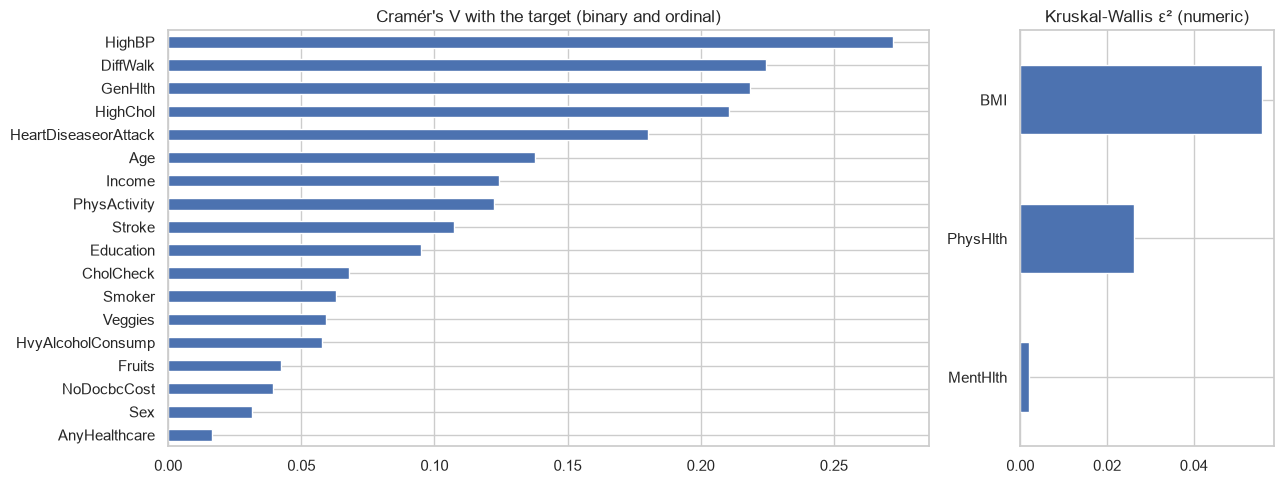

In [8]:
# Class mix inside each category
fig, axes = plt.subplots(6, 3, figsize=(15, 22))
for ax, c in zip(axes.ravel(), cat_cols):
    ct = pd.crosstab(df[c], df[target], normalize='index')
    ct.plot(kind='bar', stacked=True, ax=ax, legend=False)
    ax.set_title(c)
for ax in axes.ravel()[len(cat_cols):]:
    ax.axis('off')
axes.ravel()[0].legend(title='Class')
plt.tight_layout(); plt.show()

# Numeric variables by class
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(x=target, y=c, data=df, ax=ax)
plt.tight_layout(); plt.show()

# Quantify: Cramér's V (categorical-like) and Kruskal-Wallis (numeric)
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(ct)[0]
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

print(pd.Series({c: cramers_v(df[c], df[target]) for c in cat_cols}).sort_values(ascending=False).round(3))

for c in num_cols:
    groups = [g[c].values for _, g in df.groupby(target)]
    h, p = stats.kruskal(*groups)
    print(f"{c}: H={h:.1f}, p={p:.3g}")

# Graphical summary of the association with the target
v = pd.Series({c: cramers_v(df[c], df[target]) for c in cat_cols}).sort_values()
eps = pd.Series({c: stats.kruskal(*[g[c].values for _, g in df.groupby(target)])[0] / (len(df) - 1)
                 for c in num_cols}).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [3, 1]})
v.plot(kind='barh', ax=axes[0], title="Cramér's V with the target (binary and ordinal)")
eps.plot(kind='barh', ax=axes[1], title='Kruskal-Wallis ε² (numeric)')
plt.tight_layout(); plt.show()

**Why these two measures:** with n ≈ 250,000 *every* p-value is ~0, so p-values cannot rank variables.**Effect sizes**: Cramér's V (0–1) for categorical-like variables and ε² = H/(n−1) for numeric ones (Kruskal-Wallis, rank based, so robust to the skewed distributions seen above).

**Reading:**
- Clear gradients in GenHlth, DiffWalk, HighBP, Stroke and HeartDiseaseorAttack.
- Age is **not monotonic** (the rate drops after 75–80 years); Education and Income are not monotonic at the low end either → this will matter in §1.10.
- Cramér's V (all < 0.3): HighBP 0.27 · DiffWalk 0.22 · GenHlth 0.22 · HighChol 0.21; weakest: AnyHealthcare, Sex and NoDocbcCost (< 0.05).
- Kruskal-Wallis ε²: BMI 0.056 · PhysHlth 0.026 · MentHlth 0.002. ε² measures association by *ranks*, so MentHlth looks null, but by bands the diabetes share does rise at 14+ days (§1.4): it is not discarded.
- **Counter-intuitive signs, not causal:** HvyAlcoholConsump appears *protective* (probable "sick quitter": people who get ill stop drinking → reverse causality) and CholCheck is associated with *more* diabetes (probable detection bias: those who get checked are more likely to be diagnosed).  

## 1.6 Correlations (Spearman)
**Why Spearman:** it works for binary, ordinal and skewed variables alike (rank based). Two goals: (i) which variables correlate with the target, (ii) which predictors are redundant with each other.

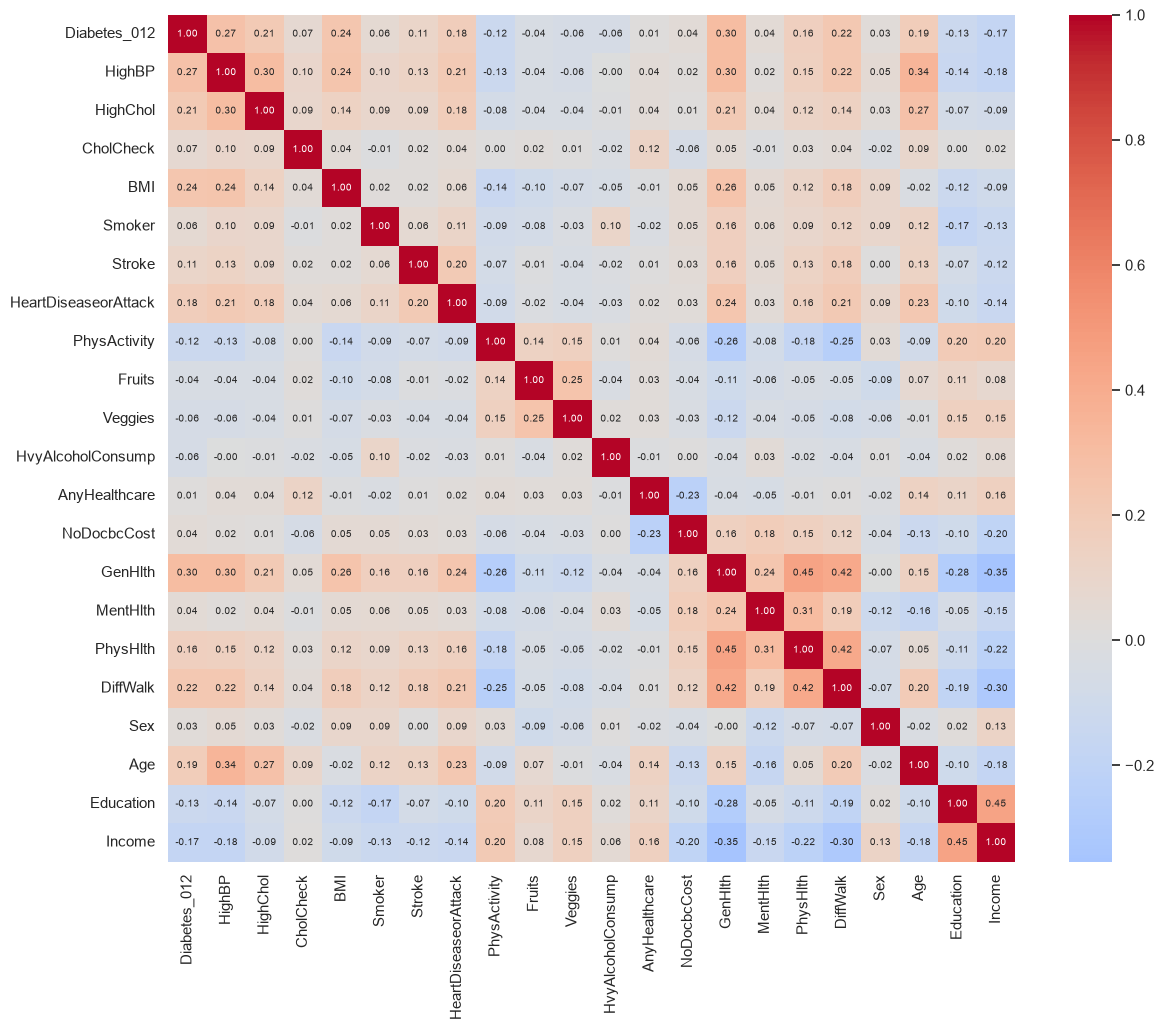

GenHlth                 0.297
HighBP                  0.272
BMI                     0.236
DiffWalk                0.224
HighChol                0.211
Age                     0.186
HeartDiseaseorAttack    0.179
Income                 -0.173
PhysHlth                0.162
Education              -0.127
PhysActivity           -0.122
Stroke                  0.106
CholCheck               0.068
Smoker                  0.063
Veggies                -0.059
HvyAlcoholConsump      -0.057
MentHlth                0.045
Fruits                 -0.042
NoDocbcCost             0.037
Sex                     0.030
AnyHealthcare           0.015
Name: Diabetes_012, dtype: float64


In [9]:
corr = df.corr(method='spearman')

plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            annot_kws={'size': 7}, square=True)
plt.show()

# Correlation of every variable with the target
print(corr[target].drop(target).sort_values(key=abs, ascending=False).round(3))

With the target: GenHlth 0.30 · HighBP 0.27 · BMI 0.24 · DiffWalk 0.22 · HighChol 0.21; negative: Income −0.17 and Education −0.13. All moderate.

**Redundancy between predictors:** GenHlth–PhysHlth 0.45, GenHlth–DiffWalk 0.42, PhysHlth–DiffWalk 0.42, Education–Income 0.45. This is only moderate multicollinearity (no pair above 0.45). It affects the *interpretation* of linear coefficients, not predictive ability, and it is handled by regularisation (L1/L2) and by tree models. The VIF is computed formally in the regression part (§2.5), which confirms it is not a problem.

## 1.7 Duplicates
**Why:** with almost only binary/ordinal variables, two different people can easily have exactly the same answers. Are duplicated rows data errors (to delete) or genuine repeated observations (to keep)? The answer changes the class balance and, more importantly, the *validity of the test set*.

In [10]:
n_dup = df.duplicated().sum()
print(n_dup, "duplicated rows", f"({n_dup/len(df)*100:.1f}%)")

23899 duplicated rows (9.4%)


23,899 duplicated rows (9.4 %). With variables that are almost all binary it is normal for different people to coincide, so **they are not considered errors**. Two versions of the data:

- `df_nodup`: duplicates removed (229,781 rows, one per distinct profile).
- `df_weighted`: the same unique profiles plus a column `w` = number of times each profile appeared in the original data. 95 % of the profiles have `w = 1`.

In [11]:
df_nodup = df.drop_duplicates().reset_index(drop=True)

feats = list(df.columns)
weights = df.groupby(feats).size().rename('w').reset_index()
df_weighted = df_nodup.merge(weights, on=feats, how='left')     # same row, plus its weight

assert len(df_weighted) == len(df_nodup)
assert df_weighted['w'].sum() == len(df)                          # weights add up to the original rows
print(df_weighted['w'].value_counts().head())

w
1    218594
2      7219
3      1882
4       790
5       372
Name: count, dtype: int64


## 1.8 Do duplicates matter? Same analysis with and without them
**Why:** The *same* numerical EDA is run on `df` and on `df_nodup` and compare. If every statistic barely moves, the duplicate decision is a modelling-validity question, not a statistical one.

The function below computes all the tables in one go (association measures, mutual information, event rates by bands, strongly correlated pairs), so both versions are treated identically.

In [12]:
def eda_summary(d, target=target, num_cols=num_cols, cat_cols=cat_cols):
    r = {}
    r['n_rows'] = len(d)
    r['class_pct'] = d[target].value_counts(normalize=True).sort_index() * 100
    r['mean_profile'] = d.groupby(target).mean().T
    X = d.drop(columns=[target])
    disc = [c not in num_cols for c in X.columns]       # which columns are discrete for mutual information
    r['mutual_info'] = pd.Series(mutual_info_classif(X, d[target], discrete_features=disc,
                                 random_state=SEED), index=X.columns)
    r['cramers_v'] = pd.Series({c: cramers_v(d[c], d[target]) for c in cat_cols})
    # Kruskal-Wallis: epsilon^2 and pairwise CLES (common-language effect size from Mann-Whitney)
    eps, cles = {}, {}
    for c in num_cols:
        g = {k: v[c].values for k, v in d.groupby(target)}
        H, _ = stats.kruskal(*g.values()); eps[c] = H / (len(d) - 1)
        for a, b in combinations(g, 2):
            U, _ = stats.mannwhitneyu(g[a], g[b], alternative='two-sided')
            cles[f"{c} {int(a)}vs{int(b)}"] = U / (len(g[a]) * len(g[b]))
    r['kw_epsilon2'] = pd.Series(eps); r['cles'] = pd.Series(cles)
    # diabetes (class 2) rates by bands
    diab = (d[target] == 2).astype(int)
    r['rate_BMI'] = diab.groupby(pd.cut(d['BMI'], [10, 18.5, 25, 30, 35, 40, 50, 100]), observed=True).mean()
    r['rate_Age'] = diab.groupby(d['Age']).mean()
    for c in ['MentHlth', 'PhysHlth']:
        r[f'rate_{c}'] = diab.groupby(pd.cut(d[c], [-1, 0, 13, 30], labels=['0', '1-13', '14+']),
                                      observed=True).mean()
    risk_cols = ['HighBP', 'HighChol', 'Stroke', 'HeartDiseaseorAttack', 'DiffWalk']
    r['rate_n_risk'] = diab.groupby(d[risk_cols].sum(axis=1)).mean()
    corr = d.drop(columns=[target]).corr(method='spearman')
    pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
    r['corr_pairs>=0.4'] = pairs[pairs.abs() >= 0.4]
    return r

In [13]:
res_with = eda_summary(df)           
res_without = eda_summary(df_nodup)
print("Rows:", res_with['n_rows'], "(with duplicates) |", res_without['n_rows'], "(without)")

def compare(key, decimals=3):
    t = pd.concat([res_with[key], res_without[key]], axis=1, keys=['with', 'without'])
    t['diff'] = t['without'] - t['with']
    return t.round(decimals)

for k in ['class_pct', 'cramers_v', 'mutual_info', 'kw_epsilon2', 'cles',
          'rate_BMI', 'rate_Age', 'rate_MentHlth', 'rate_PhysHlth', 'rate_n_risk', 'corr_pairs>=0.4']:
    print(f"\n=== {k} ===")
    print(compare(k, 2 if k == 'class_pct' else 3))

# Mean profile by class: largest absolute difference between versions
diff_profile = (res_without['mean_profile'] - res_with['mean_profile']).abs()
print("\nMax absolute difference in class means:", round(float(diff_profile.max().max()), 4))
print(diff_profile.stack().sort_values(ascending=False).head(5).round(4))

# Summary: what changes most when duplicates are removed?
for k in ['cramers_v', 'mutual_info', 'kw_epsilon2', 'cles']:
    d_ = (res_without[k] - res_with[k]).abs()
    print(f"{k:12s} | max change: {d_.max():.4f} ({d_.idxmax()}) | mean change: {d_.mean():.4f}")
print("Rank correlation (Spearman) of Cramér's V with vs without:",
      round(stats.spearmanr(res_with['cramers_v'], res_without['cramers_v'])[0], 3))

Rows: 253680 (with duplicates) | 229781 (without)

=== class_pct ===
               with  without  diff
Diabetes_012                      
0.0           84.24    82.71 -1.53
1.0            1.83     2.01  0.19
2.0           13.93    15.27  1.34

=== cramers_v ===
                       with  without   diff
HighBP                0.272    0.262 -0.010
HighChol              0.211    0.205 -0.006
CholCheck             0.068    0.076  0.008
Smoker                0.063    0.047 -0.016
Stroke                0.107    0.100 -0.007
HeartDiseaseorAttack  0.180    0.171 -0.009
PhysActivity          0.122    0.103 -0.019
Fruits                0.042    0.025 -0.017
Veggies               0.059    0.044 -0.016
HvyAlcoholConsump     0.058    0.067  0.009
AnyHealthcare         0.017    0.025  0.009
NoDocbcCost           0.040    0.028 -0.012
DiffWalk              0.224    0.211 -0.014
Sex                   0.031    0.033  0.001
GenHlth               0.219    0.205 -0.013
Age                   0.138    0.

**What is seen:** Cramér's V changes at most by 0.019 (PhysActivity), mutual information by 0.005, ε² by 0.006, CLES by 0.018, and the variable ranking is practically identical (Spearman ρ = 0.986). The only visible change is the class mix: class 0 falls from 84.2 % to 82.7 %. So duplicates do **not** change *what the data say*.

**Decision 3 — train with all the records, as weighted unique profiles (`df_weighted`).**
- Two different people may have exactly the same values, and the model should see that frequency → keep the duplicates' information through the weight `w`. Training with `sample_weight = w` is equivalent to training on the 253,680 original rows.
- **Why not simply keep duplicated rows and split at random?** An identical record could land in train *and* in test, and the test would be too optimistic (the model has "seen" those exact answers). Collapsing duplicates into one row **before** splitting prevents that leakage.
- Evaluation metrics are also weighted with `w_test`, so they describe the original population (84.2 / 1.8 / 13.9 %).
- `df_nodup` is used only for the exploratory analyses (PCA, ordinals, label checks) and as a sensitivity analysis.

## 1.9 Global structure: PCA and standardised differences between classes
**Why:** two cheap views of "how separable are the classes?". PCA gives a 2-D picture of the whole 21-variable space; the standardised mean difference (SMD) says, variable by variable, how far each class is from the "no diabetes" class — and, crucially, whether prediabetes behaves like an *intermediate* class.

Variance explained by PC1 and PC2: [0.156 0.085]


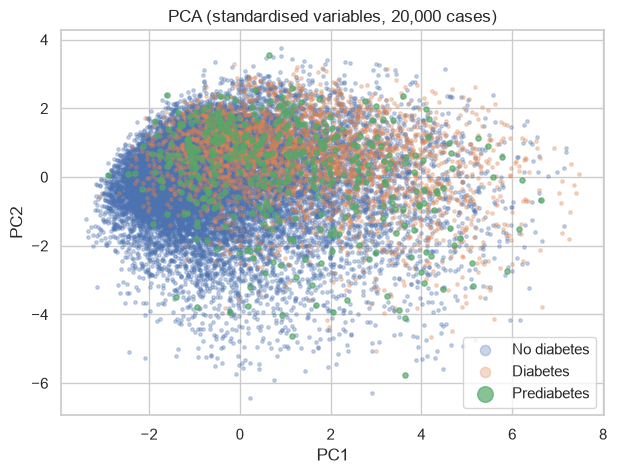

                       PC1   PC2
GenHlth               0.41 -0.05
DiffWalk              0.38 -0.00
PhysHlth              0.36 -0.10
Income               -0.31  0.21
HighBP                0.26  0.32
Education            -0.24  0.16
PhysActivity         -0.23  0.08
HeartDiseaseorAttack  0.23  0.23


In [14]:
Xs = df_nodup.drop(columns=[target]); ys = df_nodup[target]
Z = StandardScaler().fit_transform(Xs)
pca = PCA(n_components=2, random_state=SEED).fit(Z)
print("Variance explained by PC1 and PC2:", pca.explained_variance_ratio_.round(3))

idx = Xs.sample(min(20000, len(Xs)), random_state=SEED).index        # subsample only for plotting
coords = pca.transform(Z[idx])
fig, ax = plt.subplots(figsize=(7, 5))
# prediabetes is the least represented class, so it is drawn last to keep it visible
for k, name in zip([0, 2, 1], ['No diabetes', 'Diabetes', 'Prediabetes']):
    m = (ys.loc[idx].values == k)
    ax.scatter(coords[m, 0], coords[m, 1], s=6 if k != 1 else 14, alpha=0.3 if k != 1 else 0.7, label=name)
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend(markerscale=3)
ax.set_title('PCA (standardised variables, 20,000 cases)')
plt.show()

loadings = pd.DataFrame(pca.components_.T, index=Xs.columns, columns=['PC1', 'PC2'])
print(loadings.sort_values('PC1', key=abs, ascending=False).head(8).round(2))

                      1 vs 0  2 vs 0  2 vs 1
GenHlth                 0.48    0.78    0.30
HighBP                  0.47    0.72    0.25
BMI                     0.40    0.58    0.18
DiffWalk                0.33    0.58    0.25
HighChol                0.45    0.55    0.10
Age                     0.41    0.50    0.09
HeartDiseaseorAttack    0.21    0.47    0.26
PhysHlth                0.26    0.44    0.18
Income                 -0.33   -0.40   -0.07
Education              -0.25   -0.29   -0.04
PhysActivity           -0.17   -0.28   -0.11
Stroke                  0.11    0.28    0.17
CholCheck               0.17    0.21    0.03
HvyAlcoholConsump      -0.10   -0.19   -0.09
MentHlth                0.16    0.15   -0.00
Smoker                  0.08    0.13    0.05
Veggies                -0.08   -0.12   -0.03
Sex                     0.01    0.09    0.08
Fruits                 -0.03   -0.07   -0.04
AnyHealthcare           0.01    0.07    0.06
NoDocbcCost             0.14    0.06   -0.08


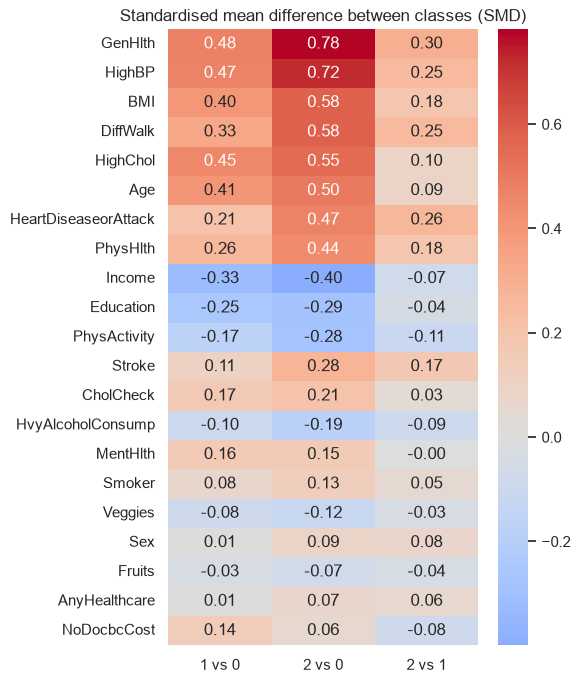

Variables where 1 vs 0 and 2 vs 0 have the same sign: 21 of 21
Median ratio |1 vs 0| / |2 vs 0|: 0.62


In [15]:
mu, sd = Xs.groupby(ys).mean(), Xs.std()
smd = pd.DataFrame({'1 vs 0': (mu.loc[1] - mu.loc[0]) / sd,
                    '2 vs 0': (mu.loc[2] - mu.loc[0]) / sd,
                    '2 vs 1': (mu.loc[2] - mu.loc[1]) / sd})
smd = smd.loc[smd['2 vs 0'].abs().sort_values(ascending=False).index]
print(smd.round(2))

plt.figure(figsize=(5, 8))
sns.heatmap(smd, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Standardised mean difference between classes (SMD)'); plt.show()

# If '1 vs 0' has the same sign as '2 vs 0' but a smaller magnitude, class 1 is an intermediate class
print("Variables where 1 vs 0 and 2 vs 0 have the same sign:",
      int((np.sign(smd['1 vs 0']) == np.sign(smd['2 vs 0'])).sum()), "of", len(smd))
print("Median ratio |1 vs 0| / |2 vs 0|:",
      round((smd['1 vs 0'].abs() / smd['2 vs 0'].abs()).median(), 2))

**PCA (2 components, 24 % of the variance).** There is a gradient along PC1 (no diabetes on the left, diabetes on the right) but the three classes overlap heavily in 2-D; prediabetes (2 %) falls in the intermediate zone. PC1 loads positively on GenHlth (0.41), DiffWalk (0.38) and PhysHlth (0.36) and negatively on Income (−0.31) and Education (−0.24): it is an axis of **"poor general health / lower socio-economic level"**. *Limitation:* PCA on binary and ordinal variables is an approximation and two components capture little information. Overlap in 2-D does not prove the classes are inseparable with all 21 variables — it only says there is no *simple* separation. This supports **H1** (moderate, not high, performance) and motivates the clustering design of Part 4.


**SMD between classes.** Prediabetes goes in the same direction as diabetes in **all 21 variables**, with a median magnitude of ~0.62× → it behaves as an **intermediate class**. This supports **H3** and justifies always reporting metrics **per class** rather than only on average.

## 1.10 Ordinal variables: monotonic or not?
**Why:** should an ordinal such as Age enter the models as a *number* (one coefficient: "+1 level adds the same risk") or as a *category* (one coefficient per level)? The first is simpler and keeps the order but assumes monotonicity. 


GenHlth: increasing = True | decreasing = False
GenHlth               1.0      2.0      3.0      4.0      5.0
n                 34907.0  77536.0  73714.0  31546.0  12078.0
% diabetes            3.3      8.1     18.1     31.0     37.9
% prediab.+diab.      4.1      9.7     20.4     34.3     40.8

Age: increasing = False | decreasing = False
Age                 1.0     2.0      3.0      4.0      5.0      6.0      7.0   \
n                 5512.0  7068.0  10025.0  12234.0  14050.0  17299.0  23140.0   
% diabetes           1.4     2.0      3.1      5.1      7.5     10.1     13.3   
% prediab.+diab.     1.8     2.7      3.9      6.3      8.6     11.9     15.1   

Age                  8.0      9.0      10.0     11.0     12.0     13.0  
n                 27301.0  29736.0  29168.0  22041.0  15394.0  16813.0  
% diabetes           15.5     19.1     22.2     23.1     22.0     19.0  
% prediab.+diab.     17.5     21.5     24.6     25.8     24.9     21.7  

Education: increasing = False | decreas

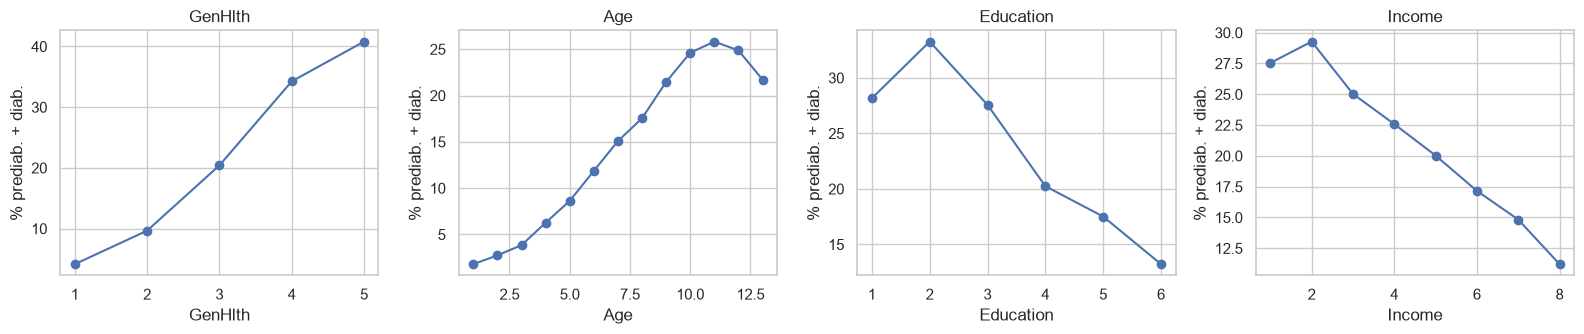

In [16]:
for c in ord_cols:
    g = df_nodup.groupby(c)[target]
    t = pd.DataFrame({'n': g.size(),
                      '% diabetes': g.apply(lambda s: (s == 2).mean() * 100),
                      '% prediab.+diab.': g.apply(lambda s: (s >= 1).mean() * 100)}).round(1)
    dif = np.diff(t['% prediab.+diab.'].values)
    print(f"\n{c}: increasing = {bool((dif >= 0).all())} | decreasing = {bool((dif <= 0).all())}")
    print(t.T)

fig, axes = plt.subplots(1, len(ord_cols), figsize=(4 * len(ord_cols), 3.5))
for ax, c in zip(axes, ord_cols):
    (df_nodup[target] >= 1).groupby(df_nodup[c]).mean().mul(100).plot(marker='o', ax=ax, title=c)
    ax.set_ylabel('% prediab. + diab.')
plt.tight_layout(); plt.show()

**Decision 4 — the four ordinals stay numeric (1..k) instead of one-hot**, to preserve the order without multiplying columns:
- **GenHlth:** monotonically increasing → plain numeric.
- **Age:** rises up to band 11 (70–74) and then falls (25.8 → 24.9 → 21.7 %) → **not monotonic**. Linear models get **splines** on Age (Part 2 and 3); trees capture it by themselves.
- **Income:** decreases almost always (except step 1→2) → numeric.
- **Education:** decreases from level 3 to 6, but levels 1–2 (174 and 4,040 cases) break monotonicity → numeric; if it causes trouble, levels 1–3 can be merged.

## 1.11 Label quality, conflicts and interactions
Three checks *before* modelling, because they set the realistic ceiling of any model:
1. Are there people with identical predictors but different labels? (label noise → performance ceiling)
2. How far can the label itself be trusted, especially class 1 (prediabetes)?
3. Does the effect of one variable depend on another? (interactions)

### Identical profiles with different labels

In [17]:
X_cols = [c for c in df.columns if c != target]
cnt = df.groupby(X_cols + [target]).size().rename('n').reset_index()          # profile + label -> number of rows
perf = cnt.groupby(X_cols).agg(n_total=('n', 'sum'), n_max=('n', 'max'), n_classes=(target, 'nunique'))

rep_ = perf[perf['n_total'] >= 2]            # a conflict can only be detected on repeated profiles
conf = perf[perf['n_classes'] > 1]
print(f"Distinct profiles in X: {len(perf):,} | repeated (n>=2): {len(rep_):,} ({len(rep_)/len(perf)*100:.1f}%)")
print(f"Profiles with more than one label: {len(conf):,} ({len(conf)/len(rep_)*100:.1f}% of the repeated)")
print(f"Rows inside those profiles: {conf['n_total'].sum():,} ({conf['n_total'].sum()/len(df)*100:.2f}% of all)")
print(f"Lower bound of the error caused by conflicts: {(1 - perf['n_max'].sum()/len(df))*100:.2f}%  (sees only the repeated part)")

# which class "loses" inside its profile? (minority row = label different from the most frequent one of the profile)
cnt = cnt.merge(perf[['n_total', 'n_max']].reset_index(), on=X_cols)
r = cnt[cnt['n_total'] >= 2].copy()
r['minority'] = r['n'] < r['n_max']
tab = pd.DataFrame({'rows in repeated profiles': r.groupby(target)['n'].sum(),
                    'rows in minority': r[r['minority']].groupby(target)['n'].sum()}).fillna(0)
tab['% in minority'] = (tab['rows in minority'] / tab['rows in repeated profiles'] * 100).round(1)
print(); print(tab)

Distinct profiles in X: 227,908 | repeated (n>=2): 12,228 (5.4%)
Profiles with more than one label: 1,834 (15.0% of the repeated)
Rows inside those profiles: 6,120 (2.41% of all)
Lower bound of the error caused by conflicts: 0.77%  (sees only the repeated part)

              rows in repeated profiles  rows in minority  % in minority
Diabetes_012                                                            
0.0                               35723                43            0.1
1.0                                 340               129           37.9
2.0                                1937               615           31.8


**Reading.** `% in minority` says, for each class, how many of its records carry a label different from the dominant one among people with an identical profile. Class 1 (≈ 38 %) and class 2 (≈ 32 %) are far above class 0 (≈ 0.1 %): the prediabetes label is **noisy**, so no model will separate it well with these variables (supports **H3**). These conflicts are **not removed**: they are not loading errors but real variability (or survey noise), and the model must learn *probabilities*, not deterministic labels.

### Reliability of the label
`Diabetes_012` is **self-reported** (BRFSS: "has a doctor told you that you have diabetes?"; prediabetes is a separate answer). Compared with an external reference for the same period — the 2017 CDC report (2015 data) estimates 84.1 million adults with prediabetes (more than a third of adults), of whom only 11.6 % knew it, and 30.3 million with diabetes, almost 1 in 4 unaware — the 1.83 % of prediabetes here means class 1 does not measure "having prediabetes" but "having been diagnosed and reporting it". Many true positives are hidden as false 0s inside class 0, and the label depends on access to healthcare.

**Internal check of that detection bias:** if the label depends on being tested, the diagnosed share should change with the healthcare-access variables.

In [18]:
for c in ['CholCheck', 'AnyHealthcare', 'NoDocbcCost']:
    t = pd.crosstab(df_nodup[c], df_nodup[target], normalize='index') * 100
    t.columns = ['% no diabetes', '% prediabetes', '% diabetes']
    t['n'] = df_nodup[c].value_counts().sort_index()
    print(f"\n{c}"); print(t.round(2))


CholCheck
           % no diabetes  % prediabetes  % diabetes       n
CholCheck                                                  
0.0                96.74           0.67        2.59    9298
1.0                82.12           2.07       15.81  220483

AnyHealthcare
               % no diabetes  % prediabetes  % diabetes       n
AnyHealthcare                                                  
0.0                    86.47           2.05       11.48   12391
1.0                    82.50           2.01       15.49  217390

NoDocbcCost
             % no diabetes  % prediabetes  % diabetes       n
NoDocbcCost                                                  
0.0                  83.03           1.93       15.04  208455
1.0                  79.64           2.81       17.55   21326


### Interactions
There is an **interaction** when the effect of one variable changes with the value of another — e.g. a high BMI raises risk a lot in young people but less in old people (whose risk is already high because of age). A logistic regression only *adds* separate effects and cannot capture that unless the product term is added by hand (e.g. Age×BMI); trees and boosting capture it on their own. If the effect of BMI were the same at all ages, the ratio between the rate at BMI 35+ and at BMI < 25 would be similar in every age band.

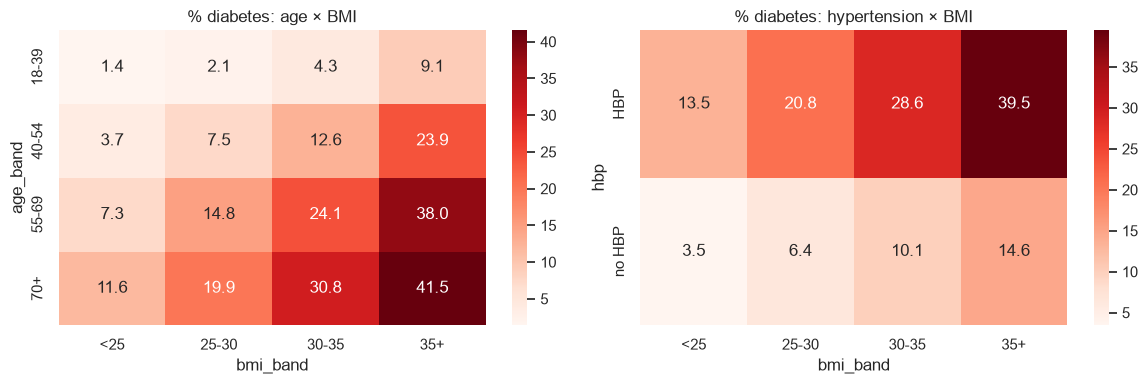

Rate ratio BMI 35+ / BMI <25 by age (if ~constant, no interaction):
age_band
18-39    6.55
40-54    6.39
55-69    5.21
70+      3.58
dtype: float64

Rate ratio BMI 35+ / BMI <25 by hypertension:
hbp
HBP       2.92
no HBP    4.22
dtype: float64


In [19]:
d = df_nodup.assign(
    age_band=pd.cut(df_nodup['Age'], [0, 4, 7, 10, 13], labels=['18-39', '40-54', '55-69', '70+']),
    bmi_band=pd.cut(df_nodup['BMI'], [0, 25, 30, 35, 100], labels=['<25', '25-30', '30-35', '35+'], right=False),
    hbp=df_nodup['HighBP'].map({0: 'no HBP', 1: 'HBP'}),
    diab=(df_nodup[target] == 2).astype(float) * 100)

t_age = d.pivot_table(index='age_band', columns='bmi_band', values='diab', aggfunc='mean', observed=True)
t_hbp = d.pivot_table(index='hbp',      columns='bmi_band', values='diab', aggfunc='mean', observed=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(t_age, annot=True, fmt='.1f', cmap='Reds', ax=axes[0]); axes[0].set_title('% diabetes: age × BMI')
sns.heatmap(t_hbp, annot=True, fmt='.1f', cmap='Reds', ax=axes[1]); axes[1].set_title('% diabetes: hypertension × BMI')
plt.tight_layout(); plt.show()

print("Rate ratio BMI 35+ / BMI <25 by age (if ~constant, no interaction):")
print((t_age['35+'] / t_age['<25']).round(2))
print("\nRate ratio BMI 35+ / BMI <25 by hypertension:")
print((t_hbp['35+'] / t_hbp['<25']).round(2))

**Decision 5 (interactions).** The ratio falls from 6.6 (18–39 years) to 3.6 (70+) and from 4.2 (no HBP) to 2.9 (HBP): BMI matters less where the baseline risk is already high → there **is** an interaction. Consequences: (i) trees/boosting are expected to do at least as well as the plain logistic (this is exactly what **H2** tests), and (ii) in the logistic model an **ablation** is run so that adds Age×BMI and HighBP×BMI. For the BMI regression a short, *a priori* list of interactions is tried in §2.6.

## 1.12 Closing the EDA: final data and the train/test split
**Why here and only here:** from this point on, every modelling decision is taken with *train* only. Creating the split once, at the end of the EDA, makes all three parts comparable and prevents anyone from "peeking" at test while exploring.

- The unit of the split is the **unique profile** (`df_weighted`), stratified by the target with a fixed seed → identical profiles can never fall on both sides.
- The weights `w` travel with each row.

In [20]:
idx_train, idx_test = train_test_split(df_weighted.index, test_size=0.2,
                                       stratify=df_weighted[target], random_state=SEED)
df_train = df_weighted.loc[idx_train].reset_index(drop=True)
df_test  = df_weighted.loc[idx_test].reset_index(drop=True)
w_train, w_test = df_train['w'], df_test['w']
DATA_SIG = f"{len(df_train)}-{len(df_test)}-{int(w_train.sum())}-{int(df_train[target].sum())}"   # used by the on-disk cache

print("train:", df_train.shape, "| test:", df_test.shape)
print((pd.DataFrame({'train': df_train[target].value_counts(normalize=True).sort_index(),
                     'test':  df_test[target].value_counts(normalize=True).sort_index()}) * 100).round(2))

# Saved so that the split is reproducible outside the notebook (e.g. for a repository)
DATA_DIR.mkdir(exist_ok=True)
df_train.to_csv(DATA_DIR / 'train.csv', index=False); df_test.to_csv(DATA_DIR / 'test.csv', index=False)

# Checks of the weighted split
FEATS = [c for c in df_train.columns if c not in (target, 'w')]      # 'w' is NOT a predictor
print("\nPredictors:", len(FEATS), "| 'w' excluded from predictors:", 'w' not in FEATS)
print("Sum of weights train + test =", int(w_train.sum() + w_test.sum()), "| rows of df =", len(df))
print((pd.DataFrame({'original df': df[target].value_counts(normalize=True).sort_index(),
                     'train weighted': df_train.groupby(target)['w'].sum() / w_train.sum(),
                     'test weighted':  df_test.groupby(target)['w'].sum() / w_test.sum()}) * 100).round(2))

train: (183824, 23) | test: (45957, 23)
              train   test
Diabetes_012              
0.0           82.71  82.71
1.0            2.01   2.01
2.0           15.27  15.27

Predictors: 21 | 'w' excluded from predictors: True
Sum of weights train + test = 253680 | rows of df = 253680
              original df  train weighted  test weighted
Diabetes_012                                            
0.0                 84.24           84.23          84.30
1.0                  1.83            1.83           1.82
2.0                 13.93           13.95          13.88


Once weighted with `w`, the class mix returns to that of the original population (≈ 84.2 / 1.8 / 13.9 %), even though the split was stratified on unique profiles. That is why all models are trained with `sample_weight = w` and evaluated with metrics weighted by `w_test`.

### Summary of EDA decisions (and where each one is used)
| Topic | Decision | Used in |
|---|---|---|
| Duplicates | Train with all records: `df_weighted` (229,781 unique profiles + weight `w`); `df_nodup` only for exploration / sensitivity | Parts 2, 3, 4 |
| Weights | `sample_weight = w` when training; metrics weighted with `w_test` (reflect the original population); `w` is not a predictor | Parts 2, 3, 4 |
| Outliers | Kept (plausible, informative values) | all |
| MentHlth / PhysHlth | Many zeros, ceiling at 30: test binning (0 / 1–13 / 14+) as a feature | §2.6, §3.2 |
| BMI (regression) | log(BMI) vs BMI; evaluate on the original scale; `Diabetes_012` as predictor, with an ablation without it | Part 2 |
| Ordinals | Numeric ordinals (no one-hot); splines on Age because it is not monotonic | §2.6, §3.2 |
| Label | Self-reported, prediabetes strongly under-diagnosed: also evaluate joint risk P(1)+P(2); declare as limitation | Parts 3, 5 |
| Interactions | Exist (BMI × Age, BMI × HBP): trees/boosting capture them; logistic gets an Age×BMI ablation | §2.6, §3.7 |
| Classification metrics | Discrimination: AUC (OvR), macro-F1, balanced accuracy. Probability: log-loss, Brier, calibration curve | Part 3 |
| Imbalance | No resampling that distorts probabilities; if used, recalibrate (`CalibratedClassifierCV`) | Part 3 |
| Split | Stratified 80/20 on unique profiles, `SEED = 42`; scaling, feature selection and encodings inside the `Pipeline` | all |
| Clustering | Standardise + PCA; choose k with silhouette and stability; profile *afterwards* with the target | Part 4 |

# Part 2 · Regression of BMI (objective O2)

**Why start with regression, before classification?** Here the three technical habits the classification part will reuse (*frequency weights* `w`, *cross-validation inside train* and *a test set touched only once*) are fixed on an easier problem.

**Why BMI as the regression target?** `Diabetes_012` is the classification target, so regression needs a *continuous* variable. BMI is the best candidate: it is continuous, not derived from other columns (no weight/height available), has structure and is connected to the main goal (it is the third most associated variable with diabetes, ρ = 0.24).

| Block | What it does | Course topic |
|---|---|---|
| 2.1 | Setup, weights and utilities | EDA §1.12 |
| 2.2 | Association with BMI: point-biserial / Spearman | statistical tests |
| 2.3 | Simple vs multiple regression (effect of collinearity) | linear regression |
| 2.4 | Multiple model with inference (coef., SE, CI, p, RSE, R², F) | linear regression |
| 2.5 | Diagnostics: linearity, variance, normality, outliers, leverage, VIF | linear regression |
| 2.6 | Improvements: log(BMI), splines on Age, binning, interactions (compared by CV) | linear regression |
| 2.7 | Variable selection: filter, wrapper, embedded | feature selection |
| 2.8 | KNN vs linear as *p* grows | bias–variance, curse of dimensionality |
| 2.9 | Shrinkage and dimension reduction: ridge, PCR, PLS; AIC / BIC / Cp | regularisation, information criteria |
| 2.10 | Non-linear regressors: polynomial, additive splines (GAM-like), model tree, decision tree, random forest (OOB), boosting | non-linearity, trees |
| 2.11 | Support vector regression (SVR) | SVM |
| 2.12 | Everything compared by CV | model assessment |
| 2.13 | Final test evaluation (once) and verdict on H7, H9 | model assessment |

**Conventions**
- `df_train` / `df_test` hold *unique profiles* with weight `w`. Everything is **fitted and evaluated with frequency weights**, so metrics reflect the original population.
- `Diabetes_012` enters as predictor in the form of two *dummies* (prediabetes, diabetes), **not** as a 0/1/2 number — the three levels are not equally spaced, so a single numeric coefficient would be wrong. An ablation without it is included. This is an **association**, not causality.
- No decision is taken with test: variants and selection are chosen by CV inside *train*.

## 2.1 Setup, weights and utilities

In [21]:
FIG_TAG = "reg"                              # prefix of the figure files saved by this part
rng_reg = np.random.default_rng(SEED)        # separate generator for this part (resampling, plots)

YN = 'BMI'                                   # regression target
w_tr = df_train['w'].to_numpy(float)
w_te = df_test['w'].to_numpy(float)

assert int(w_tr.sum() + w_te.sum()) == len(df), "weights do not add up to the original rows"
assert (w_tr == w_tr.astype(int)).all()

BASE = [c for c in df_train.columns if c not in ('w', target, YN)]    # 20 predictors without BMI nor the target
print("train:", df_train.shape, "| test:", df_test.shape, "| base predictors:", len(BASE))
print("original rows represented -> train:", int(w_tr.sum()), "| test:", int(w_te.sum()))

train: (183824, 23) | test: (45957, 23) | base predictors: 20
original rows represented -> train: 202805 | test: 50875


**Why hand-written weighted formulas?** `w` is a *frequency* weight: row *i* stands for `w_i` identical people. Library routines treat weights differently (e.g. `statsmodels` WLS would use the number of unique rows as the sample size and give slightly different standard errors). Writing `ols_fw` makes the inference exactly equal to what could be obtained using the 253,680 original rows — and the next cell **proves** it.

In [22]:
# ---------- utilities (frequency weights: row i is equivalent to w_i identical observations) ----------
def wmean(a, w): return float(np.sum(w * a) / np.sum(w))
def wstd(a, w):  return float(np.sqrt(np.sum(w * (a - wmean(a, w)) ** 2) / np.sum(w)))

def wcorr(a, b, w):
    # Weighted Pearson; with a 0/1 binary variable it is the point-biserial correlation
    ma, mb = wmean(a, w), wmean(b, w)
    cov = np.sum(w * (a - ma) * (b - mb)) / w.sum()
    return cov / (wstd(a, w) * wstd(b, w))

def metrics_reg(y, yhat, w):
    e = y - yhat
    rss = np.sum(w * e ** 2); tss = np.sum(w * (y - wmean(y, w)) ** 2)
    return dict(RMSE=np.sqrt(rss / w.sum()), MAE=np.sum(w * np.abs(e)) / w.sum(), R2=1 - rss / tss)

def ols_fw(X, y, w, names):
    # OLS with frequency weights. It matches OLS on the repeated rows (checked below):
    # n_eff = sum(w), df = n_eff - k.
    X1 = np.column_stack([np.ones(len(X)), np.asarray(X, float)])
    n_eff, k = w.sum(), X1.shape[1]
    G = X1.T @ (X1 * w[:, None])
    beta = np.linalg.solve(G, X1.T @ (w * y))
    res = y - X1 @ beta
    rss = np.sum(w * res ** 2); tss = np.sum(w * (y - wmean(y, w)) ** 2)
    dof = n_eff - k; s2 = rss / dof
    inv = np.linalg.inv(G); se = np.sqrt(s2 * np.diag(inv))
    t = beta / se; p = 2 * stats.t.sf(np.abs(t), dof); tc = stats.t.ppf(0.975, dof)
    F = ((tss - rss) / (k - 1)) / s2
    tab = pd.DataFrame({'coef': beta, 'SE': se, 't': t, 'p': p,
                        'CI95_low': beta - tc * se, 'CI95_high': beta + tc * se},
                       index=['Intercept'] + list(names))
    return dict(tab=tab, res=res, rse=np.sqrt(s2), r2=1 - rss / tss,
                r2adj=1 - (rss / dof) / (tss / (n_eff - 1)), F=F, pF=stats.f.sf(F, k - 1, dof),
                k=k, n_eff=n_eff, inv=inv, X1=X1, dof=dof)

def design(d, with_diab=True):
    X = d[BASE].copy()
    if with_diab:                      # a 3-level qualitative variable -> 2 dummies
        X['Prediab'] = (d[target] == 1).astype(float)
        X['Diab']    = (d[target] == 2).astype(float)
    return X

In [23]:
# ---------- check: weighted estimator == OLS on the really repeated rows ----------
sub = df_train.sample(3000, random_state=SEED)
X_chk, y_chk, w_chk = design(sub), sub[YN].to_numpy(float), sub['w'].to_numpy(float)
f_w = ols_fw(X_chk, y_chk, w_chk, X_chk.columns)
rep = np.repeat(np.arange(len(sub)), w_chk.astype(int))
f_r = ols_fw(X_chk.iloc[rep], y_chk[rep], np.ones(len(rep)), X_chk.columns)
assert np.allclose(f_w['tab'].values, f_r['tab'].values, rtol=1e-6, atol=1e-9)
assert np.isclose(f_w['r2'], f_r['r2']) and np.isclose(f_w['F'], f_r['F'])
print(f"OK: weighted == replicated ({len(sub)} profiles -> {len(rep)} rows) | R² = {f_w['r2']:.4f}")

OK: weighted == replicated (3000 profiles -> 3343 rows) | R² = 0.1270


## 2.2 What is associated with BMI?
For **continuous vs dichotomous** variables the standard tool is the **point-biserial correlation** (= Pearson with the binary coded 0/1); for the rest, Spearman. They are computed on *train* with rows repeated according to `w` (equivalent to the original data).

**Careful with p-values** ("too big to fail"): with ~185,000 profiles everything is "significant". What matters is the **effect size** (|r|), not p. This also **checks H7**, which fixed |ρ| ≤ 0.23 for the associations with BMI.

In [24]:
rep_tr = df_train.loc[df_train.index.repeat(w_tr.astype(int))]          # train with the real duplicates
cols_corr = BASE + [target]
rho_sp = rep_tr[cols_corr].corrwith(rep_tr[YN], method='spearman')

Xc = design(df_train)
r_w = pd.Series({c: wcorr(Xc[c].to_numpy(float), df_train[YN].to_numpy(float), w_tr) for c in Xc.columns})
r_w[target] = wcorr(df_train[target].to_numpy(float), df_train[YN].to_numpy(float), w_tr)   # Diabetes_012 as 0/1/2 (only for this table)
binary_ = [c for c in BASE if df_train[c].nunique() == 2]

tab_corr = pd.DataFrame({'Spearman (target as 0/1/2)': rho_sp,
                         'Weighted Pearson': r_w.reindex(rho_sp.index)})
tab_corr['type'] = ['binary (point-biserial)' if c in binary_ else 'ordinal/numeric' for c in tab_corr.index]
tab_corr = tab_corr.reindex(tab_corr['Spearman (target as 0/1/2)'].abs().sort_values(ascending=False).index)
with pd.option_context('display.float_format', '{:.3f}'.format):
    print(tab_corr)

rho_max = tab_corr['Spearman (target as 0/1/2)'].abs().max()
print(f"\nMax |ρ| with BMI = {rho_max:.3f}  ->  H7 (|ρ| ≤ 0.23): {'holds' if rho_max <= 0.23 else 'does NOT hold'}")

                      Spearman (target as 0/1/2)  Weighted Pearson  \
GenHlth                                    0.257             0.239   
HighBP                                     0.244             0.215   
Diabetes_012                               0.235             0.223   
DiffWalk                                   0.178             0.196   
PhysActivity                              -0.146            -0.149   
HighChol                                   0.135             0.105   
Education                                 -0.123            -0.104   
PhysHlth                                   0.116             0.122   
Fruits                                    -0.097            -0.088   
Income                                    -0.094            -0.102   
Sex                                        0.089             0.043   
Veggies                                   -0.067            -0.062   
HeartDiseaseorAttack                       0.064             0.053   
MentHlth            

## 2.3 Simple vs multiple regression
**Why:** a variable can look associated with the response in a *simple* regression **only because it is correlated with another variable that really matters** (the classic "newspaper/radio" example). The EDA already showed redundant groups (GenHlth–PhysHlth–DiffWalk, Education–Income), so this is a real possibility. Each variable's coefficient **alone** is compared with its coefficient in the **multiple** model.

In [25]:
X_tr = design(df_train); y_tr = df_train[YN].to_numpy(float)
fit_full = ols_fw(X_tr, y_tr, w_tr, X_tr.columns)

rows = []
for c in X_tr.columns:
    f1 = ols_fw(X_tr[[c]], y_tr, w_tr, [c])['tab'].loc[c]
    fm = fit_full['tab'].loc[c]
    rows.append(dict(variable=c, coef_simple=f1['coef'], coef_multiple=fm['coef'],
                     p_simple=f1['p'], p_multiple=fm['p'],
                     sign_flips=np.sign(f1['coef']) != np.sign(fm['coef']),
                     shrinks_by_half_or_more=abs(fm['coef']) < 0.5 * abs(f1['coef'])))
simple_vs_multiple = pd.DataFrame(rows).set_index('variable')
with pd.option_context('display.float_format', '{:.4g}'.format):
    print(simple_vs_multiple.sort_values('coef_simple', key=abs, ascending=False))
print("\nSign flips:", list(simple_vs_multiple.index[simple_vs_multiple['sign_flips']]))
print("Lose >50 % of their effect:", list(simple_vs_multiple.index[simple_vs_multiple['shrinks_by_half_or_more']]))

                      coef_simple  coef_multiple   p_simple  p_multiple  \
variable                                                                  
Diab                        4.099          2.618          0           0   
DiffWalk                    3.454          2.029          0           0   
HighBP                      2.863           2.17          0           0   
Prediab                     2.356          1.973 5.753e-103   8.902e-83   
PhysActivity               -2.292         -1.088          0  1.723e-224   
GenHlth                     1.479         0.7926          0           0   
HighChol                    1.408         0.4378          0   1.219e-48   
NoDocbcCost                 1.389          0.092  2.53e-152     0.07959   
HvyAlcoholConsump          -1.377          -1.02  1.72e-104    1.16e-65   
CholCheck                   1.233         0.5236  9.777e-57   8.786e-13   
HeartDiseaseorAttack        1.201        -0.6257 4.362e-127   1.827e-35   
Fruits                   

## 2.4 Multiple model: coefficients, standard error, CI, p, RSE, R², F
β_j = mean change in BMI for +1 unit of X_j **holding the others fixed**. `coef_std` puts effects on a common scale (standard deviations of BMI per standard deviation of X) so that variables measured in different units can be ranked.

In [26]:
tab = fit_full['tab'].copy()
sx = {c: wstd(X_tr[c].to_numpy(float), w_tr) for c in X_tr.columns}
tab['coef_std'] = [np.nan] + [tab.loc[c, 'coef'] * sx[c] / wstd(y_tr, w_tr) for c in X_tr.columns]
with pd.option_context('display.float_format', '{:.4g}'.format):
    print(tab.sort_values('coef_std', key=abs, ascending=False))

k = fit_full['k']
print(f"\nRSE = {fit_full['rse']:.3f} BMI units  (mean BMI = {wmean(y_tr, w_tr):.2f}, sd = {wstd(y_tr, w_tr):.2f})")
print(f"R² = {fit_full['r2']:.4f} | adjusted R² = {fit_full['r2adj']:.4f}")
print(f"F({k-1}, {fit_full['dof']:.0f}) = {fit_full['F']:.1f}, p = {fit_full['pF']:.3g}")
print("\nNote: with n_eff ≈ %d almost every p is ~0; the CI and coef_std say more than p." % fit_full['n_eff'])

                           coef       SE       t          p  CI95_low  \
HighBP                     2.17  0.03147   68.95          0     2.108   
Age                     -0.3427 0.005118  -66.95          0   -0.3527   
Diab                      2.618  0.04259   61.45          0     2.534   
GenHlth                  0.7926  0.01709   46.39          0    0.7591   
DiffWalk                  2.029  0.04471   45.39          0     1.942   
PhysActivity             -1.088  0.03397  -32.03 1.723e-224    -1.154   
PhysHlth               -0.03171 0.001982     -16  1.448e-57  -0.03559   
Prediab                   1.973   0.1023   19.28  8.902e-83     1.772   
Fruits                  -0.5025  0.02972   -16.9  4.686e-64   -0.5607   
HvyAlcoholConsump         -1.02  0.05959  -17.12   1.16e-65    -1.137   
Sex                      0.4601  0.02839   16.21  4.706e-59    0.4045   
Stroke                   -1.121  0.07175  -15.62  5.548e-55    -1.262   
HighChol                 0.4378  0.02986   14.66  1

## 2.5 Model diagnostics
**Why:** the standard errors and CIs above are only trustworthy if the linear-model assumptions hold. The six classic problems:
1. **Non-linearity** → residuals vs fitted.
2. **Autocorrelation** → *does not apply*: a cross-sectional survey has no time order.
3. **Non-constant variance** → funnel shape in residuals vs fitted / scale-location.
4. **Outliers** and 5. **leverage** → studentised residuals, leverage, Cook's distance.
6. **Collinearity** → VIF (> 5–10 is problematic).

Plus normality of residuals (QQ-plot). Plots use a sample of 15,000 rows **drawn with probability ∝ `w`** so they represent the population. Formal tests (Shapiro, Breusch-Pagan…) are not used: with such a large *n* they reject everything.

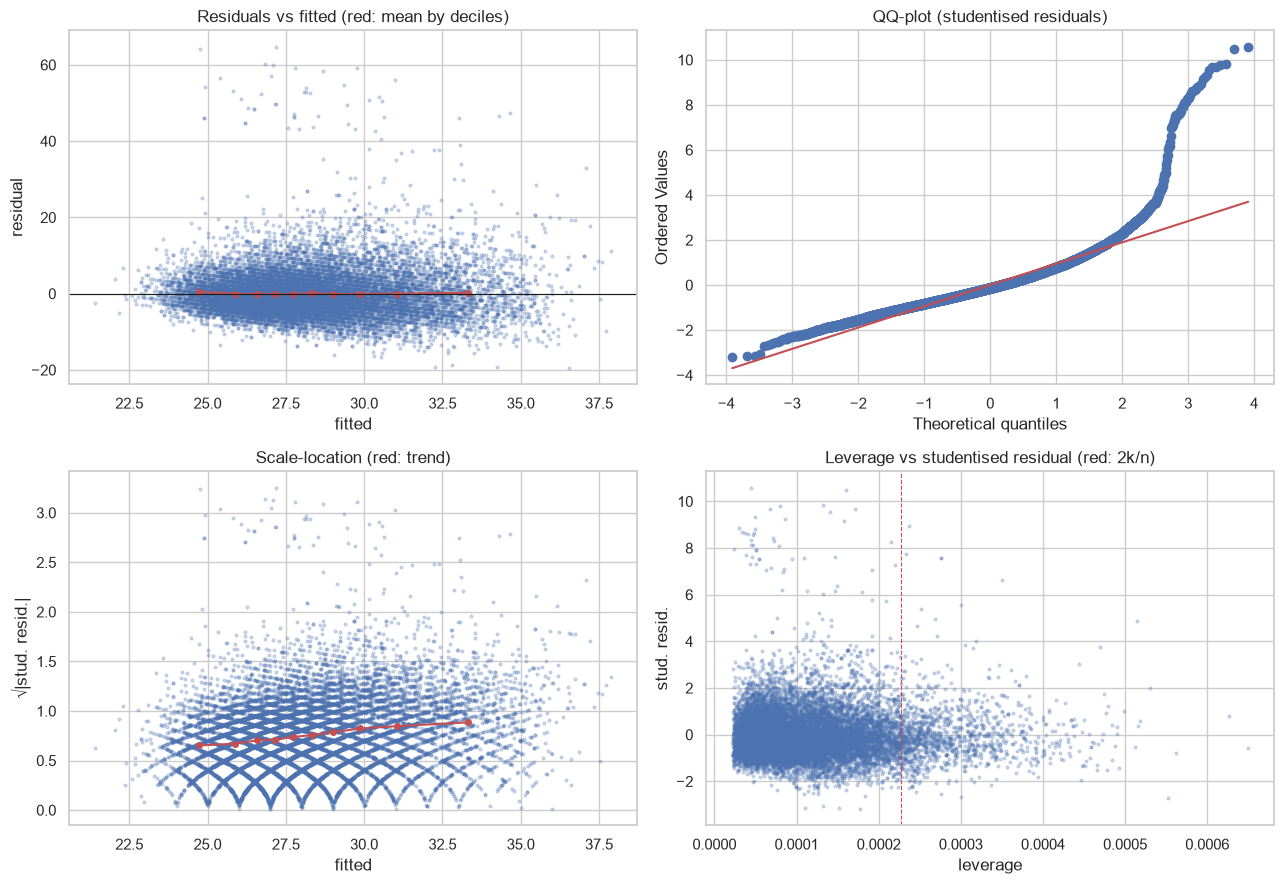

Residuals: skewness = 2.42 | excess kurtosis = 15.41 (0 = normal)
corr(|residual|, fitted) = 0.182  (≠0 suggests heteroscedasticity)
Profiles with |stud. resid.| > 3: 2181 of 183824 (1.19 %)
Max Cook's distance = 0.002 (alert if > 1) | profiles with D > 4/n_eff: 10680


In [27]:
res, s = fit_full['res'], fit_full['rse']
fitted = y_tr - res
X1, inv = fit_full['X1'], fit_full['inv']
h = np.einsum('ij,jk,ik->i', X1, inv, X1)                  # leverage of each observation (copy) i
r_stud = res / (s * np.sqrt(1 - h))                          # internally studentised residual
cook = r_stud ** 2 / fit_full['k'] * h / (1 - h)

idx = rng_reg.choice(len(res), 15000, p=w_tr / w_tr.sum())

def mean_by_deciles(x, y_):
    g = pd.qcut(x, 10, duplicates='drop')
    m = pd.DataFrame({'x': x, 'y': y_}).groupby(g, observed=True).mean()
    return m['x'], m['y']

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax[0, 0].scatter(fitted[idx], res[idx], s=4, alpha=.25)
mx, my = mean_by_deciles(fitted[idx], res[idx]); ax[0, 0].plot(mx, my, 'r-o', ms=4)
ax[0, 0].axhline(0, c='k', lw=.8); ax[0, 0].set(title='Residuals vs fitted (red: mean by deciles)', xlabel='fitted', ylabel='residual')

stats.probplot(r_stud[idx], dist='norm', plot=ax[0, 1]); ax[0, 1].set_title('QQ-plot (studentised residuals)')

ax[1, 0].scatter(fitted[idx], np.sqrt(np.abs(r_stud[idx])), s=4, alpha=.25)
mx, my = mean_by_deciles(fitted[idx], np.sqrt(np.abs(r_stud[idx]))); ax[1, 0].plot(mx, my, 'r-o', ms=4)
ax[1, 0].set(title='Scale-location (red: trend)', xlabel='fitted', ylabel='√|stud. resid.|')

ax[1, 1].scatter(h[idx], r_stud[idx], s=4, alpha=.25)
ax[1, 1].axvline(2 * fit_full['k'] / fit_full['n_eff'], c='r', ls='--', lw=.8)
ax[1, 1].set(title='Leverage vs studentised residual (red: 2k/n)', xlabel='leverage', ylabel='stud. resid.')
plt.tight_layout(); plt.show()

print(f"Residuals: skewness = {stats.skew(r_stud[idx]):.2f} | excess kurtosis = {stats.kurtosis(r_stud[idx]):.2f} (0 = normal)")
print(f"corr(|residual|, fitted) = {np.corrcoef(np.abs(res[idx]), fitted[idx])[0, 1]:.3f}  (≠0 suggests heteroscedasticity)")
print(f"Profiles with |stud. resid.| > 3: {(np.abs(r_stud) > 3).sum()} of {len(res)} ({(np.abs(r_stud) > 3).mean()*100:.2f} %)")
print(f"Max Cook's distance = {cook.max():.3f} (alert if > 1) | profiles with D > 4/n_eff: {(cook > 4 / fit_full['n_eff']).sum()}")

In [28]:
# VIF = diagonal of the inverse of the (weighted) correlation matrix. Rule: > 5-10 is problematic.
Xv = X_tr.to_numpy(float)
Cv = np.cov(Xv.T, fweights=w_tr.astype(int))
R = Cv / np.sqrt(np.outer(np.diag(Cv), np.diag(Cv)))
vif = pd.Series(np.diag(np.linalg.inv(R)), index=X_tr.columns).sort_values(ascending=False)
print(vif.round(2).head(10))
print("\nMax VIF:", round(vif.max(), 2), "->", "no problematic collinearity" if vif.max() < 5 else "review")

GenHlth      1.80
PhysHlth     1.62
DiffWalk     1.52
Income       1.50
Age          1.33
Education    1.33
HighBP       1.32
MentHlth     1.24
HighChol     1.18
Diab         1.18
dtype: float64

Max VIF: 1.8 -> no problematic collinearity


## 2.6 Model improvements, compared by cross-validation
Each variant is added **on its own** to the base model and compared with it by **5-fold CV inside *train*** (weighted metrics, original BMI scale):

| Variant | Reason (where it came from) |
|---|---|
| without `Diabetes_012` | ablation: how much does it add? |
| `log(BMI)` | heavy right tail / funnel (EDA §1.4 and diagnostics above). **Care:** back-transforming `exp(ŷ)` is biased → Duan's *smearing* factor is applied |
| splines on `Age` | non-linear relation (EDA §1.10) → H7 |
| binning `MentHlth`/`PhysHlth` | excess of zeros and ceiling at 30 (EDA §1.4) |
| interactions | **short list fixed a priori** (not all pairs, to avoid fishing) — motivated by EDA §1.11 |
| HGB | non-linear ceiling: "how much *can* be explained?" |

**Rule to keep an improvement:** it must reduce RMSE by **more than 1 standard error** of the paired difference across folds (not by a p-value, which would always be "significant").

In [29]:
INTER = [('Age', 'Sex'), ('Age', 'PhysActivity'), ('Sex', 'Income'), ('GenHlth', 'DiffWalk')]   # a priori; edit if you wish

def build_X(d, with_diab=True, bins=False, inter=()):
    X = design(d, with_diab)
    if bins:
        for c in ['MentHlth', 'PhysHlth']:
            X[c + '_0'] = (d[c] == 0).astype(float)
            X[c + '_14plus'] = (d[c] >= 14).astype(float)
    for a, b in inter:
        X[f'{a}x{b}'] = d[a] * d[b]
    return X

def make_model(spec):
    if spec.get('model') == 'hgb':
        est = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, random_state=SEED)
        return Pipeline([('model', est)])
    prep = (ColumnTransformer([('age', SplineTransformer(n_knots=5, degree=3, include_bias=False), ['Age'])],
                              remainder='passthrough') if spec.get('age_spline') else 'passthrough')
    return Pipeline([('prep', prep), ('model', LinearRegression())])

def fit_predict(spec, d_fit, d_pred):
    y = d_fit[YN].to_numpy(float); w = d_fit['w'].to_numpy(float)
    if spec.get('model') == 'null':
        return np.full(len(d_pred), wmean(y, w))
    xa = dict(with_diab=spec.get('with_diab', True), bins=spec.get('bins', False), inter=spec.get('inter', ()))
    Xf, Xp = build_X(d_fit, **xa), build_X(d_pred, **xa)
    m = make_model(spec)
    if spec.get('log'):
        m.fit(Xf, np.log(y), model__sample_weight=w)
        smear = wmean(np.exp(np.log(y) - m.predict(Xf)), w)           # Duan's smearing factor
        return np.exp(m.predict(Xp)) * smear
    m.fit(Xf, y, model__sample_weight=w)
    return m.predict(Xp)

def cv_eval_reg(spec, data=df_train, k=5):
    out = []
    for tr, va in KFold(k, shuffle=True, random_state=SEED).split(data):
        dtr, dva = data.iloc[tr], data.iloc[va]
        out.append(metrics_reg(dva[YN].to_numpy(float), fit_predict(spec, dtr, dva), dva['w'].to_numpy(float)))
    return pd.DataFrame(out)

variants = {
    'Null (weighted mean)':     dict(model='null'),
    'Linear (base)':            dict(),
    'Linear without Diabetes_012': dict(with_diab=False),
    '+ log(BMI)':               dict(log=True),
    '+ splines on Age':         dict(age_spline=True),
    '+ binning Ment/PhysHlth':  dict(bins=True),
    '+ interactions':           dict(inter=INTER),
    'HGB (non-linear ceiling)': dict(model='hgb'),
}
cv_res = {n: cached(f"reg_cv_{n}", lambda sp=sp: cv_eval_reg(sp), sig=f"{sp!r}|{len(df_train)}") for n, sp in variants.items()}

def summarise_cv(cv_res, base='Linear (base)'):
    rows = []
    for n, r in cv_res.items():
        d = cv_res[base]['RMSE'] - r['RMSE']                      # >0 = improvement over the base
        se = d.std(ddof=1) / np.sqrt(len(d))
        rows.append(dict(model=n, RMSE=r['RMSE'].mean(), RMSE_sd=r['RMSE'].std(ddof=1),
                         MAE=r['MAE'].mean(), R2=r['R2'].mean(),
                         dRMSE_vs_base=d.mean(), SE_diff=se, improves_1SE=bool(d.mean() > se)))
    return pd.DataFrame(rows).set_index('model')

summary_reg = summarise_cv(cv_res)
with pd.option_context('display.float_format', '{:.4f}'.format):
    print(summary_reg)

                              RMSE  RMSE_sd    MAE      R2  dRMSE_vs_base  \
model                                                                       
Null (weighted mean)        6.5966   0.0512 4.7442 -0.0000        -0.4777   
Linear (base)               6.1189   0.0453 4.3229  0.1395         0.0000   
Linear without Diabetes_012 6.1784   0.0427 4.3732  0.1227        -0.0595   
+ log(BMI)                  6.1220   0.0455 4.3168  0.1387        -0.0031   
+ splines on Age            6.0708   0.0464 4.2838  0.1530         0.0482   
+ binning Ment/PhysHlth     6.1177   0.0446 4.3218  0.1399         0.0012   
+ interactions              6.1021   0.0443 4.3066  0.1443         0.0168   
HGB (non-linear ceiling)    5.9658   0.0476 4.1816  0.1821         0.1532   

                             SE_diff  improves_1SE  
model                                               
Null (weighted mean)          0.0051         False  
Linear (base)                 0.0000         False  
Linear without Di

In [30]:
# Final specification = base + every improvement (of the 4 candidates) that beats 1 SE of the paired difference
candidates = {'+ log(BMI)': dict(log=True), '+ splines on Age': dict(age_spline=True),
              '+ binning Ment/PhysHlth': dict(bins=True), '+ interactions': dict(inter=INTER)}
spec_final = {}
for n, sp in candidates.items():
    if summary_reg.loc[n, 'improves_1SE']:
        spec_final.update(sp)
print("Improvements kept:", spec_final if spec_final else "none (the base model is kept)")

cv_res['Final (base + improvements)'] = cached("reg_cv_final", lambda: cv_eval_reg(spec_final), sig=f"{spec_final!r}|{len(df_train)}")
summary_reg = summarise_cv(cv_res)
with pd.option_context('display.float_format', '{:.4f}'.format):
    print(summary_reg.loc[['Linear (base)', 'Final (base + improvements)', 'HGB (non-linear ceiling)']])

Improvements kept: {'age_spline': True, 'bins': True, 'inter': [('Age', 'Sex'), ('Age', 'PhysActivity'), ('Sex', 'Income'), ('GenHlth', 'DiffWalk')]}
                              RMSE  RMSE_sd    MAE     R2  dRMSE_vs_base  \
model                                                                      
Linear (base)               6.1189   0.0453 4.3229 0.1395         0.0000   
Final (base + improvements) 6.0529   0.0447 4.2674 0.1580         0.0660   
HGB (non-linear ceiling)    5.9658   0.0476 4.1816 0.1821         0.1532   

                             SE_diff  improves_1SE  
model                                               
Linear (base)                 0.0000         False  
Final (base + improvements)   0.0012          True  
HGB (non-linear ceiling)      0.0061          True  


## 2.7 Variable selection: filter, wrapper, embedded
The three families from the course, applied to the base model (22 predictors incl. the two diabetes dummies):

- **Filter:** univariate |correlation| with BMI (§2.2) — cheap, but blind to redundancy.
- **Wrapper:** **forward selection** driven by CV RMSE, choosing the size with the **1-SE rule** (the smallest model within one standard error of the best).
- **Embedded:** **Lasso** with λ chosen by CV (also 1-SE) and, as a non-linear contrast, **permutation importance** of HGB.

All with the weights `w`. This is the regression analogue of **H4** ("≤ 10 variables keep almost all the performance").

Minimum RMSE with 19 variables; 1-SE rule -> 10 variables
Entry order: ['GenHlth', 'Diab', 'HighBP', 'Age', 'DiffWalk', 'PhysActivity', 'Prediab', 'PhysHlth', 'Fruits', 'HvyAlcoholConsump', 'Stroke', 'Sex', 'Smoker', 'HighChol', 'HeartDiseaseorAttack', 'Education', 'Income', 'CholCheck', 'NoDocbcCost', 'AnyHealthcare', 'Veggies', 'MentHlth']
Selected (1 SE): ['GenHlth', 'Diab', 'HighBP', 'Age', 'DiffWalk', 'PhysActivity', 'Prediab', 'PhysHlth', 'Fruits', 'HvyAlcoholConsump']
RMSE with 10 vars = 6.1377 | with all = 6.1189 | loss = 0.0188


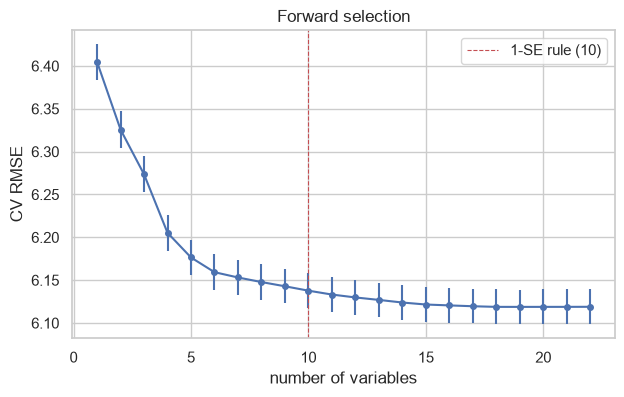

In [31]:
# ---------- Wrapper: forward selection with CV (weighted normal equations, fast) ----------
def forward_cv(X, y, w, k=5):
    Xn = X.to_numpy(float); n, p = Xn.shape
    X1 = np.column_stack([np.ones(n), Xn])
    folds = list(KFold(k, shuffle=True, random_state=SEED).split(X1))
    G = [X1[tr].T @ (X1[tr] * w[tr, None]) for tr, _ in folds]
    b = [X1[tr].T @ (w[tr] * y[tr]) for tr, _ in folds]
    Xva = [X1[va] for _, va in folds]
    def rmse_folds(S):
        o = []
        for f, (tr, va) in enumerate(folds):
            beta = np.linalg.solve(G[f][np.ix_(S, S)], b[f][S])
            e = y[va] - Xva[f][:, S] @ beta
            o.append(np.sqrt(np.sum(w[va] * e ** 2) / w[va].sum()))
        return np.array(o)
    S, rest, path = [0], list(range(1, p + 1)), []
    while rest:
        cand = [(j, rmse_folds(S + [j])) for j in rest]
        j, r = min(cand, key=lambda t: t[1].mean())
        S.append(j); rest.remove(j)
        path.append(dict(step=len(path) + 1, variable=X.columns[j - 1], RMSE=r.mean(), SE=r.std(ddof=1) / np.sqrt(k)))
    return pd.DataFrame(path)

fw = forward_cv(X_tr, y_tr, w_tr)
m_min = fw['RMSE'].idxmin()
threshold = fw.loc[m_min, 'RMSE'] + fw.loc[m_min, 'SE']
n_1se = int(fw.index[fw['RMSE'] <= threshold][0]) + 1
fw_order = list(fw['variable'])
print(f"Minimum RMSE with {m_min + 1} variables; 1-SE rule -> {n_1se} variables")
print("Entry order:", fw_order)
print("Selected (1 SE):", fw_order[:n_1se])
print(f"RMSE with {n_1se} vars = {fw.loc[n_1se-1, 'RMSE']:.4f} | with all = {fw['RMSE'].iloc[-1]:.4f} | "
      f"loss = {fw.loc[n_1se-1, 'RMSE'] - fw['RMSE'].iloc[-1]:.4f}")

plt.figure(figsize=(7, 4))
plt.errorbar(fw['step'], fw['RMSE'], yerr=fw['SE'], fmt='-o', ms=4)
plt.axvline(n_1se, c='r', ls='--', lw=.8, label=f'1-SE rule ({n_1se})')
plt.xlabel('number of variables'); plt.ylabel('CV RMSE'); plt.title('Forward selection'); plt.legend(); plt.show()

λ_min = 0.003746 (RMSE 6.1189) | λ_1SE = 0.08884 (RMSE 6.1320)
Lasso (1 SE) keeps 17 of 22 variables
Set to zero: ['Veggies', 'AnyHealthcare', 'NoDocbcCost', 'MentHlth', 'Income']


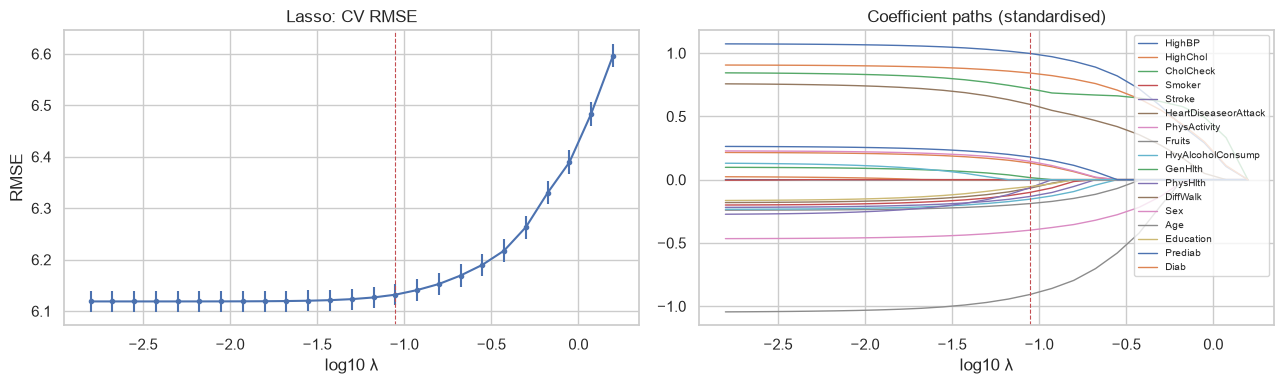

In [32]:
# ---------- Embedded: Lasso with lambda by CV (1-SE rule) ----------
Xn = X_tr.to_numpy(float)
mu_x = np.average(Xn, axis=0, weights=w_tr)
sd_x = np.sqrt(np.average((Xn - mu_x) ** 2, axis=0, weights=w_tr))
Xz = (Xn - mu_x) / sd_x                                         # weighted standardisation (full train)
wn = w_tr * len(w_tr) / w_tr.sum()
alpha_max = np.max(np.abs(Xz.T @ (wn * (y_tr - wmean(y_tr, w_tr))))) / len(y_tr)
alphas = np.logspace(np.log10(alpha_max), np.log10(alpha_max * 1e-3), 25)

def rmse_w(y, p, w): return np.sqrt(np.sum(w * (y - p) ** 2) / w.sum())
cv_l = np.zeros((5, len(alphas)))
for f, (tr, va) in enumerate(KFold(5, shuffle=True, random_state=SEED).split(Xz)):
    m = Lasso(alpha=alphas[0], warm_start=True, max_iter=3000, tol=1e-4)
    for i, a in enumerate(alphas):
        m.set_params(alpha=a); m.fit(Xz[tr], y_tr[tr], sample_weight=w_tr[tr])
        cv_l[f, i] = rmse_w(y_tr[va], m.predict(Xz[va]), w_tr[va])
mean_l, se_l = cv_l.mean(0), cv_l.std(0, ddof=1) / np.sqrt(5)
i_min = int(mean_l.argmin()); i_1se = int(np.where(mean_l <= mean_l[i_min] + se_l[i_min])[0][0])   # largest alpha within 1 SE

coefs = []
m = Lasso(alpha=alphas[0], warm_start=True, max_iter=3000, tol=1e-4)
for a in alphas:
    m.set_params(alpha=a); m.fit(Xz, y_tr, sample_weight=w_tr); coefs.append(m.coef_.copy())
coefs = np.array(coefs)
lasso_1se = pd.Series(coefs[i_1se], index=X_tr.columns)
print(f"λ_min = {alphas[i_min]:.4g} (RMSE {mean_l[i_min]:.4f}) | λ_1SE = {alphas[i_1se]:.4g} (RMSE {mean_l[i_1se]:.4f})")
print("Lasso (1 SE) keeps", int((lasso_1se != 0).sum()), "of", len(lasso_1se), "variables")
print("Set to zero:", list(lasso_1se.index[lasso_1se == 0]))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].errorbar(np.log10(alphas), mean_l, yerr=se_l, fmt='-o', ms=3)
ax[0].axvline(np.log10(alphas[i_1se]), c='r', ls='--', lw=.8); ax[0].set(title='Lasso: CV RMSE', xlabel='log10 λ', ylabel='RMSE')
for j, c in enumerate(X_tr.columns): ax[1].plot(np.log10(alphas), coefs[:, j], lw=1, label=c if lasso_1se[c] != 0 else None)
ax[1].legend(fontsize=7, loc='upper right')
ax[1].axvline(np.log10(alphas[i_1se]), c='r', ls='--', lw=.8); ax[1].set(title='Coefficient paths (standardised)', xlabel='log10 λ')
plt.tight_layout(); plt.show()

In [33]:
# ---------- Non-linear contrast: permutation importance with HGB (hold-out inside train) ----------
perm_idx = rng_reg.permutation(len(df_train)); cut = int(.8 * len(perm_idx))
a_, b_ = perm_idx[:cut], perm_idx[cut:]
hgb_reg = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, random_state=SEED)
hgb_reg.fit(X_tr.iloc[a_], y_tr[a_], sample_weight=w_tr[a_])
pi_reg = permutation_importance(hgb_reg, X_tr.iloc[b_], y_tr[b_], sample_weight=w_tr[b_],
                                scoring='neg_root_mean_squared_error', n_repeats=3, random_state=SEED)
imp_hgb = pd.Series(pi_reg.importances_mean, index=X_tr.columns)

# ---------- Comparison of rankings ----------
rank = pd.DataFrame({
    'filter |r|':        r_w.reindex(X_tr.columns).abs().rank(ascending=False),
    'forward (order)':   pd.Series({v: i + 1 for i, v in enumerate(fw_order)}),
    'lasso |coef|':      lasso_1se.abs().rank(ascending=False).where(lasso_1se != 0, len(lasso_1se) + 1),
    'HGB permutation':   imp_hgb.rank(ascending=False)}).loc[X_tr.columns]
rank['median'] = rank.median(axis=1)
print(rank.sort_values('median').round(1))
print("\nAgreement between methods (Spearman of the rankings):")
print(rank.drop(columns='median').corr(method='spearman').round(2))

                      filter |r|  forward (order)  lasso |coef|  \
GenHlth                      1.0                1           4.0   
HighBP                       3.0                3           1.0   
Diab                         2.0                2           3.0   
Age                         18.0                4           2.0   
DiffWalk                     4.0                5           5.0   
PhysActivity                 5.0                6           6.0   
Fruits                      10.0                9           7.0   
Prediab                     16.0                7           8.0   
HvyAlcoholConsump           15.0               10           9.0   
Sex                         17.0               12          10.0   
PhysHlth                     6.0                8          15.0   
Education                    8.0               16          16.0   
HighChol                     7.0               14          12.0   
Smoker                      22.0               13          13.

> **What to look for:** variables that **all** methods keep are *robust*; those that appear in only one *depend on the method*. The filter cannot see redundancy; wrapper and lasso can. Comparing rankings is the "argued" answer to *which variables matter*.

## 2.8 KNN vs linear regression as *p* grows
With very few predictors a flexible method such as KNN can beat the linear model, but as *p* grows the curse of dimensionality hurts KNN and the linear model wins.

KNN does not accept weights, so *train* is split in two **by profile** and each part is **resampled with probability ∝ `w`**: the data then reflect the population and no profile is repeated between fit and validation. The best *k* is picked **on the validation part** — an advantage given to KNN on purpose: if it still loses, the conclusion is solid.

    RMSE_linear  RMSE_KNN  k_KNN
p                               
1        6.1590    6.1319    400
2        6.0751    6.0363    400
3        6.0246    5.9889    400
4        5.9470    5.8688    400
6        5.9170    5.8332    150
10       5.8965    5.8621    150
22       5.8808    5.8896    150


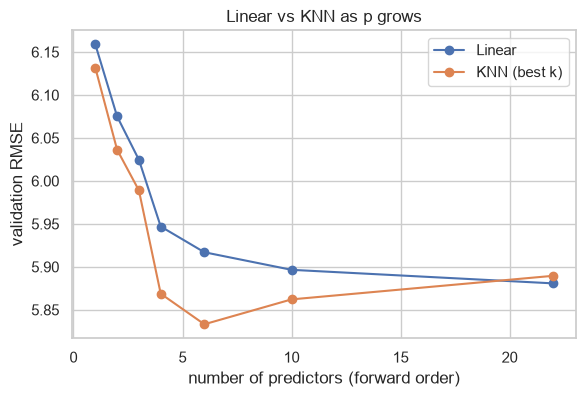

In [34]:
perm = rng_reg.permutation(len(df_train)); cut = int(.8 * len(perm))
ia, ib = perm[:cut], perm[cut:]
def resample(ix, n): return rng_reg.choice(ix, size=n, p=w_tr[ix] / w_tr[ix].sum())
idx_A, idx_B = resample(ia, 20000), resample(ib, 8000)

res_knn = []
for p in [1, 2, 3, 4, 6, 10, X_tr.shape[1]]:
    cols = fw_order[:p]
    XA, XB = X_tr.iloc[idx_A][cols], X_tr.iloc[idx_B][cols]
    lin = LinearRegression().fit(XA, y_tr[idx_A])
    r_lin = np.sqrt(np.mean((y_tr[idx_B] - lin.predict(XB)) ** 2))
    best = (np.inf, None)
    for kk in [5, 15, 50, 150, 400]:
        sc = StandardScaler().fit(XA)
        kn = KNeighborsRegressor(n_neighbors=kk).fit(sc.transform(XA), y_tr[idx_A])
        r = np.sqrt(np.mean((y_tr[idx_B] - kn.predict(sc.transform(XB))) ** 2))
        if r < best[0]: best = (r, kk)
    res_knn.append(dict(p=p, RMSE_linear=r_lin, RMSE_KNN=best[0], k_KNN=best[1]))
res_knn = pd.DataFrame(res_knn).set_index('p')
print(res_knn.round(4))

plt.figure(figsize=(6.5, 4))
plt.plot(res_knn.index, res_knn['RMSE_linear'], '-o', label='Linear'); plt.plot(res_knn.index, res_knn['RMSE_KNN'], '-o', label='KNN (best k)')
plt.xlabel('number of predictors (forward order)'); plt.ylabel('validation RMSE'); plt.legend(); plt.title('Linear vs KNN as p grows'); plt.show()

## 2.9 Shrinkage, dimension reduction and information criteria
§2.7 selected a **subset** of variables. There are two other classical ways to control the variance of a linear model, both from the course chapter on linear model selection and regularisation:

| Method | Idea | Supervised? |
|---|---|---|
| **Ridge** | keep all variables but shrink the coefficients (L2 penalty); correlated predictors share the effect | – |
| **PCR** (principal components regression) | regress on the first *m* principal components of the predictors | **no**: components ignore `y` |
| **PLS** (partial least squares) | like PCR but the components are built to **covary with `y`** | **yes** |

**H9, fixed before running this block:** with *p* = 22 predictors and ~184,000 profiles the variance of plain OLS is already tiny, so none of the three should improve CV RMSE by more than **0.01 BMI units**. The point of the block is to *check* that, not to hope for a gain; and to show how the tuning parameter (α, number of components) is chosen — by CV with the 1-SE rule, never with test.

In [35]:
def w_standardise(Xa, w):
    mu = np.average(Xa, axis=0, weights=w)
    sd = np.sqrt(np.average((Xa - mu) ** 2, axis=0, weights=w)); sd[sd == 0] = 1.0
    return mu, sd

def pcr_path(Z, y, w, max_comp):
    # Weighted PCR. Z must be weighted-centred. Returns (intercept, B) with B[m-1] = coefficients using the first m components.
    ybar = wmean(y, w); yc = y - ybar
    C = (Z * w[:, None]).T @ Z / w.sum()                       # weighted covariance of the standardised predictors
    lam, V = np.linalg.eigh(C); o = np.argsort(lam)[::-1]; lam, V = lam[o], V[:, o]
    T = Z @ V                                                  # component scores (weighted-orthogonal)
    gamma = (T * (w * yc)[:, None]).sum(0) / (w.sum() * lam)   # one simple regression per orthogonal component
    return ybar, np.cumsum(V * gamma, axis=1).T[:max_comp]

def pls_path(Z, y, w, max_comp):
    # Weighted PLS1 (NIPALS). B[m-1] = coefficients (standardised scale) of the model with m components.
    ybar = wmean(y, w); r = y - ybar; E = Z.copy(); Wm, P, q = [], [], []
    for _ in range(max_comp):
        wa = E.T @ (w * r); nrm = np.linalg.norm(wa)
        if nrm < 1e-12: break
        wa = wa / nrm; t = E @ wa; tt = np.sum(w * t * t)
        pa = E.T @ (w * t) / tt; qa = np.sum(w * r * t) / tt
        E = E - np.outer(t, pa); r = r - qa * t
        Wm.append(wa); P.append(pa); q.append(qa)
    Wm, P, q = np.array(Wm).T, np.array(P).T, np.array(q)
    B = np.array([(Wm[:, :m] @ np.linalg.inv(P[:, :m].T @ Wm[:, :m])) @ q[:m] for m in range(1, Wm.shape[1] + 1)])
    if len(B) < max_comp: B = np.vstack([B, np.repeat(B[-1:], max_comp - len(B), axis=0)])   # pad if it stopped early
    return ybar, B

# ---- proof of correctness: weighted == replicated rows; PLS == sklearn when w = 1 ----
s_ = df_train.sample(800, random_state=SEED)
Xs_, ys_, ws_ = design(s_).to_numpy(float), s_[YN].to_numpy(float), s_['w'].to_numpy(float)
rep_ = np.repeat(np.arange(len(s_)), ws_.astype(int)); one_ = np.ones(len(rep_))
mu1, sd1 = w_standardise(Xs_, ws_); mu2, sd2 = w_standardise(Xs_[rep_], one_)
Zw_, Zr_ = (Xs_ - mu1) / sd1, (Xs_[rep_] - mu2) / sd2
for fn in (pcr_path, pls_path):
    a1, B1 = fn(Zw_, ys_, ws_, 6); a2, B2 = fn(Zr_, ys_[rep_], one_, 6)
    assert np.isclose(a1, a2) and np.allclose(B1, B2, atol=1e-8), fn.__name__
a_, B_ = pls_path(Zr_, ys_[rep_], one_, 3)
assert np.allclose(PLSRegression(3, scale=False).fit(Zr_, ys_[rep_]).predict(Zr_).ravel(), a_ + Zr_ @ B_[2], atol=1e-6)
a_, B_ = pcr_path(Zr_, ys_[rep_], one_, 3)
T3_ = PCA(3, svd_solver="full").fit_transform(Zr_)          # solver exacto: el 'auto' es aleatorizado con > 500 filas
assert np.allclose(LinearRegression().fit(T3_, ys_[rep_]).predict(T3_), a_ + Zr_ @ B_[2], atol=1e-6)
print("OK: weighted PCR/PLS == replicated rows; PLS == sklearn PLSRegression (w = 1)")




OK: weighted PCR/PLS == replicated rows; PLS == sklearn PLSRegression (w = 1)


            tuning  at_min_CV      at_1SE  RMSE_min  RMSE_1SE
method                                                       
ridge        alpha      100.0  31622.7766    6.1189    6.1309
pcr     components       22.0     20.0000    6.1189    6.1324
pls     components        9.0      2.0000    6.1189    6.1307

Paired comparison with plain OLS (same folds):
                 RMSE     R2  dRMSE_vs_base  SE_diff  improves_1SE
model                                                             
Linear (base)  6.1189 0.1395         0.0000   0.0000         False
RIDGE (1-SE)   6.1309 0.1362        -0.0120   0.0012         False
RIDGE (min CV) 6.1189 0.1395         0.0000   0.0000         False
PCR (1-SE)     6.1324 0.1357        -0.0135   0.0010         False
PCR (min CV)   6.1189 0.1395        -0.0000   0.0000         False
PLS (1-SE)     6.1307 0.1362        -0.0118   0.0008         False
PLS (min CV)   6.1189 0.1395         0.0000   0.0000         False


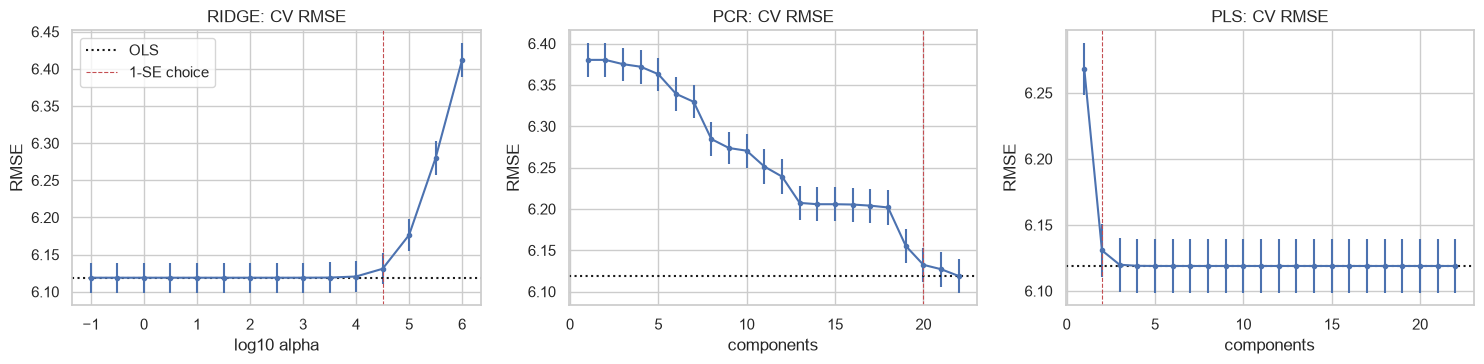

In [36]:
RIDGE_ALPHAS = np.logspace(-1, 6, 15); NCOMP = X_tr.shape[1]
Xarr = X_tr.to_numpy(float)

def shrink_cv():
    folds = list(KFold(5, shuffle=True, random_state=SEED).split(Xarr))      # SAME folds as cv_eval_reg -> paired differences
    out = {m: {k: np.zeros((5, L)) for k in ("RMSE", "MAE", "R2")} for m, L in
           [("ridge", len(RIDGE_ALPHAS)), ("pcr", NCOMP), ("pls", NCOMP)]}
    for f, (tr, va) in enumerate(folds):
        mu, sd = w_standardise(Xarr[tr], w_tr[tr]); Ztr, Zva = (Xarr[tr] - mu) / sd, (Xarr[va] - mu) / sd
        P = {"ridge": np.column_stack([Ridge(alpha=a).fit(Ztr, y_tr[tr], sample_weight=w_tr[tr]).predict(Zva) for a in RIDGE_ALPHAS])}
        a0, B = pcr_path(Ztr, y_tr[tr], w_tr[tr], NCOMP); P["pcr"] = a0 + Zva @ B.T
        a0, B = pls_path(Ztr, y_tr[tr], w_tr[tr], NCOMP); P["pls"] = a0 + Zva @ B.T
        for m, Pm in P.items():
            for j in range(Pm.shape[1]):
                mt = metrics_reg(y_tr[va], Pm[:, j], w_tr[va])
                for k_ in ("RMSE", "MAE", "R2"): out[m][k_][f, j] = mt[k_]
    return out

shr = cached("reg_shrink_cv", shrink_cv, sig=f"{RIDGE_ALPHAS}|{NCOMP}|{len(df_train)}")

def pick(arr, parsimony):          # min-CV index and 1-SE index. parsimony: 'max' (ridge: largest alpha) or 'min' (fewest comps)
    m, se = arr.mean(0), arr.std(0, ddof=1) / np.sqrt(arr.shape[0])
    i_min = int(m.argmin()); ok = np.where(m <= m[i_min] + se[i_min])[0]
    return i_min, int(ok.max() if parsimony == 'max' else ok.min()), m, se

rows, chosen_shr, cv_shr = [], {}, {}
for meth, par, grid, label in [("ridge", 'max', RIDGE_ALPHAS, "alpha"), ("pcr", 'min', np.arange(1, NCOMP + 1), "components"),
                               ("pls", 'min', np.arange(1, NCOMP + 1), "components")]:
    i_min, i_1se, m, se = pick(shr[meth]["RMSE"], par)
    chosen_shr[meth] = dict(min=i_min, one_se=i_1se, grid=grid)
    cv_shr[meth.upper() + " (1-SE)"] = pd.DataFrame({k: shr[meth][k][:, i_1se] for k in ("RMSE", "MAE", "R2")})
    cv_shr[meth.upper() + " (min CV)"] = pd.DataFrame({k: shr[meth][k][:, i_min] for k in ("RMSE", "MAE", "R2")})
    rows.append(dict(method=meth, tuning=label, at_min_CV=grid[i_min], at_1SE=grid[i_1se], RMSE_min=m[i_min], RMSE_1SE=m[i_1se]))
print(pd.DataFrame(rows).set_index("method").round(4))

cmp_shr = summarise_cv({'Linear (base)': cv_res['Linear (base)'], **cv_shr}, base='Linear (base)')
with pd.option_context('display.float_format', '{:.4f}'.format):
    print("\nPaired comparison with plain OLS (same folds):"); print(cmp_shr[['RMSE', 'R2', 'dRMSE_vs_base', 'SE_diff', 'improves_1SE']])

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (meth, xs, xl) in zip(ax, [("ridge", np.log10(RIDGE_ALPHAS), "log10 alpha"), ("pcr", np.arange(1, NCOMP + 1), "components"),
                                  ("pls", np.arange(1, NCOMP + 1), "components")]):
    m, se = shr[meth]["RMSE"].mean(0), shr[meth]["RMSE"].std(0, ddof=1) / np.sqrt(5)
    a.errorbar(xs, m, yerr=se, fmt='-o', ms=3); a.axhline(cv_res['Linear (base)']['RMSE'].mean(), c='k', ls=':', label='OLS')
    a.axvline(xs[chosen_shr[meth]['one_se']], c='r', ls='--', lw=.8, label='1-SE choice'); a.set(title=f"{meth.upper()}: CV RMSE", xlabel=xl, ylabel="RMSE")
    if meth == 'ridge': a.legend()
plt.tight_layout(); plt.show()

Best size by criterion: {'AIC': 19, 'BIC': 18, 'Cp': 19, 'adj. R²': 19, 'CV 1-SE (§2.7)': 10}


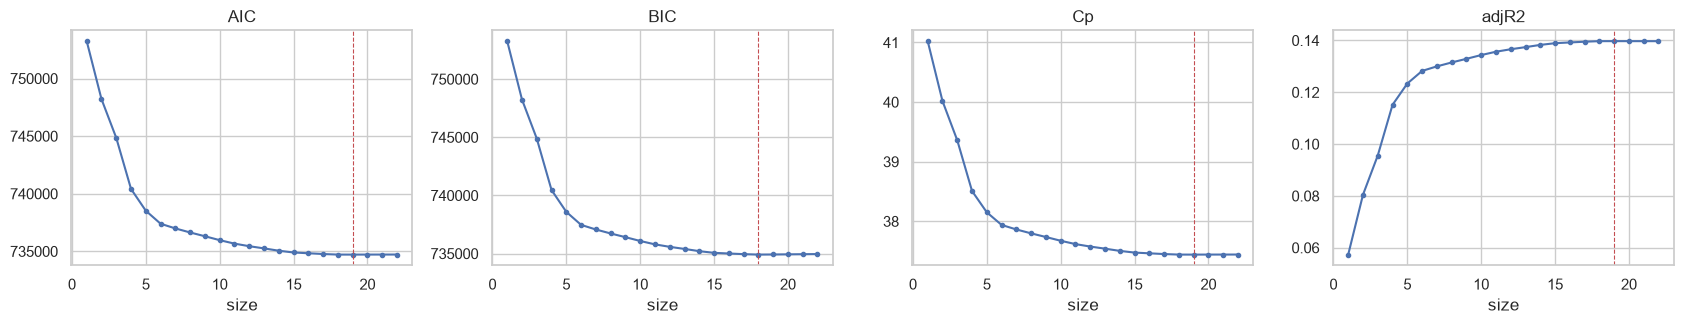

In [37]:
n_eff = w_tr.sum(); tss_ = np.sum(w_tr * (y_tr - wmean(y_tr, w_tr)) ** 2); sig2_full = fit_full['rse'] ** 2
ic = []
for m_ in range(1, len(fw_order) + 1):
    cols = fw_order[:m_]; f_ = ols_fw(X_tr[cols], y_tr, w_tr, cols); rss = (1 - f_['r2']) * tss_; d_ = m_
    ic.append(dict(size=m_, AIC=n_eff * np.log(rss / n_eff) + 2 * (d_ + 1), BIC=n_eff * np.log(rss / n_eff) + (d_ + 1) * np.log(n_eff),
                   Cp=(rss + 2 * d_ * sig2_full) / n_eff, adjR2=f_['r2adj']))
ic = pd.DataFrame(ic).set_index('size')
best_size = {'AIC': int(ic['AIC'].idxmin()), 'BIC': int(ic['BIC'].idxmin()), 'Cp': int(ic['Cp'].idxmin()),
             'adj. R²': int(ic['adjR2'].idxmax()), 'CV 1-SE (§2.7)': n_1se}
print("Best size by criterion:", best_size)

fig, ax = plt.subplots(1, 4, figsize=(17, 3.4))
for a, c in zip(ax, ['AIC', 'BIC', 'Cp', 'adjR2']):
    ic[c].plot(marker='o', ms=3, ax=a, title=c); a.axvline(ic[c].idxmax() if c == 'adjR2' else ic[c].idxmin(), c='r', ls='--', lw=.8)
plt.tight_layout(); plt.show()

In [38]:
# ---------- Verdict on H9 ----------
gain_best = max(cmp_shr.loc[[n for n in cmp_shr.index if "min CV" in n], 'dRMSE_vs_base'])      # most favourable choice for each method
VERDICT['H9'] = (gain_best < 0.01, f"best RMSE gain of ridge/PCR/PLS over OLS = {gain_best:+.4f} BMI units (criterion < 0.01)")
ok, msg = VERDICT['H9']; print("H9 ·", "HOLDS    " if ok else "DOES NOT HOLD", "·", msg)

H9 · HOLDS     · best RMSE gain of ridge/PCR/PLS over OLS = +0.0000 BMI units (criterion < 0.01)


## 2.10 Non-linear regressors: polynomial, additive splines, model tree, tree, random forest, boosting
So far the "non-linear ceiling" was a single HGB. Here is the ladder from the course chapters on moving beyond linearity and on trees, from *interpretable* to *flexible*:

| Model | What it adds | Why it is here |
|---|---|---|
| **Polynomial** (degree 2–4) on the ordinal/count predictors | global curvature | the simplest non-linearity; the risk is wild behaviour at the edges |
| **Additive spline model** (GAM-like): a spline per ordinal predictor + a ridge penalty | a *smooth, interpretable* curve per variable, no interactions | the practical GAM: each predictor keeps its own shape. Fitted with penalised B-splines because the true GAM packages are not required |
| **Model tree** (M5-style): a small tree partitions the data and each leaf has its **own linear model** | piecewise-linear + interactions, still readable | the "model trees" notes: linear where linear works, splits where the relation changes |
| **Regression tree** | interactions, no assumptions | high variance: the reason for bagging |
| **Random forest** | bagging + random feature subsets: variance reduction; its **out-of-bag (OOB)** error is a free CV | compare OOB with CV |
| **Boosting** (HGB, tuned) | sequential trees fitted to the residuals | usually the best tabular learner |

**Computational design (stated, not hidden).** Linear-type models are fast and are cross-validated on **all of train**. Trees, forests and the boosting search are cross-validated on a **fixed random subsample of `N_REG_SUB` profiles** (with their weights), and compared against OLS and the default HGB **on that same subsample** so the comparison is fair. Everything uses the same 5-fold `KFold(seed)` and weighted metrics. The final refit of each model on all of train and its test evaluation come in §2.13.

In [39]:
NUMORD = ['Age', 'GenHlth', 'PhysHlth', 'MentHlth', 'Income', 'Education']       # ordinal / count predictors (the rest are binary)

def accepts_sw(est):
    ps = inspect.signature(est.fit).parameters
    return "sample_weight" in ps or any(p.kind is inspect.Parameter.VAR_KEYWORD for p in ps.values())

def fit_reg(model, X, y, w=None):
    # fits a Pipeline passing sample_weight to its last step when that step can use it
    m = clone(model); last_name, last = m.steps[-1]
    if w is not None and accepts_sw(last): return m.fit(X, y, **{f"{last_name}__sample_weight": w})
    return m.fit(X, y)

def cv_eval_est(est, d, name, k=5):
    X, y, w = design(d), d[YN].to_numpy(float), d['w'].to_numpy(float)
    def run():
        out = []
        for tr, va in KFold(k, shuffle=True, random_state=SEED).split(X):
            m = fit_reg(est, X.iloc[tr], y[tr], w[tr]); out.append(metrics_reg(y[va], m.predict(X.iloc[va]), w[va]))
        return pd.DataFrame(out)
    return cached(f"reg_{name}", run, sig=f"{est!r}|{len(d)}|{int(w.sum())}|{k}")

def poly_est(deg):
    pre = Pipeline([('z', StandardScaler()), ('poly', PolynomialFeatures(deg, include_bias=False))])
    return Pipeline([('prep', ColumnTransformer([('p', pre, NUMORD)], remainder='passthrough')), ('m', LinearRegression())])

def spline_est(n_knots, alpha):
    return Pipeline([('prep', ColumnTransformer([('sp', SplineTransformer(n_knots=n_knots, degree=3, include_bias=False), NUMORD)],
                                                remainder='passthrough')), ('m', Ridge(alpha=alpha))])

class LinearLeafTree(BaseEstimator, RegressorMixin):
    # Simplified M5 model tree: a regression tree defines the regions; every leaf fits its own ridge regression.
    def __init__(self, max_leaf_nodes=8, min_samples_leaf=1000, alpha=1.0):
        self.max_leaf_nodes, self.min_samples_leaf, self.alpha = max_leaf_nodes, min_samples_leaf, alpha
    def fit(self, X, y, sample_weight=None):
        X = np.asarray(X, float); y = np.asarray(y, float); w = np.ones(len(y)) if sample_weight is None else np.asarray(sample_weight, float)
        self.tree_ = DecisionTreeRegressor(max_leaf_nodes=self.max_leaf_nodes, min_samples_leaf=self.min_samples_leaf,
                                           random_state=SEED).fit(X, y, sample_weight=w)
        leaf = self.tree_.apply(X); self.global_ = Ridge(alpha=self.alpha).fit(X, y, sample_weight=w); self.leaf_ = {}
        for l in np.unique(leaf):
            m = leaf == l
            self.leaf_[l] = Ridge(alpha=self.alpha).fit(X[m], y[m], sample_weight=w[m]) if m.sum() > 2 * X.shape[1] else self.global_
        return self
    def predict(self, X):
        X = np.asarray(X, float); leaf = self.tree_.apply(X); out = np.zeros(len(X))
        for l in np.unique(leaf): out[leaf == l] = self.leaf_.get(l, self.global_).predict(X[leaf == l])
        return out

msl_full = max(50, len(df_train) // 150)                   # minimum leaf size scaled with the data
est_full = {
    **{f"Polynomial deg {d}": poly_est(d) for d in (2, 3, 4)},
    **{f"Additive splines (knots={nk}, alpha={a:g})": spline_est(nk, a) for nk in (4, 6) for a in (1, 100)},
    **{f"Model tree ({L} leaves)": Pipeline([('m', LinearLeafTree(L, msl_full))]) for L in (4, 8, 16)},
}
cv_nl = {'Linear (base)': cv_res['Linear (base)']}
for n, e in est_full.items():
    t0 = time.time(); cv_nl[n] = cv_eval_est(e, df_train, n); print(f"{n:42s} {time.time()-t0:5.1f}s  RMSE={cv_nl[n]['RMSE'].mean():.4f}")
cmp_nl = summarise_cv(cv_nl, base='Linear (base)')
with pd.option_context('display.float_format', '{:.4f}'.format):
    print(cmp_nl[['RMSE', 'MAE', 'R2', 'dRMSE_vs_base', 'SE_diff', 'improves_1SE']])

Polynomial deg 2                             2.7s  RMSE=6.0252
Polynomial deg 3                             7.4s  RMSE=6.0187
Polynomial deg 4                            14.8s  RMSE=6.0139
Additive splines (knots=4, alpha=1)          3.0s  RMSE=6.0433
Additive splines (knots=4, alpha=100)        2.9s  RMSE=6.0503
Additive splines (knots=6, alpha=1)          3.6s  RMSE=6.0433
Additive splines (knots=6, alpha=100)        3.3s  RMSE=6.0454
Model tree (4 leaves)                        2.7s  RMSE=6.0457
Model tree (8 leaves)                        3.1s  RMSE=6.0183
Model tree (16 leaves)                       3.4s  RMSE=6.0053
                                        RMSE    MAE     R2  dRMSE_vs_base  \
model                                                                       
Linear (base)                         6.1189 4.3229 0.1395         0.0000   
Polynomial deg 2                      6.0252 4.2402 0.1657         0.0937   
Polynomial deg 3                      6.0187 4.2337 0.1675    

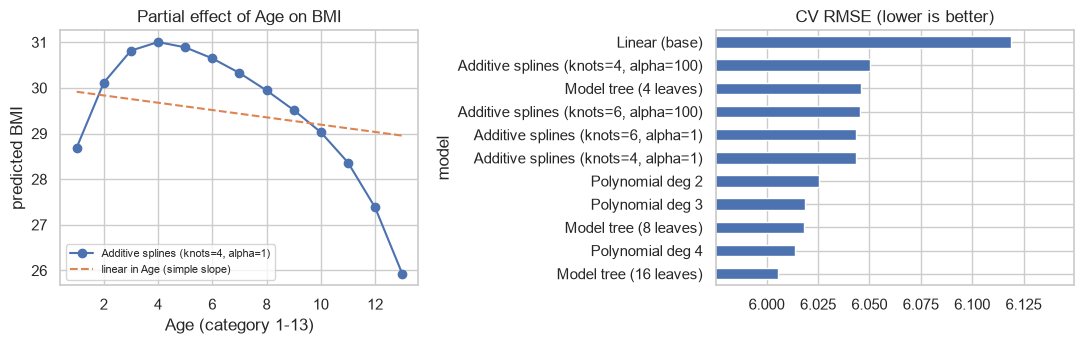

In [40]:
best_sp = min([n for n in est_full if n.startswith("Additive")], key=lambda n: cv_nl[n]['RMSE'].mean())
m_sp = fit_reg(est_full[best_sp], X_tr, y_tr, w_tr)
grid_age = np.sort(df_train['Age'].unique())
Xg = pd.DataFrame([X_tr.apply(lambda c: wmean(c.to_numpy(float), w_tr))] * len(grid_age)); Xg['Age'] = grid_age
eff_sp = m_sp.predict(Xg)
lin_ = ols_fw(X_tr[['Age']], y_tr, w_tr, ['Age'])['tab']['coef']
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(grid_age, eff_sp, 'o-', label=f'{best_sp}')
ax[0].plot(grid_age, eff_sp.mean() + lin_['Age'] * (grid_age - grid_age.mean()), '--', label='linear in Age (simple slope)')
ax[0].set(xlabel='Age (category 1-13)', ylabel='predicted BMI', title='Partial effect of Age on BMI'); ax[0].legend(fontsize=8)
cmp_nl['RMSE'].sort_values().plot(kind='barh', ax=ax[1], title='CV RMSE (lower is better)'); ax[1].set_xlim(cmp_nl['RMSE'].min() * .995, cmp_nl['RMSE'].max() * 1.005)
plt.tight_layout(); plt.show()

### Trees, random forest (with out-of-bag error) and boosting — on the fixed subsample
A single tree has high variance; **bagging** averages many trees fitted on bootstrap samples, and each tree leaves out ~37 % of the rows (**out-of-bag**, OOB). Predicting every row only with the trees that did *not* see it gives an honest error estimate **without any extra CV** 

In [41]:
rs_sub = np.random.RandomState(SEED + 7)
d_sub = df_train.iloc[np.sort(rs_sub.choice(len(df_train), min(N_REG_SUB, len(df_train)), replace=False))].reset_index(drop=True)
X_sub, y_sub, w_sub = design(d_sub), d_sub[YN].to_numpy(float), d_sub['w'].to_numpy(float)
print(f"subsample for the heavy regressors: {len(d_sub)} profiles ({int(w_sub.sum())} people)")

msl_sub = max(20, len(d_sub) // 400)
est_sub = {
    "OLS (same rows)": Pipeline([('m', LinearRegression())]),
    "HGB default": Pipeline([('m', HistGradientBoostingRegressor(max_iter=300, learning_rate=0.08, random_state=SEED))]),
    **{f"Tree (min leaf {m_})": Pipeline([('m', DecisionTreeRegressor(min_samples_leaf=m_, random_state=SEED))]) for m_ in (msl_sub, 4 * msl_sub, 16 * msl_sub)},
    "Random forest": Pipeline([('m', RandomForestRegressor(n_estimators=100 if FAST else 200, min_samples_leaf=msl_sub, max_features=0.5,
                                                          n_jobs=-1, random_state=SEED))]),
}
cv_sub = {}
for n, e in est_sub.items():
    t0 = time.time(); cv_sub[n] = cv_eval_est(e, d_sub, "sub_" + n); print(f"{n:24s} {time.time()-t0:5.1f}s  RMSE={cv_sub[n]['RMSE'].mean():.4f}")

# ---- out-of-bag error of the forest (one fit, no CV) ----
rf_oob = RandomForestRegressor(n_estimators=100 if FAST else 200, min_samples_leaf=msl_sub, max_features=0.5, bootstrap=True, oob_score=True,
                               n_jobs=-1, random_state=SEED).fit(X_sub, y_sub, sample_weight=w_sub)
ok_ = np.isfinite(rf_oob.oob_prediction_)
oob = metrics_reg(y_sub[ok_], rf_oob.oob_prediction_[ok_], w_sub[ok_])
print(f"\nRandom forest  ·  OOB RMSE = {oob['RMSE']:.4f}   vs   5-fold CV RMSE = {cv_sub['Random forest']['RMSE'].mean():.4f}")

subsample for the heavy regressors: 40000 profiles (44002 people)
OLS (same rows)            0.2s  RMSE=6.1616
HGB default                2.9s  RMSE=6.0501
Tree (min leaf 100)        0.6s  RMSE=6.1458
Tree (min leaf 400)        0.5s  RMSE=6.1405
Tree (min leaf 1600)       0.4s  RMSE=6.2345
Random forest              6.0s  RMSE=6.0751

Random forest  ·  OOB RMSE = 7.4949   vs   5-fold CV RMSE = 6.0751


In [42]:
# ---- boosting: small random search (on the subsample) ----
def tune_hgb_reg():
    search = RandomizedSearchCV(Pipeline([('m', HistGradientBoostingRegressor(random_state=SEED))]),
                                {'m__learning_rate': loguniform(0.02, 0.2), 'm__max_leaf_nodes': randint(8, 40),
                                 'm__min_samples_leaf': randint(20, 300), 'm__l2_regularization': loguniform(1e-2, 1e2),
                                 'm__max_iter': randint(100, 500)},
                                n_iter=4 if FAST else 12, scoring='neg_root_mean_squared_error', cv=3, random_state=SEED, n_jobs=1, refit=False)
    search.fit(X_sub, y_sub, m__sample_weight=w_sub); return search.best_params_
best_hgb_reg = cached("reg_hgb_search", tune_hgb_reg, sig=f"{len(d_sub)}|{FAST}")
print("best HGB (regression):", best_hgb_reg)
est_hgb_tuned = Pipeline([('m', HistGradientBoostingRegressor(random_state=SEED))]).set_params(**best_hgb_reg)
cv_sub["HGB tuned"] = cv_eval_est(est_hgb_tuned, d_sub, "sub_HGB tuned")

cmp_sub = summarise_cv(cv_sub, base="OLS (same rows)")
with pd.option_context('display.float_format', '{:.4f}'.format):
    print("\nSubsample comparison (reference = OLS on the same rows):"); print(cmp_sub[['RMSE', 'MAE', 'R2', 'dRMSE_vs_base', 'SE_diff', 'improves_1SE']])

best HGB (regression): {'m__l2_regularization': np.float64(85.68869785189007), 'm__learning_rate': np.float64(0.058585870719555934), 'm__max_iter': 406, 'm__max_leaf_nodes': 14, 'm__min_samples_leaf': 40}

Subsample comparison (reference = OLS on the same rows):
                       RMSE    MAE     R2  dRMSE_vs_base  SE_diff  \
model                                                               
OLS (same rows)      6.1616 4.3326 0.1364         0.0000   0.0000   
HGB default          6.0501 4.2234 0.1674         0.1115   0.0047   
Tree (min leaf 100)  6.1458 4.3039 0.1408         0.0158   0.0054   
Tree (min leaf 400)  6.1405 4.3021 0.1423         0.0211   0.0077   
Tree (min leaf 1600) 6.2345 4.3796 0.1159        -0.0729   0.0084   
Random forest        6.0751 4.2438 0.1605         0.0865   0.0034   
HGB tuned            6.0367 4.2133 0.1711         0.1249   0.0040   

                      improves_1SE  
model                               
OLS (same rows)              False  
HGB 



## 2.11 Support vector regression (SVR)
SVR carries the SVM idea over to regression: instead of a margin it fits a tube of half-width **ε** around the prediction and **ignores errors inside the tube**; only points outside (the *support vectors*) determine the fit. The loss is flat inside ε and linear outside — less sensitive to outliers than the squared loss of OLS, which is why it is interesting for a right-skewed target like BMI. With the RBF kernel it becomes a smooth non-linear regressor; its price is time (cost grows ~ n²), hence a **small fixed subsample** (`N_SVR`) and a comparison against OLS **on the same rows**. Inputs and target are standardised; **C** (error budget) and **γ** (kernel width) are chosen by CV.

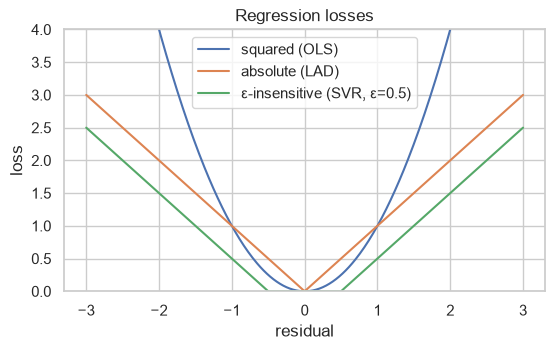

In [43]:
# the three losses side by side (theory made visible)
r_ = np.linspace(-3, 3, 400); eps = 0.5
plt.figure(figsize=(6.2, 3.4))
plt.plot(r_, r_ ** 2, label='squared (OLS)'); plt.plot(r_, np.abs(r_), label='absolute (LAD)')
plt.plot(r_, np.maximum(0, np.abs(r_) - eps), label=f'ε-insensitive (SVR, ε={eps})'); plt.ylim(0, 4)
plt.xlabel('residual'); plt.ylabel('loss'); plt.legend(); plt.title('Regression losses'); plt.show()

In [44]:
rs_sv = np.random.RandomState(SEED + 8)
d_svr = df_train.iloc[np.sort(rs_sv.choice(len(df_train), min(N_SVR, len(df_train)), replace=False))].reset_index(drop=True)

def svr_est(kind, C, gamma=None):
    reg = LinearSVR(C=C, epsilon=0.05, dual="auto", max_iter=5000, random_state=SEED) if kind == "linear" else \
          SVR(kernel="rbf", C=C, gamma=gamma, epsilon=0.05)
    return Pipeline([('z', StandardScaler()), ('m', TransformedTargetRegressor(regressor=reg, transformer=StandardScaler()))])

est_svr = {"OLS (same rows)": Pipeline([('m', LinearRegression())]),
           **{f"SVR linear C={C:g}": svr_est("linear", C) for C in (0.1, 1)},
           **{f"SVR rbf C={C:g} γ={g}": svr_est("rbf", C, g) for C in ((1, 10) if FAST else (0.3, 1, 3, 10)) for g in (("scale",) if FAST else ("scale", 0.01))}}
cv_svr = {}
for n, e in est_svr.items():
    t0 = time.time(); cv_svr[n] = cv_eval_est(e, d_svr, "svr_" + n); print(f"{n:26s} {time.time()-t0:5.1f}s  RMSE={cv_svr[n]['RMSE'].mean():.4f}")
cmp_svr = summarise_cv(cv_svr, base="OLS (same rows)")
best_svr = min([n for n in cmp_svr.index if n.startswith("SVR rbf")], key=lambda n: cmp_svr.loc[n, 'RMSE'])
with pd.option_context('display.float_format', '{:.4f}'.format):
    print(cmp_svr[['RMSE', 'MAE', 'R2', 'dRMSE_vs_base', 'SE_diff', 'improves_1SE']]); print("\nbest RBF-SVR by CV:", best_svr)

OLS (same rows)              0.0s  RMSE=6.1426
SVR linear C=0.1             0.2s  RMSE=6.2413
SVR linear C=1               1.2s  RMSE=6.2421
SVR rbf C=0.3 γ=scale        9.6s  RMSE=6.1519
SVR rbf C=0.3 γ=0.01         9.6s  RMSE=6.1468
SVR rbf C=1 γ=scale          9.3s  RMSE=6.2151
SVR rbf C=1 γ=0.01           8.6s  RMSE=6.1255
SVR rbf C=3 γ=scale         11.6s  RMSE=6.3900
SVR rbf C=3 γ=0.01           9.9s  RMSE=6.1589
SVR rbf C=10 γ=scale        17.8s  RMSE=6.7059
SVR rbf C=10 γ=0.01         11.4s  RMSE=6.2350
                        RMSE    MAE      R2  dRMSE_vs_base  SE_diff  \
model                                                                 
OLS (same rows)       6.1426 4.4078  0.1281         0.0000   0.0000   
SVR linear C=0.1      6.2413 4.3373  0.1006        -0.0988   0.0326   
SVR linear C=1        6.2421 4.3375  0.1004        -0.0996   0.0325   
SVR rbf C=0.3 γ=scale 6.1519 4.2492  0.1265        -0.0093   0.0431   
SVR rbf C=0.3 γ=0.01  6.1468 4.2486  0.1278        -0.004

## 2.12 Everything compared by cross-validation
One table with all regression models, each against **its own** reference (OLS on the same rows, so subsample and full-train numbers are not mixed up). `dRMSE_vs_base` > 0 means better than OLS and `improves_1SE` applies the same 1-SE rule used since §2.6.

In [45]:
def tag(df_, ref, group): return df_.assign(group=group, reference=ref)
all_cmp = pd.concat([
    tag(cmp_nl.drop(index='Linear (base)'), 'OLS · all of train', 'full train'),
    tag(cmp_shr.drop(index='Linear (base)'), 'OLS · all of train', 'full train'),
    tag(cmp_sub.drop(index='OLS (same rows)'), f'OLS · {len(d_sub)} rows', 'subsample'),
    tag(cmp_svr.drop(index='OLS (same rows)'), f'OLS · {len(d_svr)} rows', 'SVR subsample')])
base_rows = pd.DataFrame({'RMSE': [cv_res['Linear (base)']['RMSE'].mean(), cv_sub['OLS (same rows)']['RMSE'].mean(), cv_svr['OLS (same rows)']['RMSE'].mean()],
                          'R2': [cv_res['Linear (base)']['R2'].mean(), cv_sub['OLS (same rows)']['R2'].mean(), cv_svr['OLS (same rows)']['R2'].mean()],
                          'group': ['full train', 'subsample', 'SVR subsample'], 'reference': ['—'] * 3},
                         index=['OLS · all of train', f'OLS · {len(d_sub)} rows', f'OLS · {len(d_svr)} rows'])
all_cmp = pd.concat([base_rows, all_cmp])
with pd.option_context('display.float_format', '{:.4f}'.format, 'display.width', 200, 'display.max_rows', 100):
    print(all_cmp[['group', 'RMSE', 'R2', 'dRMSE_vs_base', 'SE_diff', 'improves_1SE']].sort_values(['group', 'RMSE']))
all_cmp.to_csv(RESULTS_DIR / "regression_cv_comparison.csv")

                                               group   RMSE      R2  dRMSE_vs_base  SE_diff improves_1SE
SVR rbf C=1 γ=0.01                     SVR subsample 6.1255  0.1339         0.0171   0.0359        False
OLS · 5000 rows                        SVR subsample 6.1426  0.1281            NaN      NaN          NaN
SVR rbf C=0.3 γ=0.01                   SVR subsample 6.1468  0.1278        -0.0042   0.0365        False
SVR rbf C=0.3 γ=scale                  SVR subsample 6.1519  0.1265        -0.0093   0.0431        False
SVR rbf C=3 γ=0.01                     SVR subsample 6.1589  0.1244        -0.0163   0.0387        False
SVR rbf C=1 γ=scale                    SVR subsample 6.2151  0.1085        -0.0725   0.0493        False
SVR rbf C=10 γ=0.01                    SVR subsample 6.2350  0.1027        -0.0924   0.0474        False
SVR linear C=0.1                       SVR subsample 6.2413  0.1006        -0.0988   0.0326        False
SVR linear C=1                         SVR subsample 6.

**What to take to the report (Part 2, extended).**
- *Regularisation/projection (ridge, PCR, PLS):* no gain over OLS ⇒ H9; PLS needs fewer components than PCR (supervised vs unsupervised compression). AIC, BIC and Cp pick different sizes: BIC is the most conservative; CV (1-SE) sits in between.
- *Non-linearity:* the additive-spline model recovers the Age curve with no interactions; the model tree and the forest add interactions; boosting is the practical ceiling. SVR on a small subsample shows the kernel idea but cannot compete in cost.
- *Bias–variance, concretely:* single tree (high variance) → forest (variance reduced by averaging, with OOB as free validation) → boosting (bias reduced sequentially).

## 2.13 Final evaluation on test (once) and verdict on H7
Each model is **refitted on all of *train*** and evaluated on *test* with weights. The intervals come from a **bootstrap** of the test profiles resampled with probability ∝ `w` (they measure the uncertainty of the metric; the model is not refitted).

In [46]:
test_models = {'Null (weighted mean)': dict(model='null'), 'Linear (base)': dict(),
               'Final (base + improvements)': spec_final, 'HGB (non-linear ceiling)': dict(model='hgb')}
y_te = df_test[YN].to_numpy(float)
pred_te_reg = {n: fit_predict(sp, df_train, df_test) for n, sp in test_models.items()}
tab_test_reg = pd.DataFrame({n: metrics_reg(y_te, p, w_te) for n, p in pred_te_reg.items()}).T

n_boot_reg, n_b = (50 if FAST else 200), int(w_te.sum())
ci_reg = {}
for n, p in pred_te_reg.items():
    vals = []
    for _ in range(n_boot_reg):
        ix = rng_reg.choice(len(y_te), n_b, p=w_te / w_te.sum())
        vals.append(metrics_reg(y_te[ix], p[ix], np.ones(n_b)))
    v = pd.DataFrame(vals)
    ci_reg[n] = {f'{m}_CI95': f"[{v[m].quantile(.025):.3f}, {v[m].quantile(.975):.3f}]" for m in ['RMSE', 'R2']}
tab_test_reg = tab_test_reg.join(pd.DataFrame(ci_reg).T)
with pd.option_context('display.float_format', '{:.4f}'.format, 'display.width', 160):
    print(tab_test_reg)

                              RMSE    MAE      R2       RMSE_CI95           R2_CI95
Null (weighted mean)        6.6558 4.7489 -0.0000  [6.542, 6.777]  [-0.000, -0.000]
Linear (base)               6.1739 4.3216  0.1395  [6.048, 6.290]    [0.132, 0.147]
Final (base + improvements) 6.1104 4.2685  0.1571  [5.999, 6.221]    [0.149, 0.164]
HGB (non-linear ceiling)    6.0240 4.1821  0.1808  [5.929, 6.135]    [0.172, 0.190]


In [47]:
# ---------- Verdict on H7 ----------
r2_fin, r2_hgb = tab_test_reg.loc['Final (base + improvements)', 'R2'], tab_test_reg.loc['HGB (non-linear ceiling)', 'R2']
d_spl = summary_reg.loc['+ splines on Age', 'dRMSE_vs_base']; e_spl = summary_reg.loc['+ splines on Age', 'SE_diff']

VERDICT['H7a'] = (rho_max <= .23, f"max |ρ| with BMI = {rho_max:.3f} (criterion ≤ 0.23)")
VERDICT['H7b'] = (r2_fin < .30,   f"test R² = {r2_fin:.3f} (HGB ceiling = {r2_hgb:.3f}; criterion < 0.30)")
VERDICT['H7c'] = (d_spl > e_spl,  f"splines on Age: ΔRMSE(CV) = {d_spl:+.4f} (SE {e_spl:.4f})")
for k_, (ok, msg) in VERDICT.items():
    if k_.startswith('H7'): print(f"{k_} ·", "HOLDS    " if ok else "DOES NOT HOLD", "·", msg)

H7a · DOES NOT HOLD · max |ρ| with BMI = 0.257 (criterion ≤ 0.23)
H7b · HOLDS     · test R² = 0.157 (HGB ceiling = 0.181; criterion < 0.30)
H7c · HOLDS     · splines on Age: ΔRMSE(CV) = +0.0482 (SE 0.0009)


### All regression models on test (once)
Every model is **refitted on all of train** (the SVR on its own subsample: it cannot be trained on 180,000 rows) and evaluated once on test, with a bootstrap CI. Hyper-parameters were chosen by CV above, never with test. The fitted models are saved to `models/` so that nothing needs to be retrained to reuse them.

In [48]:
def pick_best(cmp_, prefix):  return min([n for n in cmp_.index if n.startswith(prefix)], key=lambda n: cmp_.loc[n, 'RMSE'])

def refit_shrink(meth):                                    # refit ridge/PCR/PLS with the 1-SE choice, on all train
    mu, sd = w_standardise(Xarr, w_tr); Z = (Xarr - mu) / sd; i = chosen_shr[meth]['one_se']
    if meth == 'ridge':
        r = Ridge(alpha=RIDGE_ALPHAS[i]).fit(Z, y_tr, sample_weight=w_tr); a0, b = r.intercept_, r.coef_
    else:
        a0, B = (pcr_path if meth == 'pcr' else pls_path)(Z, y_tr, w_tr, NCOMP); b = B[i]
    return dict(mu=mu, sd=sd, a0=a0, b=b)
def predict_shrink(f, X): return f['a0'] + ((np.asarray(X, float) - f['mu']) / f['sd']) @ f['b']

reg_zoo = {}                                               # name -> (fitted object, predict function)
for meth in ('ridge', 'pcr', 'pls'):
    f = refit_shrink(meth); reg_zoo[f"{meth.upper()} (1-SE)"] = (f, lambda X, f=f: predict_shrink(f, X))
for n in [pick_best(cmp_nl, "Polynomial"), pick_best(cmp_nl, "Additive"), pick_best(cmp_nl, "Model tree")]:
    m = fit_reg(est_full[n], X_tr, y_tr, w_tr); reg_zoo[n] = (m, m.predict)
rf_full = fit_reg(Pipeline([('m', RandomForestRegressor(n_estimators=100 if FAST else 300, min_samples_leaf=max(5, msl_sub // 4), max_features=0.5, n_jobs=-1, random_state=SEED))]), X_tr, y_tr, w_tr)
reg_zoo["Random forest"] = (rf_full, rf_full.predict)
hgb_full = fit_reg(est_hgb_tuned, X_tr, y_tr, w_tr); reg_zoo["HGB tuned"] = (hgb_full, hgb_full.predict)
svr_full = fit_reg(est_svr[best_svr], design(d_svr), d_svr[YN].to_numpy(float), d_svr['w'].to_numpy(float))
reg_zoo[f"{best_svr} (subsample)"] = (svr_full, svr_full.predict)

X_te_ = design(df_test); rows_ = {}; pred_ext = {}
for n, (m, pf) in reg_zoo.items():
    p = pf(X_te_); pred_ext[n] = p; rows_[n] = metrics_reg(y_te, p, w_te)
    joblib.dump(m, MODELS_DIR / f"reg_{re.sub(r'[^A-Za-z0-9]+', '_', n)}.joblib", compress=3)
tab_ext = pd.DataFrame(rows_).T
tab_all = pd.concat([tab_test_reg[['RMSE', 'MAE', 'R2']], tab_ext]).sort_values('RMSE')
with pd.option_context('display.float_format', '{:.4f}'.format, 'display.width', 160):
    print(tab_all)
tab_all.to_csv(RESULTS_DIR / "regression_test_all_models.csv")

                                      RMSE    MAE      R2
HGB tuned                           6.0220 4.1805  0.1814
HGB (non-linear ceiling)            6.0240 4.1821  0.1808
Random forest                       6.0514 4.2125  0.1734
Model tree (16 leaves)              6.0674 4.2196  0.1690
Polynomial deg 4                    6.0776 4.2324  0.1662
Additive splines (knots=4, alpha=1) 6.1048 4.2642  0.1587
Final (base + improvements)         6.1104 4.2685  0.1571
Linear (base)                       6.1739 4.3216  0.1395
RIDGE (1-SE)                        6.1841 4.3244  0.1367
PLS (1-SE)                          6.1862 4.3297  0.1361
PCR (1-SE)                          6.1916 4.3392  0.1346
SVR rbf C=1 γ=0.01 (subsample)      6.2043 4.1988  0.1310
Null (weighted mean)                6.6558 4.7489 -0.0000


# Part 3 · Classification: calibrated probabilities for the 3 classes (objective O1)

This is the **main** objective. Everything in Parts 1–2 was preparation for it:

| What was learnt before | How it is used here |
|---|---|
| Target is 84 / 2 / 14 % (§1.3) | No accuracy. Main metric = **log-loss** (honest probabilities are wanted), plus AUC OvR, macro-F1, balanced accuracy, Brier and ECE |
| Duplicates collapsed into weights (§1.8) | Train with `sample_weight = w`, evaluate with weighted metrics |
| Age non-monotonic, MentHlth/PhysHlth zero-inflated (§1.4, §1.10) | The "spline" preprocessing: splines on Age/BMI + bands 0 / 1–13 / 14+ |
| Interactions exist (§1.11) | Compare linear vs trees/boosting (H2) and run an Age×BMI ablation (§3.7) |
| Prediabetes label is noisy (§1.11) | Report per-class metrics, evaluate joint risk P(1)+P(2), tune the decision rule for macro-F1 *without* touching the probabilities (§3.9) |
| Protocol learnt in Part 2 | Repeated CV only inside train; test touched once at the end |

**Protocol:** repeated stratified CV **only on train**; preprocessing **inside the `Pipeline`** (so the scaler never sees the validation fold); training with `sample_weight = w`; every metric weighted with `w`.

> If a package is missing: `%pip install scikit-learn` (and optionally `xgboost`) and restart the kernel.

## 3.1 Data for the classifiers
The split built in §1.12 and the variable lists decided in §1.3 are reused (no hard-coded copies that could drift apart).

In [49]:
FIG_TAG = "clf"                                       # prefix of the figure files saved by this part
BIN, ORD, NUM = bin_cols, ord_cols, num_cols          # decided in the EDA
assert set(BIN + ORD + NUM) == set(FEATS)

Xtr, ytr, wtr = df_train[FEATS], df_train[target].astype(int).values, df_train['w'].values
Xte, yte, wte = df_test[FEATS],  df_test[target].astype(int).values,  df_test['w'].values
PRIORS_W = np.bincount(ytr, weights=wtr, minlength=3) / wtr.sum()     # population class priors (used by LDA/QDA, which take no weights)
print("train:", Xtr.shape, "| test:", Xte.shape, "| weighted class priors:", PRIORS_W.round(4))

train: (183824, 21) | test: (45957, 21) | weighted class priors: [0.8423 0.0183 0.1395]


## 3.2 Preprocessing and metrics
**Three preprocessing recipes, because different model families need different inputs:**
- `linear`: standardise ordinals and numerics (logistic, LDA, SVM are scale-sensitive).
- `spline`: as `linear` but with **splines on Age and BMI** (non-linear effects, a GAM-like approximation) and **bands 0 / 1–13 / 14+** for MentHlth/PhysHlth (EDA decisions 2 and 4).
- `tree`: no transformation (trees are invariant to monotone transformations).

The optional `extra` argument adds already-built columns (used by the interaction ablation).

**Metrics** are always weighted with `w`:
- *Discrimination:* AUC one-vs-rest (overall, diabetes, prediabetes), `auc_risk` for the joint risk, macro-F1, per-class F1, balanced accuracy.
- *Probability quality:* **log-loss** (main), **Brier** and **ECE** of the joint risk (how far predicted probabilities are from observed frequencies).

In [50]:
def _days_to_band(X):                                    # 0 / 1-13 / 14+ days
    return np.digitize(np.asarray(X), [1, 14])

def make_prep(kind="linear", drop=(), extra=()):
    b = [c for c in BIN if c not in drop]; o = [c for c in ORD if c not in drop]; n = NUM; ex = list(extra)
    if kind == "tree":
        return ColumnTransformer([("p", "passthrough", b + o + n + ex)])
    if kind == "linear":
        return ColumnTransformer([("p", "passthrough", b), ("s", StandardScaler(), o + n + ex)])
    if kind == "spline":
        sp = [c for c in ("Age", "BMI") if c not in drop]
        rest = [c for c in o + n + ex if c not in sp + ["MentHlth", "PhysHlth"]]
        bands = Pipeline([("t", FunctionTransformer(_days_to_band)),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))])
        return ColumnTransformer([("p", "passthrough", b),
                                  ("sp", Pipeline([("s", SplineTransformer(n_knots=5, degree=3)),
                                                   ("z", StandardScaler())]), sp),
                                  ("z", StandardScaler(), rest),
                                  ("tr", bands, ["MentHlth", "PhysHlth"])])
    raise ValueError(kind)

def brier_multi(y, P, w=None):
    Y = np.eye(P.shape[1])[y]
    return np.average(((P - Y) ** 2).sum(1), weights=w)

def ece(y_bin, p, w=None, bins=10):
    edges = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(p, edges) - 1, 0, bins - 1)
    w = np.ones_like(p) if w is None else w; tot = w.sum(); e = 0.0
    for k in range(bins):
        m = idx == k
        if m.any():
            e += w[m].sum() / tot * abs(np.average(y_bin[m], weights=w[m]) - np.average(p[m], weights=w[m]))
    return e

def metrics_clf(y, P, w=None, pred=None):
    pred = P.argmax(1) if pred is None else pred
    f1c = f1_score(y, pred, average=None, labels=[0, 1, 2], sample_weight=w, zero_division=0)
    auc_c = [roc_auc_score(y == k, P[:, k], sample_weight=w) for k in range(3)]
    return {"auc_ovr": roc_auc_score(y, P, multi_class="ovr", sample_weight=w),
            "auc_diab": auc_c[2], "auc_prediab": auc_c[1],                        # H1, H3
            "auc_risk": roc_auc_score(y >= 1, P[:, 1] + P[:, 2], sample_weight=w),
            "macro_f1": f1_score(y, pred, average="macro", sample_weight=w, zero_division=0),
            "f1_0": f1c[0], "f1_1": f1c[1], "f1_2": f1c[2],                       # H3
            "bal_acc": balanced_accuracy_score(y, pred, sample_weight=w),
            "logloss": log_loss(y, P, labels=[0, 1, 2], sample_weight=w),
            "brier": brier_multi(y, P, w),
            "ece_risk": ece((y >= 1).astype(float), P[:, 1] + P[:, 2], w)}

## 3.3 Fitting with weights and repeated cross-validation
`fit_w` passes `sample_weight = w` to the **last step** of the `Pipeline` (if the estimator accepts it; LDA/QDA/KNN do not, so they are fitted unweighted — for LDA/QDA the class *priors* are at least fixed to the weighted population ones).

**Why repeated stratified CV (5 folds × 2 repeats)?** One 5-fold split gives a noisy estimate; repeating it with different shuffles averages out the luck of the split and gives 10 values per metric, which are needed later for paired comparisons (§3.8). *Stratified* keeps the rare prediabetes class in every fold.

**Why there are no "twin" rows between folds:** duplicates were collapsed into single weighted rows, so an identical person cannot sit in a training fold and a validation fold at the same time (the CV "twin cases" trap).

**Baseline first.** A `DummyClassifier` that always predicts the class priors gives the reference log-loss/Brier: any real model must beat it, and by how much shows how much signal exists.

In [51]:
def fit_w(model, X, y, w=None):
    m = clone(model)
    if w is None or "sample_weight" not in inspect.signature(m.steps[-1][1].fit).parameters:
        return m.fit(X, y)                      # e.g. LDA does not accept weights -> fitted without them
    return m.fit(X, y, **{f"{m.steps[-1][0]}__sample_weight": w})

CV = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)

def cv_eval_clf(model, X=None, use_w=True, name=""):
    X = Xtr if X is None else X
    def run():
        rows = []
        for tr, va in CV.split(X, ytr):
            m = fit_w(model, X.iloc[tr], ytr[tr], wtr[tr] if use_w else None)
            rows.append(metrics_clf(ytr[va], m.predict_proba(X.iloc[va]), wtr[va]))   # evaluation is ALWAYS weighted
        out = pd.DataFrame(rows); out.insert(0, "model", name); return out
    # on-disk cache: re-running the notebook does not repeat a CV that was already computed for this exact model/data
    return cached(f"clf_cv_{name}", run, sig=f"{model!r}|{use_w}|{X.shape}|{list(X.columns)}")

results = {}
results["dummy_prior"] = cv_eval_clf(Pipeline([("c", DummyClassifier(strategy="prior"))]), name="dummy_prior")
print(results["dummy_prior"].mean(numeric_only=True).round(4))   # reference log-loss and Brier

auc_ovr        0.5000
auc_diab       0.5000
auc_prediab    0.5000
auc_risk       0.5000
macro_f1       0.3048
f1_0           0.9144
f1_1           0.0000
f1_2           0.0000
bal_acc        0.3333
logloss        0.4925
brier          0.2708
ece_risk       0.0004
dtype: float64


## 3.4 Model families (reasonable default hyper-parameters)
The models are ordered from simple/interpretable to flexible, mirroring the course chapters:

- **Multinomial logistic regression (GLM)** — the interpretable reference, with and without non-linearity (splines).
- **Lasso (L1) logistic** — embedded variable selection.
- **LDA** — a classical generative linear classifier.
- **Pruned tree** — interpretable but high-variance.
- **Random Forest** (bagging + random feature subsets) and **gradient boosting** (HistGB; XGBoost if installed) — flexible models that capture interactions automatically.

*Why default hyper-parameters first, tuning later (§3.5)?* A quick pass over all families shows which ones deserve the expensive tuning, instead of tuning everything blindly.

In [52]:
def lr(C=1.0, l1=False):
    # Multinomial logistic regression; L2 by default, L1 (lasso) if l1=True. Works with sklearn <1.8 and >=1.8.
    # The L1 fit uses the SAGA solver, which is very slow to "fully" converge on ~180k rows: it is capped
    # (max_iter=200, tol=1e-3). That is enough for a selection/regularisation comparison; do not use it for tuning.
    if tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8):
        if l1:
            return LogisticRegression(C=C, l1_ratio=1.0, solver="saga", max_iter=200, tol=1e-3)
        return LogisticRegression(C=C, l1_ratio=0.0, solver="lbfgs", max_iter=2000)
    if l1:
        return LogisticRegression(C=C, penalty="l1", solver="saga", max_iter=200, tol=1e-3)
    return LogisticRegression(C=C, penalty="l2", solver="lbfgs", max_iter=2000)

MODELS = {
    "logit_L2":        Pipeline([("prep", make_prep("linear")), ("clf", lr(1.0))]),
    "logit_L2_spline": Pipeline([("prep", make_prep("spline")), ("clf", lr(1.0))]),
    "logit_lasso":     Pipeline([("prep", make_prep("spline")), ("clf", lr(0.05, l1=True))]),
    "lda":             Pipeline([("prep", make_prep("linear")), ("clf", LinearDiscriminantAnalysis(priors=PRIORS_W))]),
    "tree_pruned":     Pipeline([("prep", make_prep("tree")),
                                 ("clf", DecisionTreeClassifier(ccp_alpha=1e-4, min_samples_leaf=50, random_state=SEED))]),
    "rf":              Pipeline([("prep", make_prep("tree")),
                                 ("clf", RandomForestClassifier(n_estimators=100 if FAST else 200, min_samples_leaf=20,
                                                                max_features="sqrt", n_jobs=-1, random_state=SEED))]),
    "hgb":             Pipeline([("prep", make_prep("tree")),
                                 ("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=50 if FAST else 200,
                                                                        max_leaf_nodes=15, l2_regularization=1.0,
                                                                        random_state=SEED))]),
}
try:                                    # XGBoost (optional): %pip install xgboost
    from xgboost import XGBClassifier
    MODELS["xgb"] = Pipeline([("prep", make_prep("tree")),
                              ("clf", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                                                    colsample_bytree=0.8, tree_method="hist", n_jobs=-1,
                                                    random_state=SEED, eval_metric="mlogloss"))])
except ImportError:
    print("xgboost not installed: skipped")

for k, m in MODELS.items():
    t0 = time.time(); results[k] = cv_eval_clf(m, name=k)
    print(f"{k:16s} {time.time()-t0:5.0f}s", results[k][["auc_ovr", "macro_f1", "logloss"]].mean().round(4).to_dict())

logit_L2            31s {'auc_ovr': 0.7794, 'macro_f1': 0.3909, 'logloss': 0.4023}
logit_L2_spline     33s {'auc_ovr': 0.7835, 'macro_f1': 0.3999, 'logloss': 0.3973}
logit_lasso        763s {'auc_ovr': 0.7835, 'macro_f1': 0.399, 'logloss': 0.3973}
lda                  6s {'auc_ovr': 0.7782, 'macro_f1': 0.3907, 'logloss': 0.4054}
tree_pruned         12s {'auc_ovr': 0.7615, 'macro_f1': 0.3687, 'logloss': 0.4097}
rf                  65s {'auc_ovr': 0.7797, 'macro_f1': 0.375, 'logloss': 0.3971}
hgb                 64s {'auc_ovr': 0.7861, 'macro_f1': 0.3963, 'logloss': 0.3941}
xgb                 75s {'auc_ovr': 0.7874, 'macro_f1': 0.3965, 'logloss': 0.3934}


## 3.5 SVM, KNN, QDA and Naive Bayes — the remaining classical classifiers
**Why a subsample?** The cost of a kernel SVM grows at least with n² (and memory with n²): on ~184,000 rows it is impractical. So the RBF-SVM is evaluated on a **stratified subsample**, and compared with the logistic regression **on the very same subsample** (otherwise the comparison would be unfair). SVMs do not output probabilities, so they are calibrated (Platt / sigmoid) *inside* the pipeline.

This is also why the SVM does not appear in the calibration part of H6: it leaves this block already calibrated.

In [53]:
rs = np.random.RandomState(SEED)
frac = np.bincount(ytr) / len(ytr)
idx_sub = np.sort(np.concatenate([rs.choice(np.where(ytr == k)[0], min((ytr == k).sum(), int(N_SVM * frac[k])), replace=False)
                                  for k in range(3)]))
Xsv, ysv, wsv = Xtr.iloc[idx_sub], ytr[idx_sub], wtr[idx_sub]

def cv_eval_sub(model, name, X=None, y=None, w=None):
    # CV on a (sub)sample; by default the SVM subsample defined above. X, y, w can be given to use another one.
    X = Xsv if X is None else X; y = ysv if y is None else y; w = wsv if w is None else w
    def run():
        rows = []
        for tr, va in StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED).split(X, y):
            m = fit_w(model, X.iloc[tr], y[tr], w[tr]); rows.append(metrics_clf(y[va], m.predict_proba(X.iloc[va]), w[va]))
        out = pd.DataFrame(rows); out.insert(0, "model", name); return out
    return cached(f"clf_sub_{name}", run, sig=f"{model!r}|{X.shape}|{int(w.sum())}")

svm_lin = Pipeline([("prep", make_prep("linear")),
                    ("clf", CalibratedClassifierCV(LinearSVC(C=0.1, dual="auto"), method="sigmoid", cv=3))])
svm_rbf = Pipeline([("prep", make_prep("linear")),
                    ("clf", CalibratedClassifierCV(SVC(kernel="rbf", C=1.0, gamma="scale"), method="sigmoid", cv=3))])
results["logit (subsample)"]      = cv_eval_sub(MODELS["logit_L2"], "logit (subsample)")
results["svm_linear (subsample)"] = cv_eval_sub(svm_lin, "svm_linear (subsample)")
results["svm_rbf (subsample)"]    = cv_eval_sub(svm_rbf, "svm_rbf (subsample)")

table = pd.concat(results.values()).groupby("model", sort=False)[["auc_ovr", "auc_diab", "macro_f1", "f1_1", "logloss", "brier"]].agg(["mean", "std"])
table.round(4)

auc_ovr         auc_diab         macro_f1         f1_1  \
                          mean     std     mean     std     mean     std mean   
model                                                                           
dummy_prior             0.5000  0.0000   0.5000  0.0000   0.3048  0.0001  0.0   
logit_L2                0.7794  0.0036   0.8203  0.0028   0.3909  0.0020  0.0   
logit_L2_spline         0.7835  0.0039   0.8252  0.0028   0.3999  0.0022  0.0   
logit_lasso             0.7835  0.0039   0.8252  0.0028   0.3990  0.0021  0.0   
lda                     0.7782  0.0039   0.8184  0.0027   0.3907  0.0015  0.0   
tree_pruned             0.7615  0.0047   0.8047  0.0033   0.3687  0.0132  0.0   
rf                      0.7797  0.0041   0.8254  0.0026   0.3750  0.0025  0.0   
hgb                     0.7861  0.0037   0.8285  0.0026   0.3963  0.0031  0.0   
xgb                     0.7874  0.0036   0.8292  0.0027   0.3965  0.0021  0.0   
logit (subsample)       0.7739  0.0121   0.8152  0.0118   0.3863  0.0119  0.0   
svm_linear (subsample)  0.7703  0.0135   0.8148  0.0128   0.3809  0.0124  0.0   
svm_rbf (subsample)     0.6426  0.0080   0.7303  0.0102   0.3366  0.0031  0.0   

                            logloss           brier          
                        std    mean     std    mean     std  
model                                                        
dummy_prior             0.0  0.4925  0.0008  0.2708  0.0006  
logit_L2                0.0  0.4023  0.0021  0.2262  0.0013  
logit_L2_spline         0.0  0.3973  0.0021  0.2228  0.0012  
logit_lasso             0.0  0.3973  0.0020  0.2228  0.0012  
lda                     0.0  0.4054  0.0022  0.2278  0.0014  
tree_pruned             0.0  0.4097  0.0023  0.2277  0.0012  
rf                      0.0  0.3971  0.0019  0.2223  0.0011  
hgb                     0.0  0.3941  0.0021  0.2211  0.0012  
xgb                     0.0  0.3934  0.0021  0.2208  0.0012  
logit (subsample)       0.0  0.4057  0.0145  0.2274  0.0081  
svm_linear (subsample)  0.0  0.4082  0.0145  0.2282  0.0083  
svm_rbf (subsample)     0.0  0.4695  0.0110  0.2561  0.0075

### 3.5.1 What does the SVM actually optimise? (hinge vs logistic loss)
Logistic regression and the SVM are the same linear model fitted with **different losses** on the margin *m = y·f(x)* (positive = correct side). The logistic loss is smooth and keeps shrinking as *m* grows, so *every* point matters a little and the output is a probability. The **hinge** loss is exactly zero once *m* ≥ 1: points beyond the margin do not influence the fit at all (only the *support vectors* do), which is what makes the SVM sparse in the data — and also why its raw scores are **not** probabilities (hence the Platt calibration above).

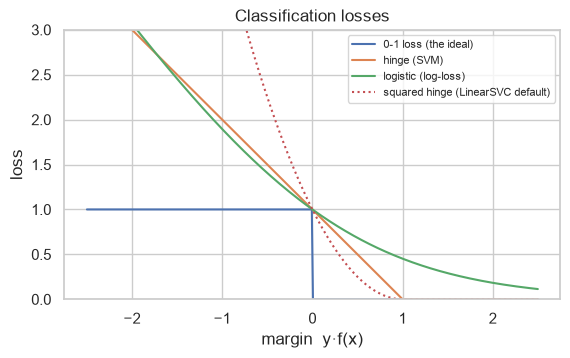

In [54]:
m_ = np.linspace(-2.5, 2.5, 400)
plt.figure(figsize=(6.4, 3.5))
plt.plot(m_, (m_ < 0).astype(float), label='0-1 loss (the ideal)')
plt.plot(m_, np.maximum(0, 1 - m_), label='hinge (SVM)')
plt.plot(m_, np.log2(1 + np.exp(-m_)), label='logistic (log-loss)')
plt.plot(m_, np.maximum(0, 1 - m_) ** 2, ls=':', label='squared hinge (LinearSVC default)')
plt.ylim(0, 3); plt.xlabel('margin  y·f(x)'); plt.ylabel('loss'); plt.legend(fontsize=8); plt.title('Classification losses'); plt.show()

### 3.5.2 Tuning the RBF-SVM (C and γ)
**C** is the error budget (large C = narrow margin, fits the training data harder → more variance) and **γ** the kernel width (large γ = very local decision boundary → overfitting). They interact, so they are searched **jointly** on a **small stratified subsample** (kernel SVMs are O(n²)), scoring by **log-loss of the calibrated probabilities**. The best pair is then re-evaluated with the repeated CV on the larger SVM subsample of §3.5, next to logistic regression on the same rows.

In [55]:
def strat_idx(n, seed):
    # stratified random subsample of train (same recipe as the SVM subsample)
    rs_ = np.random.RandomState(seed)
    return np.sort(np.concatenate([rs_.choice(np.where(ytr == k)[0], min((ytr == k).sum(), int(n * frac[k])), replace=False) for k in range(3)]))

def svm_pipe(C, g):
    return Pipeline([("prep", make_prep("linear")),
                     ("clf", CalibratedClassifierCV(SVC(kernel="rbf", C=C, gamma=g), method="sigmoid", cv=3))])

idx_st = strat_idx(1500 if FAST else 4000, SEED + 3)
X_st, y_st, w_st = Xtr.iloc[idx_st], ytr[idx_st], wtr[idx_st]
svm_grid = [(C, g) for C in ((1, 3) if FAST else (0.3, 1, 3)) for g in ((0.01,) if FAST else (0.003, 0.01, 0.03))]
svm_rows = []
for C, g in svm_grid:
    t0 = time.time(); r = cv_eval_sub(svm_pipe(C, g), f"svm C={C} gamma={g}", X=X_st, y=y_st, w=w_st)
    svm_rows.append(dict(C=C, gamma=g, logloss=r["logloss"].mean(), auc_ovr=r["auc_ovr"].mean(), seconds=time.time() - t0))
svm_tune = pd.DataFrame(svm_rows).sort_values("logloss")
print(svm_tune.round(4).to_string(index=False))
C_best, g_best = svm_tune.iloc[0][["C", "gamma"]]
SVM_BEST = (float(C_best), float(g_best))
results["svm_rbf_tuned (subsample)"] = cv_eval_sub(svm_pipe(*SVM_BEST), "svm_rbf_tuned (subsample)")
print("\nbest (C, gamma) =", SVM_BEST)
print(pd.concat([results[k] for k in ["logit (subsample)", "svm_linear (subsample)", "svm_rbf (subsample)", "svm_rbf_tuned (subsample)"]])
      .groupby("model", sort=False)[["auc_ovr", "auc_diab", "logloss", "brier"]].mean().round(4))

  C  gamma  logloss  auc_ovr  seconds
3.0  0.010   0.4468   0.6978   5.5103
1.0  0.003   0.4476   0.6901   6.3307
0.3  0.003   0.4479   0.6695   5.6393
3.0  0.003   0.4480   0.6989   6.3987
1.0  0.010   0.4499   0.7018   5.6658
0.3  0.030   0.4501   0.7021   6.0135
1.0  0.030   0.4506   0.6955   6.3201
0.3  0.010   0.4507   0.6942   5.0930
3.0  0.030   0.4646   0.6902   6.5963

best (C, gamma) = (3.0, 0.01)
                           auc_ovr  auc_diab  logloss   brier
model                                                        
logit (subsample)           0.7739    0.8152   0.4057  0.2274
svm_linear (subsample)      0.7703    0.8148   0.4082  0.2282
svm_rbf (subsample)         0.6426    0.7303   0.4695  0.2561
svm_rbf_tuned (subsample)   0.6637    0.7350   0.4591  0.2509


### 3.5.3 KNN, QDA and Naive Bayes
The remaining classical classifiers of the course, each with a clear reason to be here and a clear way to fail:

| Model | Idea | Expected weakness on these data |
|---|---|---|
| **KNN** | the probability is the class mix among the *k* nearest people | 21 mostly-binary dimensions → distances are nearly all equal ("curse of dimensionality"); the rare class gets almost no neighbours. Raw KNN probabilities are 0 for the rare class and the log-loss explodes, so the standard **m-estimate smoothing** is used (add *m* pseudo-neighbours distributed like the prior) |
| **QDA** | LDA with a **separate covariance per class** → quadratic boundary | ~230 parameters per class on 20+ correlated, partly binary variables; the Gaussian assumption is false for 0/1 data. A small `reg_param` shrinks the covariances towards the identity |
| **Gaussian Naive Bayes** | independent Gaussian features given the class | Gaussian for binary variables is a poor model, and the independence assumption is false (correlated groups were seen in §1.6) |
| **Categorical Naive Bayes** | same independence, but each variable is treated as **categorical** (BMI discretised in 10 quantile bins, days in 3 bands) | the right likelihood for this kind of data; still over-confident because correlated evidence is counted several times |

**How the weights are handled.** KNN, LDA and QDA cannot use `sample_weight`; Naive Bayes can. For LDA/QDA the **class priors are at least fixed to the weighted (population) ones**, otherwise their intercepts would reflect the unique-profile mix instead of the population. KNN is evaluated on a subsample drawn **with probability ∝ `w`** (so it already represents the population) and with weights 1; logistic regression on the *same rows* is the reference.

In [56]:
class KNNSmooth(BaseEstimator, ClassifierMixin):
    # KNN whose probabilities are shrunk towards the class prior with `m` pseudo-neighbours (m-estimate).
    def __init__(self, n_neighbors=50, m=10.0):
        self.n_neighbors, self.m = n_neighbors, m
    def fit(self, X, y):
        self.knn_ = KNeighborsClassifier(n_neighbors=self.n_neighbors, n_jobs=-1).fit(X, y)
        self.classes_ = self.knn_.classes_; self.prior_ = np.bincount(np.searchsorted(self.classes_, y)) / len(y); return self
    def predict_proba(self, X):
        return (self.n_neighbors * self.knn_.predict_proba(X) + self.m * self.prior_) / (self.n_neighbors + self.m)
    def predict(self, X): return self.classes_[self.predict_proba(X).argmax(1)]

rs_k = np.random.RandomState(SEED + 4)
idx_knn = np.sort(rs_k.choice(len(ytr), min(N_KNN, len(ytr)), replace=False, p=wtr / wtr.sum()))     # population-representative subsample
Xk, yk, wk = Xtr.iloc[idx_knn], ytr[idx_knn], np.ones(len(idx_knn))
print(f"KNN subsample: {len(idx_knn)} rows | class mix {np.round(np.bincount(yk) / len(yk) * 100, 1)} % (population: {np.round(frac * 100, 1)} % of unique profiles)")

knn_rows = {"logit_L2 (KNN rows)": cv_eval_sub(MODELS["logit_L2"], "logit_L2 (KNN rows)", X=Xk, y=yk, w=wk)}
for k_ in ((25, 100) if FAST else (25, 50, 100, 200, 400)):
    nm = f"knn_k{k_} (KNN rows)"
    knn_rows[nm] = cv_eval_sub(Pipeline([("prep", make_prep("linear")), ("clf", KNNSmooth(k_))]), nm, X=Xk, y=yk, w=wk)
results.update(knn_rows)
print(pd.concat(knn_rows.values()).groupby("model", sort=False)[["auc_ovr", "auc_diab", "logloss", "brier"]].mean().round(4))

KNN subsample: 20000 rows | class mix [84.2  1.8 14.1] % (population: [82.7  2.  15.3] % of unique profiles)
                     auc_ovr  auc_diab  logloss   brier
model                                                  
logit_L2 (KNN rows)   0.7752    0.8213   0.4017  0.2261
knn_k25 (KNN rows)    0.7152    0.7970   0.4279  0.2337
knn_k50 (KNN rows)    0.7392    0.8096   0.4174  0.2300
knn_k100 (KNN rows)   0.7495    0.8153   0.4114  0.2287
knn_k200 (KNN rows)   0.7612    0.8173   0.4076  0.2286
knn_k400 (KNN rows)   0.7641    0.8157   0.4085  0.2299


In [57]:
# ---------- QDA, Gaussian NB and Categorical NB on ALL of train (they are cheap) ----------
PRIORS = PRIORS_W                                        # weighted class priors (population)
def _to_int(X): return np.asarray(X).astype(int)

def make_cat_prep():
    days = [c for c in NUM if c in ("MentHlth", "PhysHlth")]; cont = [c for c in NUM if c not in days]
    parts = [("b", "passthrough", BIN), ("o", FunctionTransformer(_to_int), ORD), ("d", FunctionTransformer(_days_to_band), days)]
    if cont: parts.append(("k", KBinsDiscretizer(n_bins=10, encode="ordinal", strategy="quantile"), cont))
    return ColumnTransformer(parts), [2] * len(BIN) + [int(Xtr[c].max()) + 1 for c in ORD] + [3] * len(days) + [10] * len(cont)

cat_prep, min_cat = make_cat_prep()
cands = {**{f"qda_reg{r}": Pipeline([("prep", make_prep("linear")), ("clf", QuadraticDiscriminantAnalysis(reg_param=r, priors=PRIORS))]) for r in (0.0, 0.1, 0.5)},
         "nb_gauss": Pipeline([("prep", make_prep("linear")), ("clf", GaussianNB())]),
         "nb_categorical": Pipeline([("prep", cat_prep), ("clf", CategoricalNB(alpha=1.0, min_categories=min_cat))])}
for nm, m in cands.items():
    t0 = time.time()
    try:
        results[nm] = cv_eval_clf(m, name=nm)
        print(f"{nm:16s} {time.time()-t0:5.0f}s", results[nm][["auc_ovr", "macro_f1", "logloss"]].mean().round(4).to_dict())
    except Exception as e:
        print(f"{nm:16s} FAILED ({type(e).__name__}: {str(e)[:80]}) -> skipped")
qda_ok = [n for n in cands if n.startswith("qda") and n in results]
if qda_ok:
    best_qda = min(qda_ok, key=lambda n: results[n]["logloss"].mean()); MODELS["qda"] = cands[best_qda]; results["qda"] = results[best_qda].assign(model="qda")
    print("\nQDA: best reg_param variant =", best_qda)
for nm in ("nb_gauss", "nb_categorical"):
    if nm in results: MODELS[nm] = cands[nm]

qda_reg0.0           5s {'auc_ovr': 0.7398, 'macro_f1': 0.4257, 'logloss': 0.8812}
qda_reg0.1           5s {'auc_ovr': 0.7654, 'macro_f1': 0.4182, 'logloss': 0.4703}
qda_reg0.5           6s {'auc_ovr': 0.7641, 'macro_f1': 0.4045, 'logloss': 0.4515}
nb_gauss             5s {'auc_ovr': 0.7407, 'macro_f1': 0.4303, 'logloss': 1.3199}
nb_categorical       6s {'auc_ovr': 0.7692, 'macro_f1': 0.4388, 'logloss': 0.5812}

QDA: best reg_param variant = qda_reg0.5


In [58]:
rows_ = [k for k in ["dummy_prior", "logit_L2", "lda", "qda", "nb_gauss", "nb_categorical", "tree_pruned", "rf", "hgb"] + ([ "xgb"] if "xgb" in results else []) if k in results]
print("All classical families on ALL of train (repeated CV, weighted):")
print(pd.concat([results[k] for k in rows_]).groupby("model", sort=False)[["auc_ovr", "auc_diab", "macro_f1", "logloss", "brier", "ece_risk"]].mean().round(4))

All classical families on ALL of train (repeated CV, weighted):
                auc_ovr  auc_diab  macro_f1  logloss   brier  ece_risk
model                                                                 
dummy_prior      0.5000    0.5000    0.3048   0.4925  0.2708    0.0004
logit_L2         0.7794    0.8203    0.3909   0.4023  0.2262    0.0142
lda              0.7782    0.8184    0.3907   0.4054  0.2278    0.0210
qda              0.7641    0.8024    0.4045   0.4515  0.2554    0.0569
nb_gauss         0.7407    0.7822    0.4303   1.3199  0.4117    0.1862
nb_categorical   0.7692    0.8102    0.4388   0.5812  0.3046    0.1194
tree_pruned      0.7615    0.8047    0.3687   0.4097  0.2277    0.0036
rf               0.7797    0.8254    0.3750   0.3971  0.2223    0.0093
hgb              0.7861    0.8285    0.3963   0.3941  0.2211    0.0041
xgb              0.7874    0.8292    0.3965   0.3934  0.2208    0.0041


> **What to say about them.** The three "simple probabilistic" models (QDA, Gaussian NB, categorical NB) are usually *good rankers* (decent AUC) but *poor probability estimators* (worse log-loss, Brier and ECE than logistic regression): their assumptions fail in a way that makes them over-confident. KNN pays for the curse of dimensionality. This is exactly why the main metric is log-loss and not accuracy or AUC alone: a model can be competitive on ranking and still unusable as a risk estimate.

## 3.6 Hyper-parameter tuning
**Why random search?** With many hyper-parameters a grid wastes most of its evaluations on unimportant dimensions; random search explores more distinct values per important parameter for the same budget (Bergstra & Bengio). Alternatives seen in class — `HalvingRandomSearchCV` and Bayesian optimisation (optuna/skopt) — are natural extensions.

**What is optimised:** **log-loss**, because the goal is a good probability, not just good ranking.

**Why on a subsample?** To keep the search affordable; the tuned model is then re-evaluated with the full repeated CV on all of train (so the reported numbers are not those of the search).

*Limitation to document:* the search's log-loss is **not weighted** by `w` (only the fit is), whereas all final metrics are weighted.

In [59]:
SPACES = {
    # (the lasso is NOT searched: its saga solver is too slow here; its default C is enough for the comparison)
    "rf":  (MODELS["rf"], {"clf__max_depth": [6, 10, 14, None], "clf__min_samples_leaf": randint(5, 100),
                           "clf__max_features": ["sqrt", 0.3, 0.5]}),
    "hgb": (MODELS["hgb"], {"clf__learning_rate": loguniform(0.01, 0.2), "clf__max_leaf_nodes": randint(4, 40),
                            "clf__min_samples_leaf": randint(20, 300), "clf__l2_regularization": loguniform(1e-2, 1e2),
                            "clf__max_iter": randint(100, 500)}),
}
# stratified subsample for the search
rs_tune = np.random.RandomState(SEED + 1)
idx_tune = np.sort(np.concatenate([rs_tune.choice(np.where(ytr == k)[0], min((ytr == k).sum(), int(N_TUNE * frac[k])), replace=False)
                                   for k in range(3)]))

def tune(name, n_iter=N_ITER, sub=idx_tune):
    est, space = SPACES[name]
    search = RandomizedSearchCV(est, space, n_iter=n_iter, scoring="neg_log_loss",
                                cv=StratifiedKFold(3, shuffle=True, random_state=SEED), random_state=SEED, n_jobs=1, refit=False)
    search.fit(Xtr.iloc[sub], ytr[sub], **{f"{est.steps[-1][0]}__sample_weight": wtr[sub]})
    return search.best_params_, -search.best_score_

BEST = {}
for nm in SPACES:
    t0 = time.time()
    BEST[nm], ll = cached(f"clf_tune_{nm}", lambda nm=nm: tune(nm), sig=f"{SPACES[nm][0]!r}|{N_ITER}|{N_TUNE}")
    print(f"{nm}: {BEST[nm]} | search log-loss = {ll:.4f} | {time.time()-t0:.0f}s")
    MODELS[nm + "_tuned"] = clone(SPACES[nm][0]).set_params(**BEST[nm])
    results[nm + "_tuned"] = cv_eval_clf(MODELS[nm + "_tuned"], name=nm + "_tuned")
    print("   repeated CV:", results[nm + "_tuned"][["auc_ovr", "macro_f1", "logloss"]].mean().round(4).to_dict())

rf: {'clf__max_depth': None, 'clf__max_features': 0.3, 'clf__min_samples_leaf': 26} | search log-loss = 0.4339 | 73s
   repeated CV: {'auc_ovr': 0.7789, 'macro_f1': 0.3822, 'logloss': 0.3973}
hgb: {'clf__l2_regularization': np.float64(0.3666421832063723), 'clf__learning_rate': np.float64(0.017262139284006217), 'clf__max_iter': 487, 'clf__max_leaf_nodes': 5, 'clf__min_samples_leaf': 73} | search log-loss = 0.4295 | 115s
   repeated CV: {'auc_ovr': 0.7863, 'macro_f1': 0.3976, 'logloss': 0.3946}


**Nested CV.** Tuning and evaluating on the same folds gives a slightly optimistic estimate. *Nested* CV tunes **inside** each outer training fold, so the outer fold remains a clean test. It is expensive, so it is run only for HGB on the SVM subsample (next cells); the comparison with the plain CV estimate on the *same* rows shows how optimistic the latter is.

In [60]:
def nested_cv(name, outer=3, n_iter=8, sub=idx_sub):
    rows = []
    for tr, va in StratifiedKFold(outer, shuffle=True, random_state=SEED).split(Xtr.iloc[sub], ytr[sub]):
        itr, iva = sub[tr], sub[va]
        p, _ = tune(name, n_iter=n_iter, sub=itr)
        m = fit_w(clone(SPACES[name][0]).set_params(**p), Xtr.iloc[itr], ytr[itr], wtr[itr])
        rows.append(metrics_clf(ytr[iva], m.predict_proba(Xtr.iloc[iva]), wtr[iva]))
    return pd.DataFrame(rows)

# (executed in the next cell)

### 3.6.1 Running the nested CV and measuring the optimism of plain CV
The plain CV estimate of the tuned HGB was obtained with hyper-parameters that were chosen **looking at the same data**. Nested CV re-does the tuning inside each outer fold. The difference between the two, **on the same rows**, is the optimism of reporting the tuned model's CV score. (Both use the SVM subsample; the number of outer folds and search iterations are small by design.)

In [61]:
nested_hgb = cached("clf_nested_hgb", lambda: nested_cv("hgb", outer=3, n_iter=4 if FAST else 8),
                    sig=f"{SPACES['hgb'][0]!r}|{len(idx_sub)}|{FAST}")
plain_hgb = cv_eval_sub(MODELS["hgb_tuned"], "hgb_tuned (plain CV, same rows)")
cmp_nest = pd.DataFrame({"nested CV (honest)": nested_hgb[["logloss", "auc_ovr", "brier"]].mean(),
                         "plain CV (tuned on the same data)": plain_hgb[["logloss", "auc_ovr", "brier"]].mean()})
cmp_nest["optimism"] = cmp_nest["nested CV (honest)"] - cmp_nest["plain CV (tuned on the same data)"]
print(cmp_nest.round(4))
print("\nA positive log-loss 'optimism' means the plain CV looked better than the nested (honest) one.")

         nested CV (honest)  plain CV (tuned on the same data)  optimism
logloss              0.4072                             0.4030    0.0043
auc_ovr              0.7621                             0.7677   -0.0057
brier                0.2258                             0.2240    0.0018

A positive log-loss 'optimism' means the plain CV looked better than the nested (honest) one.


### 3.6.2 Four search strategies on the same problem
The course compares ways of exploring the hyper-parameter space. They are given the **same model (HGB), the same data subsample and a comparable budget**, and measure: how many configurations they evaluated, the time they took, and — most importantly — the **weighted CV log-loss of the configuration each one chose**, re-evaluated with the same protocol (not the search's own score, which is optimistic by construction).

| Strategy | How it explores | Strength | Weakness |
|---|---|---|---|
| **Grid** | every combination on a fixed lattice | exhaustive on the lattice, reproducible | cost explodes with dimension; wastes effort on irrelevant parameters |
| **Random** | independent random draws | more distinct values of the *important* parameters per evaluation | no learning from previous trials |
| **Successive halving** | many candidates on few rows, the best survive to get more rows | cheap: bad candidates are discarded early | the early (small-data) ranking can be wrong |
| **Bayesian (TPE, `optuna`)** | models where good values are and samples there | efficient when each evaluation is expensive | sequential; adds a dependency |

In [62]:
N_CMP = 5000 if FAST else 20000
idx_cmp = strat_idx(N_CMP, SEED + 5)
Xc_, yc_, wc_ = Xtr.iloc[idx_cmp], ytr[idx_cmp], wtr[idx_cmp]
cv3 = StratifiedKFold(3, shuffle=True, random_state=SEED)
est_cmp = MODELS["hgb"]                                           # same starting point for every strategy
grid_space = {"clf__learning_rate": [0.03, 0.06, 0.12], "clf__max_leaf_nodes": [8, 16, 32], "clf__l2_regularization": [0.1, 1.0, 10.0]}   # 27 combinations
dist_space = {"clf__learning_rate": loguniform(0.02, 0.2), "clf__max_leaf_nodes": randint(6, 40), "clf__l2_regularization": loguniform(0.05, 20)}
fitkw = {"clf__sample_weight": wc_}

def run_search(kind):
    t0 = time.time()
    if kind == "grid":
        s = GridSearchCV(est_cmp, grid_space, scoring="neg_log_loss", cv=cv3, refit=False).fit(Xc_, yc_, **fitkw)
    elif kind == "random":
        s = RandomizedSearchCV(est_cmp, dist_space, n_iter=9, scoring="neg_log_loss", cv=cv3, random_state=SEED, refit=False).fit(Xc_, yc_, **fitkw)
    elif kind == "halving":
        s = HalvingRandomSearchCV(est_cmp, dist_space, n_candidates=27, factor=3, resource="n_samples", min_resources=max(500, N_CMP // 9),
                                  scoring="neg_log_loss", cv=cv3, random_state=SEED, refit=False).fit(Xc_, yc_, **fitkw)
    elif kind == "bayes":
        import optuna; optuna.logging.set_verbosity(optuna.logging.WARNING)
        def objective(trial):
            p = {"clf__learning_rate": trial.suggest_float("lr", 0.02, 0.2, log=True), "clf__max_leaf_nodes": trial.suggest_int("leaves", 6, 40),
                 "clf__l2_regularization": trial.suggest_float("l2", 0.05, 20, log=True)}
            m = clone(est_cmp).set_params(**p); ll = []
            for tr, va in cv3.split(Xc_, yc_):
                fm = fit_w(m, Xc_.iloc[tr], yc_[tr], wc_[tr]); ll.append(log_loss(yc_[va], fm.predict_proba(Xc_.iloc[va]), labels=[0, 1, 2]))
            return float(np.mean(ll))
        study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED)); study.optimize(objective, n_trials=9)
        return dict(best={"clf__learning_rate": study.best_params["lr"], "clf__max_leaf_nodes": study.best_params["leaves"],
                          "clf__l2_regularization": study.best_params["l2"]}, n_configs=9, n_fits=27, score=-study.best_value, seconds=time.time() - t0)
    n_conf = len(s.cv_results_["params"])
    return dict(best=s.best_params_, n_configs=n_conf, n_fits=n_conf * 3, score=float(s.best_score_), seconds=time.time() - t0)

import importlib.util
strategies = ["grid", "random", "halving"] + (["bayes"] if importlib.util.find_spec("optuna") is not None else [])
if "bayes" not in strategies: print("optuna not installed -> Bayesian search skipped (pip install optuna to include it)")
search_out = {}
for kd in strategies:
    search_out[kd] = cached(f"clf_search_{kd}", lambda kd=kd: run_search(kd), sig=f"{est_cmp!r}|{N_CMP}|{FAST}")
    best = {k: (round(float(v), 4) if isinstance(v, float) else v) for k, v in search_out[kd]["best"].items()}
    print(f"{kd:8s} {search_out[kd]['seconds']:6.1f}s  configs={search_out[kd]['n_configs']:3d}  fits={search_out[kd]['n_fits']:4d}  best={best}")

rows_ = []
for kd, o in search_out.items():
    ev = cv_eval_sub(clone(est_cmp).set_params(**o["best"]), f"hgb via {kd}", X=Xc_, y=yc_, w=wc_)
    rows_.append(dict(strategy=kd, configs=o["n_configs"], fits=o["n_fits"], seconds=o["seconds"], search_score=-o["score"],
                      weighted_CV_logloss=ev["logloss"].mean(), weighted_CV_auc=ev["auc_ovr"].mean()))
search_cmp = pd.DataFrame(rows_).set_index("strategy")
print("\n", search_cmp.round(4))

grid       56.2s  configs= 27  fits=  81  best={'clf__l2_regularization': 1.0, 'clf__learning_rate': 0.03, 'clf__max_leaf_nodes': 8}
random     20.3s  configs=  9  fits=  27  best={'clf__l2_regularization': 17.0899, 'clf__learning_rate': 0.0342, 'clf__max_leaf_nodes': 8}
halving   151.0s  configs= 39  fits= 117  best={'clf__l2_regularization': 6.3455, 'clf__learning_rate': 0.0403, 'clf__max_leaf_nodes': 7}
bayes      22.1s  configs=  9  fits=  27  best={'clf__learning_rate': 0.1021, 'clf__max_leaf_nodes': 6, 'clf__l2_regularization': 16.7007}

           configs  fits   seconds  search_score  weighted_CV_logloss  \
strategy                                                               
grid           27    81   56.2168        0.4337               0.3998   
random          9    27   20.3197        0.4339               0.3994   
halving        39   117  151.0193        0.4342               0.3996   
bayes           9    27   22.1173        0.4343               0.3999   

          weight

## 3.7 Ablations — one per hypothesis
Ablations are mandatory in the course and are the honest way to test claims such as "this variable adds little": remove one thing, keep everything else fixed, measure the change.

| Ablation | Tests |
|---|---|
| without Education / Income | **H5** |
| only the top-*k* variables (selected **inside** each fold by RF importance, to avoid leakage) | **H4** |
| without weights `w` | does using the duplicates' information matter? (EDA decision 3) |
| `class_weight="balanced"` | does the usual imbalance fix **distort the probabilities**? (it should: that is why resampling was avoided) |
| logistic with vs without splines/bands | value of the non-linear preprocessing (§1.10) |
| logistic **with Age×BMI and HighBP×BMI** | closes the loop with EDA §1.11 (interactions) |

In [63]:
abl_model = MODELS["hgb_tuned"]
abl = {"base": cv_eval_clf(abl_model, name="base (hgb_tuned)")}

abl["without Education/Income (H5)"] = cv_eval_clf(
    Pipeline([("prep", make_prep("tree", drop=("Education", "Income"))), ("clf", clone(abl_model.steps[-1][1]))]),
    X=Xtr.drop(columns=["Education", "Income"]), name="without Education/Income (H5)")

def cv_topk(k):                                   # selection by RF importance INSIDE each fold
    def run():
        rows = []
        for tr, va in CV.split(Xtr, ytr):
            sel = fit_w(MODELS["rf"], Xtr.iloc[tr], ytr[tr], wtr[tr])
            imp_ = pd.Series(sel.steps[-1][1].feature_importances_, index=Xtr.columns).nlargest(k).index.tolist()
            m = fit_w(Pipeline([("prep", ColumnTransformer([("p", "passthrough", imp_)])), ("clf", clone(abl_model.steps[-1][1]))]),
                      Xtr.iloc[tr], ytr[tr], wtr[tr])
            rows.append(metrics_clf(ytr[va], m.predict_proba(Xtr.iloc[va]), wtr[va]))
        o = pd.DataFrame(rows); o.insert(0, "model", f"top{k} (H4)"); return o
    return cached(f"clf_topk{k}", run, sig=f"{abl_model!r}|{MODELS['rf']!r}")
for k in (5, 8, 10, 15): abl[f"top{k} (H4)"] = cv_topk(k)

abl["without weights w"] = cv_eval_clf(abl_model, use_w=False, name="without weights w")
abl["class_weight balanced"] = cv_eval_clf(Pipeline([("prep", make_prep("tree")),
                                                     ("clf", clone(abl_model.steps[-1][1]).set_params(class_weight="balanced"))]),
                                           name="class_weight balanced")
abl["logit without splines/bands"] = results["logit_L2"].assign(model="logit without splines/bands")
abl["logit with splines/bands"]    = results["logit_L2_spline"].assign(model="logit with splines/bands")

# interactions suggested by the EDA (age x BMI, hypertension x BMI) added by hand to the plain logistic model
Xtr_int = Xtr.assign(Age_x_BMI=Xtr["Age"] * Xtr["BMI"], HighBP_x_BMI=Xtr["HighBP"] * Xtr["BMI"])
abl["logit + Age×BMI, HighBP×BMI"] = cv_eval_clf(
    Pipeline([("prep", make_prep("linear", extra=("Age_x_BMI", "HighBP_x_BMI"))), ("clf", lr(1.0))]),
    X=Xtr_int, name="logit + Age×BMI, HighBP×BMI")

pd.concat(abl.values()).groupby("model", sort=False)[["auc_ovr", "auc_diab", "macro_f1", "logloss", "brier"]].mean().round(4)

,auc_ovr,auc_diab,macro_f1,logloss,brier
model,,,,,
base (hgb_tuned),0.7863,0.8279,0.3976,0.3946,0.2215
without Education/Income (H5),0.7839,0.8268,0.3966,0.3955,0.2219
top5 (H4),0.7313,0.7667,0.3096,0.4312,0.2412
top8 (H4),0.7434,0.7784,0.3323,0.4250,0.2380
top10 (H4),0.7473,0.7837,0.3481,0.4221,0.2361
top15 (H4),0.7842,0.8252,0.3959,0.3964,0.2224
without weights w,0.7854,0.8276,0.3971,0.3953,0.2216
class_weight balanced,0.7757,0.8235,0.4286,0.8237,0.4649
logit without splines/bands,0.7794,0.8203,0.3909,0.4023,0.2262


## 3.8 Are the differences real? (H2)
Fold results are not independent (folds share training data), so the classical paired t-test **underestimates the variance** and finds "significant" differences too easily. The **Nadeau–Bengio correction** inflates the variance by a factor (1/k + n_test/n_train). For more than two models the **Friedman test** is used on the per-fold log-loss (same folds for every model), as in the statistical-tests chapter.

**H2** is about *size*, not significance: it holds if the AUC gain of the non-linear models is below 0.02, even if a tiny gain is statistically detectable.

In [64]:
def nb_ttest(a, b, n_tr, n_te):
    d = np.asarray(a) - np.asarray(b); k = len(d)
    var = d.var(ddof=1) * (1 / k + n_te / n_tr)
    t = d.mean() / np.sqrt(var); return d.mean(), 2 * stats.t.sf(abs(t), k - 1)

n_te = len(Xtr) / N_SPLITS; n_tr = len(Xtr) - n_te
ref = results["logit_L2_spline"]["auc_ovr"].values
for k in ["hgb_tuned", "rf_tuned"]:
    dif, p = nb_ttest(results[k]["auc_ovr"].values, ref, n_tr, n_te)
    print(f"{k:18s} - logit_L2_spline: ΔAUC = {dif:+.4f} | p (Nadeau-Bengio) = {p:.3f}   [H2: gain < 0.02]")

# Friedman on per-fold log-loss
comp = ["logit_L2_spline", "logit_lasso", "rf_tuned", "hgb_tuned"]
print("Friedman (log-loss):", stats.friedmanchisquare(*[results[k]["logloss"].values for k in comp]))

hgb_tuned          - logit_L2_spline: ΔAUC = +0.0029 | p (Nadeau-Bengio) = 0.000   [H2: gain < 0.02]
rf_tuned           - logit_L2_spline: ΔAUC = -0.0045 | p (Nadeau-Bengio) = 0.002   [H2: gain < 0.02]
Friedman (log-loss): FriedmanchisquareResult(statistic=np.float64(18.120000000000005), pvalue=np.float64(0.00041548115593381685))


## 3.9 Calibration (H6)
**Why it matters:** the goal is a probability that can be read literally. A model can rank people well (high AUC) and still say "60 %" when the real frequency is 30 %. Trees and boosting are the usual suspects.

`CalibratedClassifierCV` (sigmoid = Platt, or isotonic) wraps the final classifier **inside the pipeline**, with an inner CV, so calibration never sees the validation fold. In the multiclass case it calibrates each class against the rest and renormalises. Log-loss, Brier and the ECE of the joint risk are compared before and after.

In [65]:
def with_calibration(base_pipe, method):
    prep, clf = base_pipe.steps[0][1], base_pipe.steps[-1][1]
    return Pipeline([("prep", clone(prep)), ("clf", CalibratedClassifierCV(clone(clf), method=method, cv=3))])

cal = {}
for nm in ["rf_tuned", "hgb_tuned", "tree_pruned"]:
    for met in ["sigmoid", "isotonic"]:
        cal[f"{nm}+{met}"] = cv_eval_clf(with_calibration(MODELS[nm], met), name=f"{nm}+{met}")
res_cal = pd.concat([results[k] for k in ["rf_tuned", "hgb_tuned", "tree_pruned", "logit_L2"]] + list(cal.values()))
res_cal.groupby("model", sort=False)[["logloss", "brier", "ece_risk", "auc_ovr"]].mean().round(4)

,logloss,brier,ece_risk,auc_ovr
model,,,,
rf_tuned,0.3973,0.2223,0.0057,0.7789
hgb_tuned,0.3946,0.2215,0.0062,0.7863
tree_pruned,0.4097,0.2277,0.0036,0.7615
logit_L2,0.4023,0.2262,0.0142,0.7794
rf_tuned+sigmoid,0.4060,0.2249,0.0296,0.7807
rf_tuned+isotonic,0.3969,0.2221,0.0041,0.7806
hgb_tuned+sigmoid,0.3961,0.2218,0.0088,0.7814
hgb_tuned+isotonic,0.3956,0.2217,0.0052,0.7814
tree_pruned+sigmoid,0.4149,0.2291,0.0306,0.7653


## 3.10 Choosing the final model and the decision rule for macro-F1 (H3)
**Model choice — by CV on train, never with test:** the model with the lowest mean CV log-loss.

**Why the decision rule needs a separate step:** with plain `argmax`, the prediabetes class (2 %) is almost never predicted, so its F1 is ~0 and macro-F1 collapses — even though the *probabilities* may be fine. Instead of distorting the probabilities (resampling, `class_weight`, which §3.7 shows damages calibration), they are kept intact and a **rescaling vector `class_scale = (1, a₁, a₂)`** is learned: predict `argmax(P · class_scale)`. The scale is searched on **out-of-fold predictions of train**, so test stays untouched. In other words: *probabilities are for honest risk estimates; the rescaling is only for the final hard label.*

In [66]:
candidates_ = [k for k in MODELS if k in results]
best_name = min(candidates_, key=lambda k: results[k]["logloss"].mean())
print("Best by CV log-loss:", best_name)
print(pd.Series({k: results[k]["logloss"].mean() for k in candidates_}).sort_values().round(4))

def oof_proba(model, n_splits=5):
    def run():
        P = np.zeros((len(ytr), 3))
        for tr, va in StratifiedKFold(n_splits, shuffle=True, random_state=SEED).split(Xtr, ytr):
            P[va] = fit_w(model, Xtr.iloc[tr], ytr[tr], wtr[tr]).predict_proba(Xtr.iloc[va])
        return P
    return cached("clf_oof", run, sig=f"{model!r}|{n_splits}")

def search_scale(P, y, w, grid=np.r_[1, 1.5, 2, 3, 4, 6, 8, 12, 16, 24]):
    best, bw = -1, (1, 1)
    for a1 in grid:
        for a2 in [1, 1.5, 2, 3, 4]:
            pred = (P * np.array([1, a1, a2])).argmax(1)
            f = f1_score(y, pred, average="macro", sample_weight=w, zero_division=0)
            if f > best: best, bw = f, (a1, a2)
    return np.array([1, *bw]), best

P_oof = oof_proba(MODELS[best_name])
class_scale, f_oof = search_scale(P_oof, ytr, wtr)
print("class scale", class_scale, "| OOF macro-F1 with scale:", round(f_oof, 4), "| with argmax:", round(metrics_clf(ytr, P_oof, wtr)["macro_f1"], 4))

Best by CV log-loss: xgb
xgb                0.3934
hgb                0.3941
hgb_tuned          0.3946
rf                 0.3971
rf_tuned           0.3973
logit_lasso        0.3973
logit_L2_spline    0.3973
logit_L2           0.4023
lda                0.4054
tree_pruned        0.4097
qda                0.4515
nb_categorical     0.5812
nb_gauss           1.3199
dtype: float64
class scale [ 1. 16.  3.] | OOF macro-F1 with scale: 0.4614 | with argmax: 0.3967


## 3.11 Final evaluation on test (once) with bootstrap confidence intervals
The model and `class_scale` were chosen with train only. The bootstrap over test rows gives a confidence interval for each metric (the model is not refitted: it measures the uncertainty of the *test estimate*).

In [67]:
final = fit_w(MODELS[best_name], Xtr, ytr, wtr)
P_te = final.predict_proba(Xte)
pred_te = (P_te * class_scale).argmax(1)
test_metrics = metrics_clf(yte, P_te, wte, pred=pred_te)
print("Final model:", best_name)
print(pd.Series(test_metrics).round(4))
print(pd.DataFrame(confusion_matrix(yte, pred_te, sample_weight=wte, normalize="true"),
                   index=["true 0", "true 1", "true 2"], columns=["pred 0", "pred 1", "pred 2"]).round(3))

n_boot = 50 if FAST else 300
rb = np.random.RandomState(SEED)
boot = []
for _ in range(n_boot):
    i = rb.randint(0, len(yte), len(yte))
    boot.append(metrics_clf(yte[i], P_te[i], wte[i], pred=pred_te[i]))
ci = pd.DataFrame(boot).quantile([0.025, 0.975]).T.round(4); ci.columns = ["ci_2.5", "ci_97.5"]
ci

Final model: xgb
auc_ovr        0.7932
auc_diab       0.8372
auc_prediab    0.7105
auc_risk       0.8319
macro_f1       0.4656
f1_0           0.8850
f1_1           0.0342
f1_2           0.4775
bal_acc        0.4916
logloss        0.3869
brier          0.2162
ece_risk       0.0033
dtype: float64
        pred 0  pred 1  pred 2
true 0   0.853   0.008   0.138
true 1   0.551   0.027   0.422
true 2   0.385   0.021   0.594


,ci_2.5,ci_97.5
auc_ovr,0.7872,0.7988
auc_diab,0.8331,0.8417
auc_prediab,0.6948,0.7260
auc_risk,0.8276,0.8365
macro_f1,0.4600,0.4717
f1_0,0.8826,0.8876
f1_1,0.0215,0.0475
f1_2,0.4693,0.4858
bal_acc,0.4862,0.4967
logloss,0.3810,0.3932


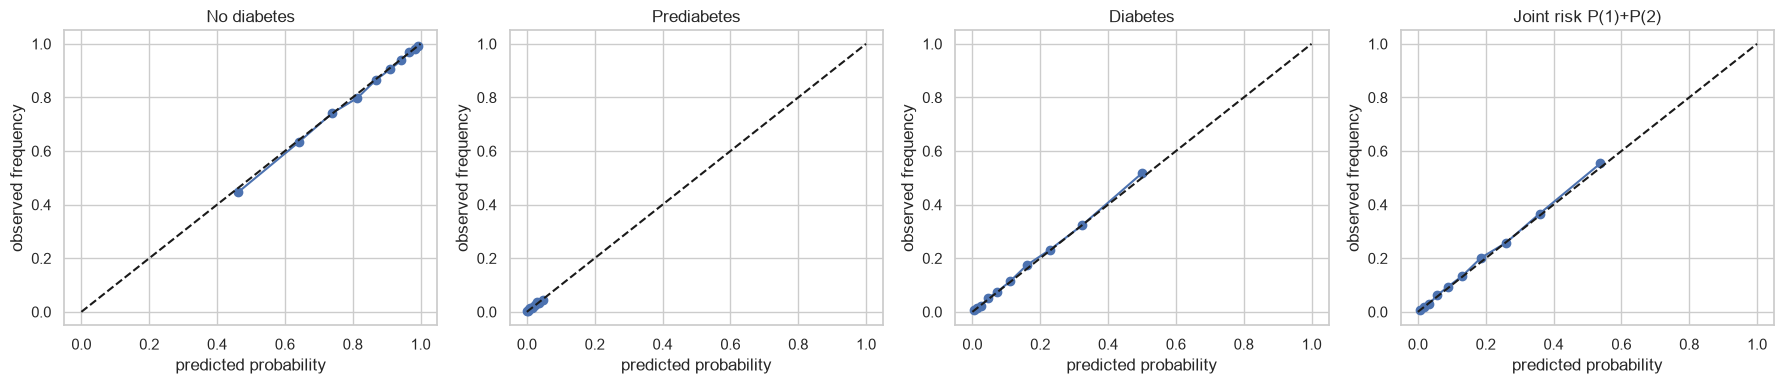

In [68]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for k, t in enumerate(["No diabetes", "Prediabetes", "Diabetes"]):
    fr, mp = calibration_curve(yte == k, P_te[:, k], n_bins=10, strategy="quantile")
    ax[k].plot(mp, fr, "o-"); ax[k].plot([0, 1], [0, 1], "k--"); ax[k].set_title(t)
fr, mp = calibration_curve(yte >= 1, P_te[:, 1] + P_te[:, 2], n_bins=10, strategy="quantile")
ax[3].plot(mp, fr, "o-"); ax[3].plot([0, 1], [0, 1], "k--"); ax[3].set_title("Joint risk P(1)+P(2)")
for a in ax: a.set_xlabel("predicted probability"); a.set_ylabel("observed frequency")
plt.tight_layout(); plt.show()

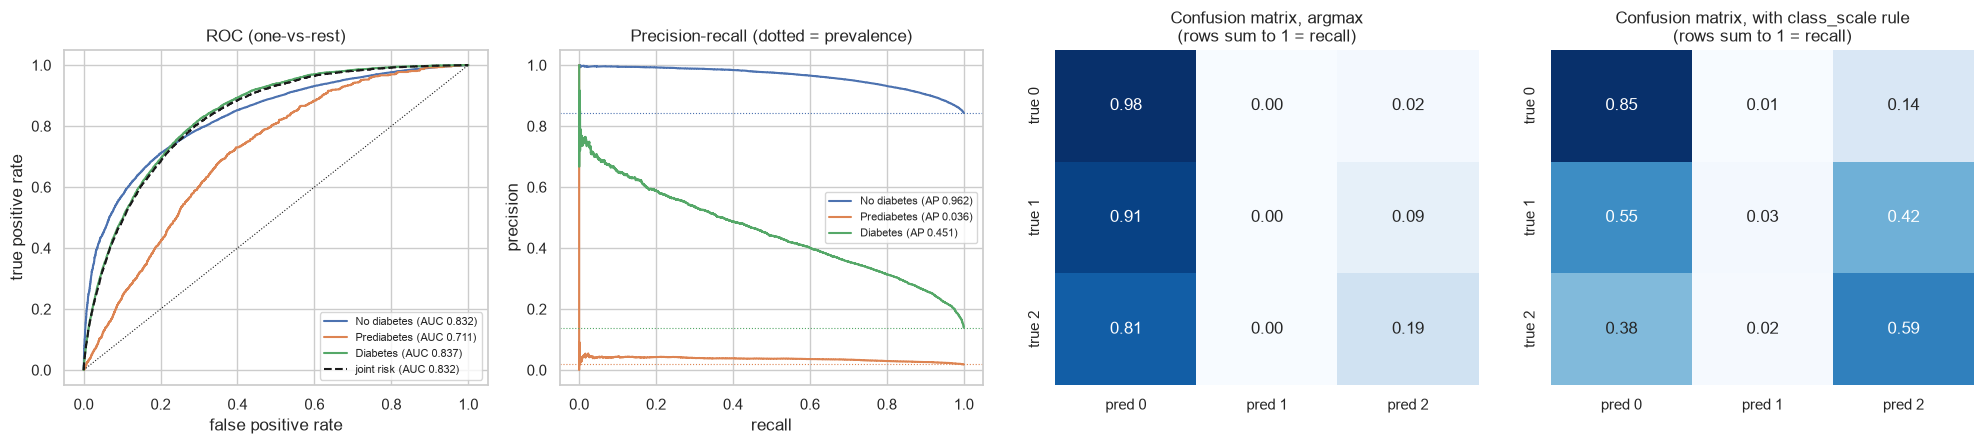

In [69]:
# ---------- ROC, precision-recall and confusion matrices of the final model (test) ----------
names3 = ["No diabetes", "Prediabetes", "Diabetes"]
fig, ax = plt.subplots(1, 4, figsize=(20, 4.6))
for k in range(3):
    fpr, tpr, _ = roc_curve(yte == k, P_te[:, k], sample_weight=wte)
    ax[0].plot(fpr, tpr, label=f"{names3[k]} (AUC {roc_auc_score(yte == k, P_te[:, k], sample_weight=wte):.3f})")
    pr, rc, _ = precision_recall_curve(yte == k, P_te[:, k], sample_weight=wte)
    ax[1].plot(rc, pr, label=f"{names3[k]} (AP {average_precision_score(yte == k, P_te[:, k], sample_weight=wte):.3f})")
    ax[1].axhline(np.average(yte == k, weights=wte), c=ax[1].lines[-1].get_color(), ls=':', lw=.8)       # dotted = prevalence = a random model
fpr, tpr, _ = roc_curve(yte >= 1, P_te[:, 1] + P_te[:, 2], sample_weight=wte)
ax[0].plot(fpr, tpr, 'k--', label=f"joint risk (AUC {roc_auc_score(yte >= 1, P_te[:, 1] + P_te[:, 2], sample_weight=wte):.3f})")
ax[0].plot([0, 1], [0, 1], 'k:', lw=.8); ax[0].set(title="ROC (one-vs-rest)", xlabel="false positive rate", ylabel="true positive rate"); ax[0].legend(fontsize=8)
ax[1].set(title="Precision-recall (dotted = prevalence)", xlabel="recall", ylabel="precision"); ax[1].legend(fontsize=8)
for a, pr_, ttl in [(ax[2], P_te.argmax(1), "Confusion matrix, argmax"), (ax[3], pred_te, "Confusion matrix, with class_scale rule")]:
    sns.heatmap(confusion_matrix(yte, pr_, sample_weight=wte, normalize="true"), annot=True, fmt=".2f", cmap="Blues", cbar=False,
                xticklabels=["pred 0", "pred 1", "pred 2"], yticklabels=["true 0", "true 1", "true 2"], ax=a); a.set_title(ttl + "\n(rows sum to 1 = recall)")
plt.tight_layout(); plt.show()

The calibration curves are the visual answer to the general objective: points on the diagonal mean "when the model says 30 %, about 30 % really have it".

## 3.12 Interpretation
Why interpret? A black-box score is hard to trust or to explain. Three complementary views:
- **Permutation importance** (on log-loss): how much does the probability quality drop when one variable is shuffled?
- **Surrogate tree:** a shallow tree trained to imitate the opaque model; its *fidelity* says how well a simple rule set summarises it.
- **Odds ratios** of the logistic model (from `logit_L2` fitted on train, relative to class 0). For numeric/ordinal variables the OR is per +1 standard deviation (they were standardised). **Reading warning:** these are *associations*; recall the counter-intuitive signs from the EDA (CholCheck → detection bias; HvyAlcoholConsump → "sick quitter").

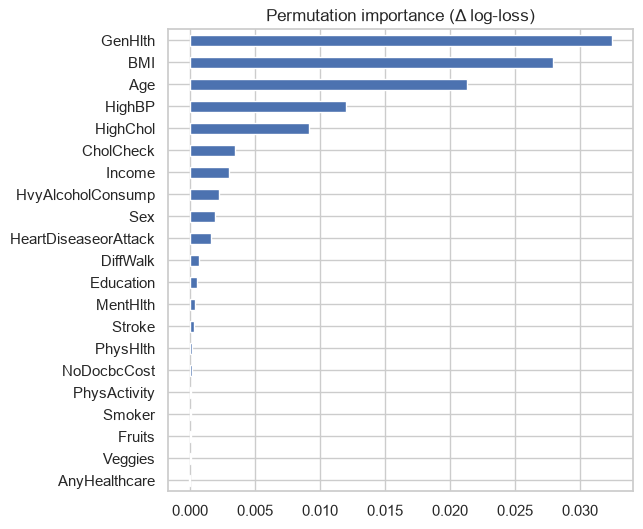

Surrogate tree fidelity: 0.975


,OR prediabetes vs none,OR diabetes vs none
CholCheck,1.816,3.508
HighBP,1.469,2.146
HighChol,1.750,1.819
GenHlth,1.376,1.785
BMI,1.402,1.534
Age,1.456,1.485
Sex,1.123,1.295
HeartDiseaseorAttack,0.941,1.247
Stroke,0.925,1.135
DiffWalk,0.999,1.131


In [70]:
pi_clf = permutation_importance(final, Xte, yte, scoring="neg_log_loss", n_repeats=5, random_state=SEED, sample_weight=wte)
imp = pd.Series(pi_clf.importances_mean, index=Xte.columns).sort_values(ascending=False)
imp.plot(kind="barh", figsize=(6, 6)).invert_yaxis(); plt.title("Permutation importance (Δ log-loss)"); plt.show()

surrogate = DecisionTreeClassifier(max_depth=4, min_samples_leaf=200, random_state=SEED).fit(Xte, P_te.argmax(1))
print("Surrogate tree fidelity:", round((surrogate.predict(Xte) == P_te.argmax(1)).mean(), 3))

# Odds ratios of the logistic model (scaled variables: effect of +1 SD for numeric/ordinal)
lg = fit_w(MODELS["logit_L2"], Xtr, ytr, wtr)
names = BIN + ORD + NUM
cf = lg.steps[-1][1].coef_                                   # softmax: expressed relative to class 0
odds = pd.DataFrame({"OR prediabetes vs none": np.exp(cf[1] - cf[0]), "OR diabetes vs none": np.exp(cf[2] - cf[0])}, index=names)
odds.sort_values("OR diabetes vs none", ascending=False).round(3)

## 3.13 Verdicts on H1–H6
Each hypothesis is evaluated **with its pre-fixed criterion** (see the top of the notebook) and stored in `VERDICT`. They are read together in Part 5.

In [71]:
# H1: AUC diabetes-vs-rest on test within [0.70, 0.85]
auc_d = test_metrics["auc_diab"]
VERDICT["H1"] = (0.70 <= auc_d <= 0.85, f"test AUC(diabetes vs rest) = {auc_d:.3f} (criterion 0.70–0.85)")

# H2: AUC gain of non-linear models over the spline logistic < 0.02 (repeated CV)
gain = {k: results[k]["auc_ovr"].mean() - results["logit_L2_spline"]["auc_ovr"].mean() for k in ["hgb_tuned", "rf_tuned"]}
VERDICT["H2"] = (max(gain.values()) < 0.02, "max AUC gain over logit_L2_spline = " + ", ".join(f"{k}: {v:+.4f}" for k, v in gain.items()) + " (criterion < 0.02)")

# H3: prediabetes has the lowest F1 and the lowest per-class AUC on test
auc0 = roc_auc_score(yte == 0, P_te[:, 0], sample_weight=wte)
f1s = {0: float(test_metrics["f1_0"]), 1: float(test_metrics["f1_1"]), 2: float(test_metrics["f1_2"])}
aucs = {0: float(auc0), 1: float(test_metrics["auc_prediab"]), 2: float(test_metrics["auc_diab"])}
VERDICT["H3"] = (min(f1s, key=f1s.get) == 1 and min(aucs, key=aucs.get) == 1,
                 f"F1 by class = {[round(v, 3) for v in f1s.values()]} | AUC by class = {[round(v, 3) for v in aucs.values()]}")

# H4: top-10 variables lose < 0.01 AUC (repeated CV, selection inside folds)
a_base = abl["base"]["auc_ovr"].mean(); a_top10 = abl["top10 (H4)"]["auc_ovr"].mean()
VERDICT["H4"] = (a_base - a_top10 < 0.01, f"AUC loss with top-10 = {a_base - a_top10:.4f} (criterion < 0.01); with top-15: {a_base - abl['top15 (H4)']['auc_ovr'].mean():.4f}")

# H5: removing Education and Income lowers AUC < 0.005
a_noei = abl["without Education/Income (H5)"]["auc_ovr"].mean()
VERDICT["H5"] = (a_base - a_noei < 0.005, f"AUC loss without Education/Income = {a_base - a_noei:.4f} (criterion < 0.005)")

# H6: (a) uncalibrated trees/boosting have worse Brier than the logistic; (b) calibrating improves their Brier
b_logit = results["logit_L2"]["brier"].mean()
raw = {m: float(results[m]["brier"].mean()) for m in ["rf_tuned", "hgb_tuned", "tree_pruned"]}
calibrated = {m: float(min(cal[f"{m}+sigmoid"]["brier"].mean(), cal[f"{m}+isotonic"]["brier"].mean())) for m in raw}
part_a = all(v > b_logit for v in raw.values()); part_b = all(calibrated[m] < raw[m] for m in raw)
VERDICT["H6"] = (part_a and part_b,
                 f"(a) raw worse than logit in Brier: {part_a} | (b) calibration lowers Brier: {part_b} "
                 f"[logit {b_logit:.4f}; raw {({m: round(v, 4) for m, v in raw.items()})}; calibrated {({m: round(v, 4) for m, v in calibrated.items()})}]")
for k_, (ok, msg) in VERDICT.items():
    if k_ in ("H1", "H2", "H3", "H4", "H5", "H6"): print(f"{k_} ·", "HOLDS    " if ok else "DOES NOT HOLD", "·", msg)

H1 · HOLDS     · test AUC(diabetes vs rest) = 0.837 (criterion 0.70–0.85)
H2 · HOLDS     · max AUC gain over logit_L2_spline = hgb_tuned: +0.0029, rf_tuned: -0.0045 (criterion < 0.02)
H3 · HOLDS     · F1 by class = [0.885, 0.034, 0.478] | AUC by class = [0.832, 0.711, 0.837]
H4 · DOES NOT HOLD · AUC loss with top-10 = 0.0390 (criterion < 0.01); with top-15: 0.0021
H5 · HOLDS     · AUC loss without Education/Income = 0.0024 (criterion < 0.005)
H6 · DOES NOT HOLD · (a) raw worse than logit in Brier: False | (b) calibration lowers Brier: False [logit 0.2262; raw {'rf_tuned': 0.2223, 'hgb_tuned': 0.2215, 'tree_pruned': 0.2277}; calibrated {'rf_tuned': 0.2221, 'hgb_tuned': 0.2217, 'tree_pruned': 0.2267}]


## 3.14 Beyond the metrics: turning probabilities into decisions (cost-sensitive threshold)
AUC and F1 say how good the *scores* are, not which **action** to take. A screening programme must decide whom to refer for a blood test: flag a person if their joint risk P(1)+P(2) exceeds a threshold *t*. The right *t* depends on how much worse a **missed case** (false negative, cost *r*) is compared with an **unnecessary test** (false positive, cost 1).

- **Theory:** if the probabilities are well calibrated, the cost-minimising rule is to flag when **P ≥ 1/(1+r)**. For example r = 10 ⇒ t = 0.09.
- **Practice:** the empirical optimum is sought on the **out-of-fold predictions of train** (no test involved) and compared with the theoretical value — a direct *calibration check*: if both agree, the probabilities can be trusted as risks.
- **Decision curve (net benefit):** shows, for each threshold, the benefit of using the model versus "flag everybody" and "flag nobody" (Vickers & Elkin). A model is only useful in the range of thresholds where its curve lies above both.

All weighted with `w`; the threshold is fixed on train OOF and **evaluated once on test**.

                     t_theory  t_empirical  flagged_pct  sensitivity  specificity   PPV  cost_model  cost_flag_all  cost_flag_none
cost_ratio_FN_to_FP                                                                                                               
1                       0.500        0.520        4.519        0.180        0.980 0.626       0.146          0.843           0.157
2                       0.333        0.320       16.657        0.500        0.896 0.471       0.245          0.843           0.314
5                       0.167        0.170       34.461        0.772        0.735 0.352       0.402          0.843           0.785
10                      0.091        0.080       53.519        0.918        0.536 0.269       0.519          0.843           1.570
20                      0.048        0.045       65.665        0.964        0.401 0.231       0.617          0.843           3.139


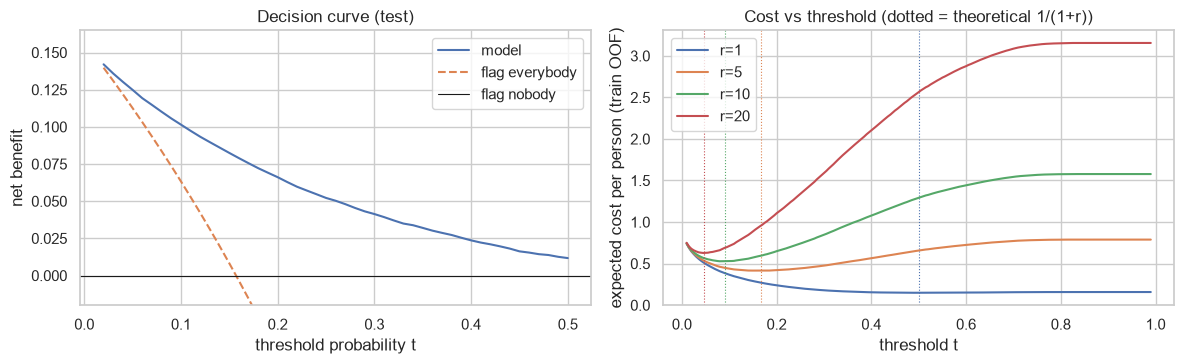

In [72]:
P_risk_oof, y_risk_tr = P_oof[:, 1] + P_oof[:, 2], (ytr >= 1).astype(int)
P_risk_te,  y_risk_te = P_te[:, 1] + P_te[:, 2],   (yte >= 1).astype(int)
ts = np.linspace(0.01, 0.99, 197)

def wcost(y, flag, w, r):
    fn = np.sum(w * ((y == 1) & ~flag)); fp = np.sum(w * ((y == 0) & flag))
    return (r * fn + fp) / w.sum()

rows_ = []
for r in (1, 2, 5, 10, 20):
    costs = np.array([wcost(y_risk_tr, P_risk_oof >= t, wtr, r) for t in ts]); t_emp = ts[costs.argmin()]; flag = P_risk_te >= t_emp
    tp = np.sum(wte * (flag & (y_risk_te == 1))); fp = np.sum(wte * (flag & (y_risk_te == 0)))
    rows_.append(dict(cost_ratio_FN_to_FP=r, t_theory=1 / (1 + r), t_empirical=t_emp, flagged_pct=100 * np.average(flag, weights=wte),
                      sensitivity=tp / np.sum(wte * (y_risk_te == 1)), specificity=1 - fp / np.sum(wte * (y_risk_te == 0)), PPV=tp / max(tp + fp, 1e-9),
                      cost_model=wcost(y_risk_te, flag, wte, r), cost_flag_all=wcost(y_risk_te, np.ones(len(flag), bool), wte, r),
                      cost_flag_none=wcost(y_risk_te, np.zeros(len(flag), bool), wte, r)))
thr_tab = pd.DataFrame(rows_).set_index("cost_ratio_FN_to_FP")
with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 200):
    print(thr_tab)
thr_tab.to_csv(RESULTS_DIR / "cost_sensitive_thresholds.csv")

# decision curve (test)
tt = np.linspace(0.02, 0.5, 49); prev = np.average(y_risk_te, weights=wte); N_ = wte.sum()
nb_model = [(np.sum(wte * ((P_risk_te >= t) & (y_risk_te == 1))) - np.sum(wte * ((P_risk_te >= t) & (y_risk_te == 0))) * t / (1 - t)) / N_ for t in tt]
nb_all = prev - (1 - prev) * tt / (1 - tt)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(tt, nb_model, label="model"); ax[0].plot(tt, nb_all, '--', label="flag everybody"); ax[0].axhline(0, c='k', lw=.8, label="flag nobody")
ax[0].set(ylim=(-0.02, prev * 1.05), xlabel="threshold probability t", ylabel="net benefit", title="Decision curve (test)"); ax[0].legend()
for r, c in zip((1, 5, 10, 20), ('C0', 'C1', 'C2', 'C3')):
    ax[1].plot(ts, [wcost(y_risk_tr, P_risk_oof >= t, wtr, r) for t in ts], c=c, label=f"r={r}"); ax[1].axvline(1 / (1 + r), c=c, ls=':', lw=.8)
ax[1].set(xlabel="threshold t", ylabel="expected cost per person (train OOF)", title="Cost vs threshold (dotted = theoretical 1/(1+r))"); ax[1].legend()
plt.tight_layout(); plt.show()



## 3.15 Does the model work equally well for everybody? (subgroup analysis)
A single global AUC can hide a model that works well for some people and badly for others. Compared on **test**: the joint-risk AUC, the calibration-in-the-large (observed ÷ predicted risk; 1 = perfectly calibrated on average) and the observed prevalence for subgroups of sex, age, income and education. The bootstrap gives a 95 % CI for each AUC. This is a descriptive fairness check, not a causal statement.

**H11 (fixed before running):** discrimination falls with age because almost everybody older has risk factors — the AUC for 60+ is **more than 0.03 lower** than for 18–39.

                                share_pct  observed_risk  mean_predicted  obs_over_pred   AUC  AUC_lo  AUC_hi
variable  group                                                                                              
Sex       Female                   55.532          0.148           0.147          1.005 0.840   0.833   0.846
          Male                     44.468          0.169           0.168          1.005 0.822   0.816   0.828
Age       18-39                    15.135          0.039           0.038          1.033 0.833   0.804   0.855
          40-59                    36.662          0.123           0.123          0.999 0.844   0.835   0.851
          60+                      48.202          0.220           0.219          1.006 0.782   0.774   0.788
Income    low (1-3)                14.606          0.280           0.266          1.051 0.786   0.773   0.797
          mid (4-6)                32.415          0.189           0.188          1.003 0.803   0.795   0.812
          

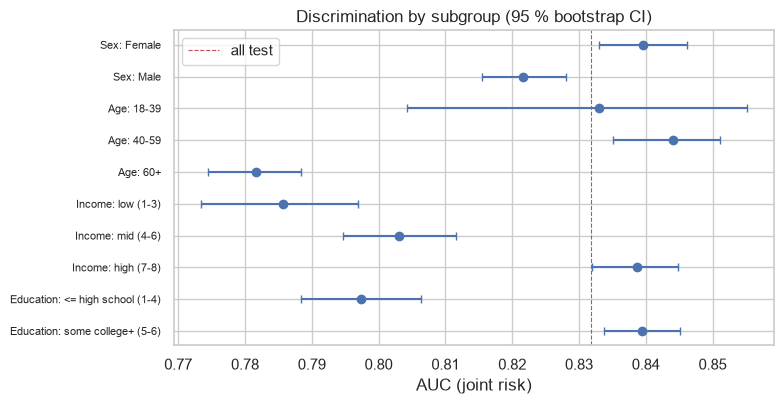

H11 · HOLDS     · AUC(18-39) = 0.833, AUC(60+) = 0.782, difference = +0.051 (criterion > 0.03)


In [73]:
age_, inc_, edu_ = Xte["Age"], Xte["Income"], Xte["Education"]
groups = {"Sex": {"Female": Xte["Sex"] == 0, "Male": Xte["Sex"] == 1},
          "Age": {"18-39": age_ <= 4, "40-59": (age_ >= 5) & (age_ <= 8), "60+": age_ >= 9},
          "Income": {"low (1-3)": inc_ <= 3, "mid (4-6)": (inc_ >= 4) & (inc_ <= 6), "high (7-8)": inc_ >= 7},
          "Education": {"<= high school (1-4)": edu_ <= 4, "some college+ (5-6)": edu_ >= 5}}
rb_ = np.random.RandomState(SEED + 21); n_bs = 30 if FAST else 200
rows_ = []
for var, gs in groups.items():
    for gname, mask in gs.items():
        m = np.asarray(mask); y_, p_, w_ = y_risk_te[m], P_risk_te[m], wte[m]
        if len(np.unique(y_)) < 2: continue
        bs = []
        for _ in range(n_bs):
            i = rb_.randint(0, len(y_), len(y_))
            if len(np.unique(y_[i])) == 2: bs.append(roc_auc_score(y_[i], p_[i], sample_weight=w_[i]))
        rows_.append(dict(variable=var, group=gname, share_pct=100 * w_.sum() / wte.sum(), observed_risk=np.average(y_, weights=w_),
                          mean_predicted=np.average(p_, weights=w_), obs_over_pred=np.average(y_, weights=w_) / np.average(p_, weights=w_),
                          AUC=roc_auc_score(y_, p_, sample_weight=w_), AUC_lo=np.quantile(bs, .025), AUC_hi=np.quantile(bs, .975)))
sub_tab = pd.DataFrame(rows_).set_index(["variable", "group"])
with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 200):
    print(sub_tab)
sub_tab.to_csv(RESULTS_DIR / "subgroup_performance.csv")

fig, ax = plt.subplots(figsize=(8, 4.2)); yy = np.arange(len(sub_tab))[::-1]
ax.errorbar(sub_tab["AUC"], yy, xerr=[sub_tab["AUC"] - sub_tab["AUC_lo"], sub_tab["AUC_hi"] - sub_tab["AUC"]], fmt='o', capsize=3)
ax.axvline(roc_auc_score(y_risk_te, P_risk_te, sample_weight=wte), c='r', ls='--', lw=.8, label="all test")
ax.set_yticks(yy); ax.set_yticklabels([f"{v}: {g}" for v, g in sub_tab.index], fontsize=8); ax.set(xlabel="AUC (joint risk)", title="Discrimination by subgroup (95 % bootstrap CI)"); ax.legend()
plt.tight_layout(); plt.show()

auc_young, auc_old = sub_tab.loc[("Age", "18-39"), "AUC"], sub_tab.loc[("Age", "60+"), "AUC"]
VERDICT["H11"] = (auc_young - auc_old > 0.03, f"AUC(18-39) = {auc_young:.3f}, AUC(60+) = {auc_old:.3f}, difference = {auc_young - auc_old:+.3f} (criterion > 0.03)")
ok, msg = VERDICT["H11"]; print("H11 ·", "HOLDS    " if ok else "DOES NOT HOLD", "·", msg)

## 3.16 Learning curves: would more data help?
Training and validation error against the **amount of training data** diagnose the situation: a large gap that shrinks with more data means high variance (more data helps); two curves that meet high up mean high bias (a richer model or better features are needed, not more rows). The validation part is a fixed 20 % stratified hold-out *inside train*; the test set is not used.

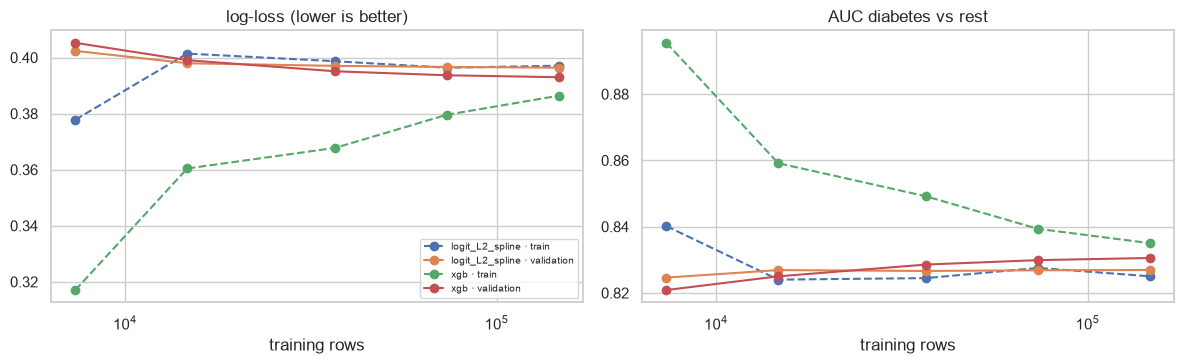

split                    train  validation
model           n                         
logit_L2_spline 7352    0.3778      0.4024
                14705   0.4014      0.3980
                36764   0.3987      0.3970
                73529   0.3964      0.3966
                147059  0.3971      0.3964
xgb             7352    0.3171      0.4052
                14705   0.3604      0.3991
                36764   0.3678      0.3951
                73529   0.3796      0.3937
                147059  0.3864      0.3930


In [74]:
def learning_curves():
    tr_i, va_i = train_test_split(np.arange(len(ytr)), test_size=0.2, stratify=ytr, random_state=SEED)
    rs_ = np.random.RandomState(SEED + 11); out = []
    for name in ["logit_L2_spline", best_name]:
        for f in N_LEARN:
            sub = tr_i if f >= 1 else np.sort(rs_.choice(tr_i, int(f * len(tr_i)), replace=False))
            m = fit_w(MODELS[name], Xtr.iloc[sub], ytr[sub], wtr[sub])
            for split, ix in (("train", sub), ("validation", va_i)):
                mt = metrics_clf(ytr[ix], m.predict_proba(Xtr.iloc[ix]), wtr[ix])
                out.append(dict(model=name, frac=f, n=len(sub), split=split, logloss=mt["logloss"], auc_diab=mt["auc_diab"]))
    return pd.DataFrame(out)
lc = cached("clf_learning_curves", learning_curves, sig=f"{MODELS['logit_L2_spline']!r}|{MODELS[best_name]!r}|{N_LEARN}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for (name, split), g in lc.groupby(["model", "split"]):
    for a, col in zip(ax, ["logloss", "auc_diab"]):
        a.plot(g["n"], g[col], marker="o", ls="-" if split == "validation" else "--", label=f"{name} · {split}")
for a, t in zip(ax, ["log-loss (lower is better)", "AUC diabetes vs rest"]): a.set(xscale="log", xlabel="training rows", title=t)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()
print(lc.pivot_table(index=["model", "n"], columns="split", values="logloss").round(4))

## 3.17 Imbalance: weights vs no weights vs SMOTE
§3.7 already showed that `class_weight="balanced"` damages the probabilities. SMOTE is the other popular remedy: it **creates synthetic minority examples** by interpolating between neighbours. Two points to keep in mind: (i) it must happen **inside each training fold** — resampling before the CV leaks synthetic copies of validation points into training; (ii) it changes the class prior the model sees, so the probabilities will be wrong unless recalibrated. `SMOTENC` (binary variables are treated as categorical) is used on the tuning subsample, with the tuned HGB, and the *usual* metrics are reported next to the *probability* metrics. SMOTE ignores the frequency weights, so the fair baseline is the unweighted model.

In [75]:
try:
    from imblearn.over_sampling import SMOTENC
    HAVE_IMB = True
except ImportError:
    HAVE_IMB = False; print("imbalanced-learn not installed -> SMOTE comparison skipped (pip install imbalanced-learn)")

if HAVE_IMB:
    Xs_, ys_, ws_ = Xtr.iloc[idx_tune], ytr[idx_tune], wtr[idx_tune]
    hgb_clf = clone(MODELS["hgb_tuned"].steps[-1][1]); prep_t = MODELS["hgb_tuned"].steps[0][1]
    cat_idx = list(range(len(BIN)))                                  # binary columns come first in make_prep("tree")

    def cv_smote():
        rows = []
        for tr, va in StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED).split(Xs_, ys_):
            pr = clone(prep_t).fit(Xs_.iloc[tr]); Xt, Xv = pr.transform(Xs_.iloc[tr]), pr.transform(Xs_.iloc[va])
            Xr, yr = SMOTENC(categorical_features=cat_idx, random_state=SEED).fit_resample(Xt, ys_[tr])
            m = clone(hgb_clf).fit(Xr, yr); rows.append(metrics_clf(ys_[va], m.predict_proba(Xv), ws_[va]))
        o = pd.DataFrame(rows); o.insert(0, "model", "SMOTE (unweighted)"); return o
    arms = {"weights w (chosen approach)": cv_eval_sub(MODELS["hgb_tuned"], "hgb weighted (SMOTE rows)", X=Xs_, y=ys_, w=ws_),
            "no weights": None, "SMOTE (unweighted)": cached("clf_smote", cv_smote, sig=f"{hgb_clf!r}|{len(idx_tune)}")}
    def cv_unw():
        rows = []
        for tr, va in StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED).split(Xs_, ys_):
            m = fit_w(MODELS["hgb_tuned"], Xs_.iloc[tr], ys_[tr], None); rows.append(metrics_clf(ys_[va], m.predict_proba(Xs_.iloc[va]), ws_[va]))
        o = pd.DataFrame(rows); o.insert(0, "model", "no weights"); return o
    arms["no weights"] = cached("clf_unweighted_sub", cv_unw, sig=f"{MODELS['hgb_tuned']!r}|{len(idx_tune)}")
    smote_tab = pd.concat([v.assign(model=k) for k, v in arms.items()]).groupby("model", sort=False)[["auc_ovr", "macro_f1", "f1_1", "bal_acc", "logloss", "brier", "ece_risk"]].mean()
    print(smote_tab.round(4))

                             auc_ovr  macro_f1    f1_1  bal_acc  logloss  \
model                                                                      
weights w (chosen approach)   0.7823    0.3945  0.0000   0.3848   0.3967   
no weights                    0.7813    0.3932  0.0000   0.3838   0.3972   
SMOTE (unweighted)            0.7488    0.4402  0.0127   0.4329   0.4987   

                              brier  ece_risk  
model                                          
weights w (chosen approach)  0.2224    0.0081  
no weights                   0.2224    0.0100  
SMOTE (unweighted)           0.2676    0.1396  


> **Expected reading.** SMOTE raises the *hard-label* metrics for the rare class (F1 of prediabetes, balanced accuracy) but worsens log-loss, Brier and ECE — the model now believes the minority is far more common than it is. That trade-off is why this project keeps the natural class balance, uses weights, and obtains macro-F1 with the separate `class_scale` rule of §3.10, which leaves the probabilities untouched.

## 3.18 All the trained models, saved
"Trained" has to mean something durable. Here **every** model of the study is refitted once on all of train (KNN and the SVMs on their subsamples, as everywhere), evaluated on test **for reporting only** (the choice of the final model was made in §3.10 with CV, so showing the others on test does not leak anything into the selection) and written to `models/`. The final classifier is stored together with its `class_scale` decision rule, and reloaded to prove that the saved file gives identical predictions.

In [76]:
def fit_zoo():
    out = {}
    for k, m in MODELS.items():
        if k in results:
            t0 = time.time(); out[k] = fit_w(m, Xtr, ytr, wtr); print(f"  fitted {k:18s} {time.time()-t0:5.0f}s")
    kn = Pipeline([("prep", make_prep("linear")), ("clf", KNNSmooth(100 if not FAST else 25))]).fit(Xk, yk); out["knn (subsample)"] = kn
    out["svm_rbf_tuned (subsample)"] = fit_w(svm_pipe(*SVM_BEST), Xsv, ysv, wsv)
    return out
zoo = fit_zoo()                                  # (about the cost of one pass of §3.4 / 10 folds)
rows_ = {}
for k, m in zoo.items():
    P = m.predict_proba(Xte); rows_[k] = metrics_clf(yte, P, wte)
    joblib.dump(m, MODELS_DIR / f"clf_{re.sub(r'[^A-Za-z0-9]+', '_', k)}.joblib", compress=3)
zoo_tab = pd.DataFrame(rows_).T.sort_values("logloss")
zoo_tab["selected"] = [k == best_name for k in zoo_tab.index]
with pd.option_context("display.float_format", "{:.4f}".format, "display.width", 220):
    print(zoo_tab[["auc_ovr", "auc_diab", "auc_prediab", "macro_f1", "bal_acc", "logloss", "brier", "ece_risk", "selected"]])
zoo_tab.to_csv(RESULTS_DIR / "classification_test_all_models.csv")

joblib.dump({"model": final, "class_scale": class_scale, "classes": [0, 1, 2], "name": best_name}, MODELS_DIR / "FINAL_classifier.joblib", compress=3)
chk = joblib.load(MODELS_DIR / "FINAL_classifier.joblib")
assert np.allclose(chk["model"].predict_proba(Xte), P_te) and ((chk["model"].predict_proba(Xte) * chk["class_scale"]).argmax(1) == pred_te).all()
sizes_mb = pd.Series({f.name: f.stat().st_size / 1e6 for f in MODELS_DIR.glob("*.joblib")}).sort_values(ascending=False)
print("\nSaved:", len(sizes_mb), "models in", MODELS_DIR, f"({sizes_mb.sum():.0f} MB in total; largest: {sizes_mb.index[0]} = {sizes_mb.iloc[0]:.0f} MB)")
print("FINAL_classifier.joblib reloads with identical predictions. Tip: do not commit large .joblib files to GitHub (100 MB limit): keep models/ in .gitignore or use Git LFS.")

  fitted logit_L2               3s
  fitted logit_L2_spline        3s
  fitted logit_lasso          100s
  fitted lda                    1s
  fitted tree_pruned            1s
  fitted rf                     8s
  fitted hgb                    4s
  fitted xgb                    7s
  fitted qda                    0s
  fitted nb_gauss               0s
  fitted nb_categorical         1s
  fitted rf_tuned               9s
  fitted hgb_tuned             15s
                           auc_ovr  auc_diab  auc_prediab  macro_f1  bal_acc  logloss  brier  ece_risk  selected
xgb                         0.7932    0.8372       0.7105    0.4031   0.3908   0.3869 0.2162    0.0033      True
hgb                         0.7920    0.8364       0.7085    0.4022   0.3900   0.3875 0.2166    0.0043     False
hgb_tuned                   0.7932    0.8361       0.7124    0.4054   0.3926   0.3877 0.2168    0.0058     False
logit_L2_spline             0.7900    0.8329       0.7091    0.4054   0.3930   0.3905 0.2180 

# Part 4 · Unsupervised learning: health profiles (objective O3)

**Question:** are there natural groups of health profiles, and do they relate to diabetes status — *without* the algorithm ever seeing the diabetes label?

**Design choices (all follow from the EDA):**
- **Which data:** the 21 predictors of the training set, resampled **with probability ∝ `w`** (20,000 people) so that the sample represents the original population instead of over-representing rare unique profiles. The target is **excluded from the fit** and used only afterwards to *describe* the clusters; otherwise the "relation with diabetes" would be circular.
- **Scaling:** all variables are standardised, because k-means uses Euclidean distance and BMI (range ~12–98) would otherwise dominate the 0/1 binaries.
- **Distance / algorithm:** with so many binary variables, Euclidean k-means is an approximation (k-prototypes or Gower distance with k-medoids are the "proper" mixed-data alternatives, but too expensive for this many rows). Noise is reduced with **PCA keeping 80 % of the variance** (§1.9 showed the structure is mostly a gradient), and the result is cross-checked with a **hierarchical (Ward) clustering** on a smaller subsample.
- **Choosing k:** silhouette (separation) and **stability** (do two independent halves of the data find the same groups?). Because EDA §1.9 showed a continuous gradient, k = 2 tends to be a trivial split along PC1; **k ≥ 3** is required and the best silhouette in that range is taken (a judgement call, stated explicitly).
- **Profiling:** diabetes prevalence per cluster, ARI against the true classes, mean of key variables.

PCA keeps 14 components for 80 % of the variance
      inertia  silhouette  stability_ARI
k                                       
2  291424.547       0.218          0.973
3  271647.920       0.233          0.690
4  254124.157       0.106          0.658
5  237595.850       0.117          0.815
6  221416.804       0.132          0.521
7  206957.649       0.141          0.549
8  197158.814       0.135          0.503

Chosen k = 3


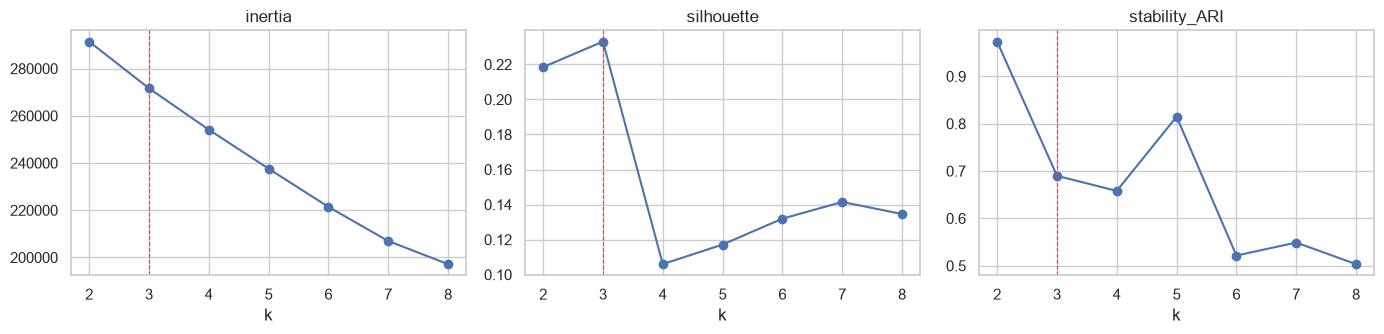

In [77]:
FIG_TAG = "unsup"                                    # prefix of the figure files saved by this part
rs_cl = np.random.RandomState(SEED)
n_cl = N_CLUST
ix = rs_cl.choice(len(df_train), n_cl, p=df_train['w'].to_numpy(float) / df_train['w'].sum())   # population-representative sample
X_cl, y_cl = df_train.iloc[ix][FEATS].reset_index(drop=True), df_train.iloc[ix][target].astype(int).reset_index(drop=True)

Zc = StandardScaler().fit_transform(X_cl)
pca_cl = PCA(n_components=0.80, random_state=SEED).fit(Zc)
Zp = pca_cl.transform(Zc)
print(f"PCA keeps {pca_cl.n_components_} components for 80 % of the variance")

def stability(k, reps=3):
    # ARI between clusterings fitted on two independent halves, both applied to the whole sample
    out = []
    for r in range(reps):
        perm_ = rs_cl.permutation(len(Zp)); h1, h2 = perm_[:len(Zp)//2], perm_[len(Zp)//2:]
        l1 = KMeans(k, n_init=5, random_state=SEED + r).fit(Zp[h1]).predict(Zp)
        l2 = KMeans(k, n_init=5, random_state=SEED + 10 + r).fit(Zp[h2]).predict(Zp)
        out.append(adjusted_rand_score(l1, l2))
    return float(np.mean(out))

sil_idx = rs_cl.choice(len(Zp), min(5000, len(Zp)), replace=False)       # silhouette is O(n²): use a subsample
rows = []
for k in range(2, 9):
    km = KMeans(k, n_init=10, random_state=SEED).fit(Zp)
    rows.append(dict(k=k, inertia=km.inertia_, silhouette=silhouette_score(Zp[sil_idx], km.labels_[sil_idx]),
                     stability_ARI=stability(k)))
sel = pd.DataFrame(rows).set_index('k')
print(sel.round(3))

k_best = int(sel.loc[3:, 'silhouette'].idxmax())                          # k >= 3, see the design notes
print("\nChosen k =", k_best)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, col in zip(ax, ['inertia', 'silhouette', 'stability_ARI']):
    sel[col].plot(marker='o', ax=a, title=col); a.axvline(k_best, c='r', ls='--', lw=.8)
plt.tight_layout(); plt.show()

### Profiling the clusters (this is where the target is finally used)
- **Prevalence per cluster:** the share of prediabetes/diabetes in each group.
- **ARI vs the true classes:** a low ARI means the clusters are *not* a re-discovery of the label — they capture overall health profiles, which only partly relate to diabetes (exactly what H8 predicts).
- **Hierarchical cross-check:** do Ward linkage and k-means agree on a smaller subsample? If yes, the structure is not an artefact of k-means.

         size_%  % no diabetes  % prediabetes  % diabetes  % joint risk
cluster                                                                
0          69.6           90.6            1.5         7.9           9.4
1          26.7           66.4            3.1        30.5          33.6
2           3.7           96.1            0.5         3.4           3.9

Means of key variables per cluster:
         GenHlth    BMI   Age  Income  Education  HighBP  HighChol  DiffWalk  \
cluster                                                                        
0           2.11  27.43  7.59    6.71       5.29    0.32      0.35      0.02   
1           3.56  30.82  9.35    4.39       4.46    0.74      0.63      0.55   
2           2.21  27.39  6.54    5.86       5.05    0.17      0.21      0.08   

         PhysActivity  PhysHlth  
cluster                          
0                0.86      1.30  
1                0.50     11.99  
2                0.73      2.26  

ARI (clusters vs true classes) 

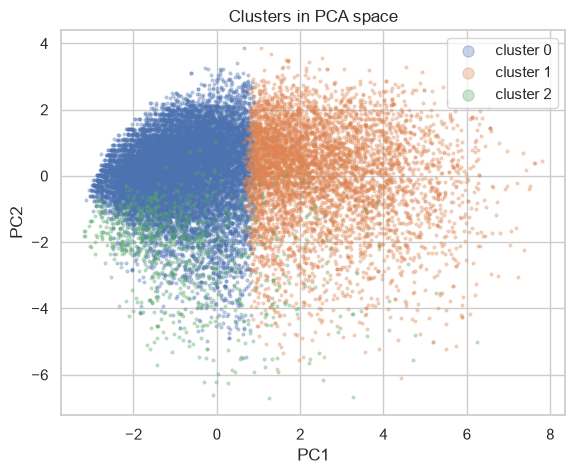

In [78]:
km_final = KMeans(k_best, n_init=20, random_state=SEED).fit(Zp)
lab = pd.Series(km_final.labels_, name='cluster')

prof = pd.DataFrame({'size_%': lab.value_counts(normalize=True).sort_index() * 100,
                     '% no diabetes': pd.crosstab(lab, y_cl, normalize='index')[0] * 100,
                     '% prediabetes': pd.crosstab(lab, y_cl, normalize='index')[1] * 100,
                     '% diabetes':    pd.crosstab(lab, y_cl, normalize='index')[2] * 100})
prof['% joint risk'] = prof['% prediabetes'] + prof['% diabetes']
key_vars = ['GenHlth', 'BMI', 'Age', 'Income', 'Education', 'HighBP', 'HighChol', 'DiffWalk', 'PhysActivity', 'PhysHlth']
print(prof.round(1))
print("\nMeans of key variables per cluster:")
print(X_cl.groupby(lab)[key_vars].mean().round(2))

ari_target = adjusted_rand_score(y_cl, lab)
ratio = prof['% diabetes'].max() / prof['% diabetes'].min()
print(f"\nARI (clusters vs true classes) = {ari_target:.3f} | max/min diabetes prevalence = {ratio:.2f}")

# Hierarchical cross-check (Ward) on a smaller subsample
sub_h = rs_cl.choice(len(Zp), 3000, replace=False)
ward = AgglomerativeClustering(n_clusters=k_best, linkage='ward').fit_predict(Zp[sub_h])
print(f"ARI Ward vs k-means on the same {len(sub_h)} people = {adjusted_rand_score(ward, lab.values[sub_h]):.3f}")

# Visual: clusters on the first two principal components
fig, ax = plt.subplots(figsize=(6.5, 5))
for c in range(k_best):
    m = lab.values == c
    ax.scatter(Zp[m, 0], Zp[m, 1], s=4, alpha=.3, label=f"cluster {c}")
ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.legend(markerscale=4); ax.set_title('Clusters in PCA space'); plt.show()

In [79]:
# ---------- Verdict on H8 ----------
VERDICT["H8"] = (ratio >= 2 and ari_target < 0.10,
                 f"max/min diabetes prevalence across clusters = {ratio:.2f} (criterion ≥ 2) | ARI vs target = {ari_target:.3f} (criterion < 0.10, a threshold fixed here because H8 only said 'low')")
ok, msg = VERDICT["H8"]; print("H8 ·", "HOLDS    " if ok else "DOES NOT HOLD", "·", msg)

H8 · DOES NOT HOLD · max/min diabetes prevalence across clusters = 9.06 (criterion ≥ 2) | ARI vs target = 0.140 (criterion < 0.10, a threshold fixed here because H8 only said 'low')


### Profile heatmap: what makes each cluster different?
The table above has the raw means; the heatmap shows each cluster's mean **in standard deviations from the overall mean** (blue/red = below/above average), which is the form that is easy to describe in words ("cluster 2 = older, higher BMI, hypertension, poor general health").

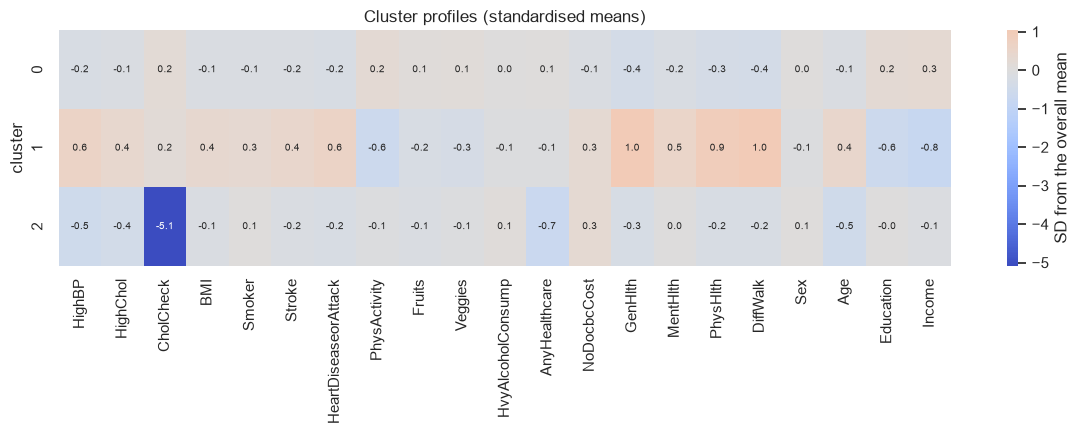

In [80]:
Zprof = (X_cl.groupby(lab).mean() - X_cl.mean()) / X_cl.std()
plt.figure(figsize=(12, 3 + .5 * k_best))
sns.heatmap(Zprof, cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, cbar_kws={"label": "SD from the overall mean"})
plt.title("Cluster profiles (standardised means)"); plt.ylabel("cluster"); plt.tight_layout(); plt.show()

### Beyond k-means: Gaussian mixtures, DBSCAN and hierarchical linkages
k-means is one choice among several; each family answers a different question and fails differently, which is what the chapter asks to compare:

| Method | Cluster shape it can find | Key choice | What is expected here |
|---|---|---|---|
| **k-means** | round, similar-size blobs (hard assignment) | *k* | the baseline |
| **Gaussian mixture (GMM)** | ellipsoids of different shape/size; **soft** assignment (probabilities of belonging) | *k*, chosen by **BIC** | k-means is a GMM with equal spherical clusters, so GMM should agree broadly but also show *how sure* each assignment is |
| **DBSCAN** | arbitrary shapes, finds **noise**; no *k* | ε (from the *k*-distance plot) and `min_samples` | the EDA showed one continuous gradient, not separated islands: expect one giant cluster plus noise — density-based methods need gaps in the density |
| **Hierarchical** (Ward, complete, average, single) | depends on the linkage | linkage, distance, **scaling** | Ward ≈ k-means; *single* chains everything into one cluster; unscaled data is dominated by BMI |

        BIC       AIC
k                    
2  664697.0  662808.0
3  457694.0  454857.0
4  420050.0  416264.0
5  311853.0  307119.0
6  302391.0  296709.0
7  242602.0  235971.0
8  177319.0  169739.0

BIC is minimal at k = 8  (k-means chose k = 3; BIC keeps decreasing with n this large, so it tends to over-split a continuous gradient)
GMM with k = 3: ARI vs k-means = 0.236 | people assigned with probability < 0.6 (ambiguous) = 0.2 %
             % no diabetes  % prediabetes  % diabetes  % joint risk
gmm cluster                                                        
0                     87.5            1.8        10.7          12.5
1                     65.6            3.1        31.3          34.4
2                     85.0            1.8        13.2          15.0


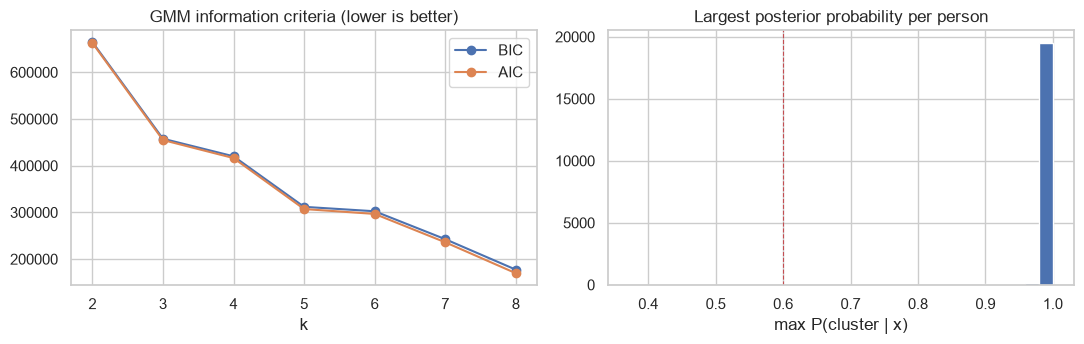

In [81]:
# ---------- Gaussian mixture: BIC and soft assignments ----------
def run_gmm():
    rows, models = [], {}
    for k in range(2, max(6 if FAST else 9, k_best + 1)):
        g = GaussianMixture(k, covariance_type="full", n_init=2, random_state=SEED).fit(Zp); models[k] = g
        rows.append(dict(k=k, BIC=g.bic(Zp), AIC=g.aic(Zp)))
    return pd.DataFrame(rows).set_index("k"), models[k_best].predict(Zp), models[k_best].predict_proba(Zp)
gmm_tab, gmm_lab, gmm_prob = cached("unsup_gmm", run_gmm, sig=f"{Zp.shape}|{k_best}|{FAST}")
print(gmm_tab.round(0))
k_bic = int(gmm_tab["BIC"].idxmin())
print(f"\nBIC is minimal at k = {k_bic}  (k-means chose k = {k_best}; BIC keeps decreasing with n this large, so it tends to over-split a continuous gradient)")

certain = gmm_prob.max(1)
print(f"GMM with k = {k_best}: ARI vs k-means = {adjusted_rand_score(lab.values, gmm_lab):.3f} | "
      f"people assigned with probability < 0.6 (ambiguous) = {100 * np.mean(certain < 0.6):.1f} %")
prof_g = pd.crosstab(pd.Series(gmm_lab, name="gmm cluster"), y_cl, normalize="index") * 100
prof_g["joint risk %"] = prof_g[1] + prof_g[2]; prof_g.columns = ["% no diabetes", "% prediabetes", "% diabetes", "% joint risk"]
print(prof_g.round(1))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
gmm_tab[["BIC", "AIC"]].plot(marker="o", ax=ax[0], title="GMM information criteria (lower is better)")
ax[1].hist(certain, bins=30); ax[1].axvline(.6, c="r", ls="--", lw=.8); ax[1].set(title="Largest posterior probability per person", xlabel="max P(cluster | x)")
plt.tight_layout(); plt.show()

                   eps  clusters  noise_pct  largest_cluster_pct  ARI_vs_kmeans  joint_risk_noise_pct  joint_risk_rest_pct
quantile_of_kdist                                                                                                         
0.80              2.96         4      10.11                82.90           0.28                 26.81                14.74
0.90              3.54         4       3.46                86.27           0.22                 24.86                15.64
0.95              4.06         4       1.43                87.14           0.20                 17.48                15.94


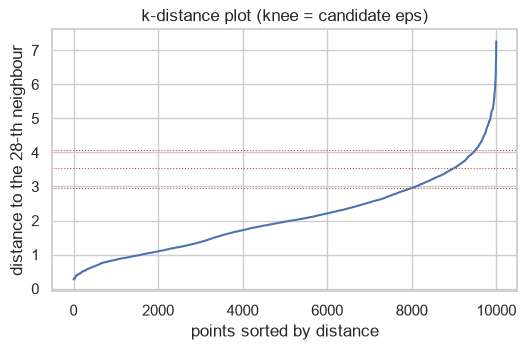

In [82]:
# ---------- DBSCAN: eps from the k-distance plot ----------
ix_db = rs_cl.choice(len(Zp), 3000 if FAST else 10000, replace=False); Zdb = Zp[ix_db]
min_samples = 2 * Zp.shape[1]                                       # common rule of thumb: 2 x dimension
kd = np.sort(NearestNeighbors(n_neighbors=min_samples).fit(Zdb).kneighbors(Zdb)[0][:, -1])
rows = []
for q in (0.80, 0.90, 0.95):
    eps = float(np.quantile(kd, q)); db = DBSCAN(eps=eps, min_samples=min_samples).fit(Zdb); l_ = db.labels_
    n_cl_ = len(set(l_)) - (1 if -1 in l_ else 0); sizes = pd.Series(l_[l_ >= 0]).value_counts()
    rows.append(dict(quantile_of_kdist=q, eps=eps, clusters=n_cl_, noise_pct=100 * np.mean(l_ == -1),
                     largest_cluster_pct=100 * (sizes.iloc[0] / len(l_) if len(sizes) else 0),
                     ARI_vs_kmeans=adjusted_rand_score(lab.values[ix_db], l_),
                     joint_risk_noise_pct=100 * np.mean(y_cl.values[ix_db][l_ == -1] >= 1) if (l_ == -1).any() else np.nan,
                     joint_risk_rest_pct=100 * np.mean(y_cl.values[ix_db][l_ != -1] >= 1) if (l_ != -1).any() else np.nan))
db_tab = pd.DataFrame(rows).set_index("quantile_of_kdist")
with pd.option_context("display.float_format", "{:.2f}".format, "display.width", 200):
    print(db_tab)
plt.figure(figsize=(6, 3.4)); plt.plot(kd); [plt.axhline(np.quantile(kd, q), c="r", ls=":", lw=.8) for q in (0.8, 0.9, 0.95)]
plt.xlabel("points sorted by distance"); plt.ylabel(f"distance to the {min_samples}-th neighbour"); plt.title("k-distance plot (knee = candidate eps)"); plt.show()

                                              cophenetic_corr  silhouette  largest_cluster_pct  ARI_vs_kmeans  diab_prev_max_over_min
variant                                                                                                                              
ward · euclidean · standardised (PCA scores)            0.621       0.206               68.000          0.491                   3.706
complete · euclidean                                    0.710       0.233               95.733          0.186                   8.669
average · euclidean                                     0.830       0.352               99.867          0.002                     NaN
single · euclidean                                      0.765       0.291               96.000          0.183                   8.760
average · manhattan                                     0.823       0.359               99.833          0.002                     NaN
ward · euclidean · NOT standardised                     0.800 

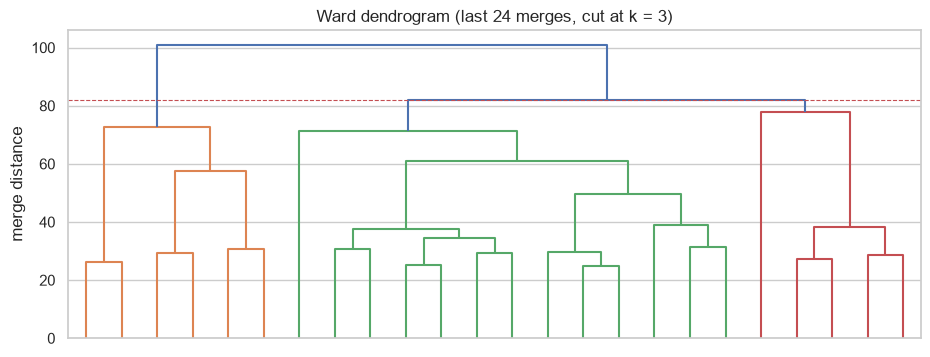

In [83]:
# ---------- Hierarchical clustering: linkages, distances, scaling; dendrogram ----------
ix_h = rs_cl.choice(len(Zp), 1500 if FAST else 3000, replace=False)
data_std, data_raw, y_h, km_h = Zp[ix_h], X_cl.iloc[ix_h].to_numpy(float), y_cl.values[ix_h], lab.values[ix_h]
variants = [("ward · euclidean · standardised (PCA scores)", "ward", "euclidean", data_std),
            ("complete · euclidean", "complete", "euclidean", data_std),
            ("average · euclidean", "average", "euclidean", data_std),
            ("single · euclidean", "single", "euclidean", data_std),
            ("average · manhattan", "average", "cityblock", data_std),
            ("ward · euclidean · NOT standardised", "ward", "euclidean", data_raw)]
from scipy.cluster.hierarchy import fcluster
rows, L_store = [], {}
for nm, meth, metric, D in variants:
    dist_ = pdist(D, metric); Lk = linkage(D, "ward") if meth == "ward" else linkage(dist_, meth)
    labs = fcluster(Lk, k_best, "maxclust"); L_store[nm] = Lk
    sizes = pd.Series(labs).value_counts(normalize=True)
    prev_ = pd.Series(y_h == 2).groupby(labs).mean()
    prev_ = prev_[sizes[sizes >= 0.01].index]                       # ignore clusters with < 1 % of the people (tiny chains)
    rows.append(dict(variant=nm, cophenetic_corr=cophenet(Lk, dist_)[0], silhouette=silhouette_score(D, labs, metric=metric) if len(set(labs)) > 1 else np.nan,
                     largest_cluster_pct=100 * sizes.iloc[0], ARI_vs_kmeans=adjusted_rand_score(km_h, labs),
                     diab_prev_max_over_min=prev_.max() / max(prev_.min(), 1e-9) if len(prev_) > 1 else np.nan))
hier_tab = pd.DataFrame(rows).set_index("variant")
with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 200):
    print(hier_tab)

Lw = L_store[variants[0][0]]
plt.figure(figsize=(11, 4))
dendrogram(Lw, truncate_mode="lastp", p=24, no_labels=True, color_threshold=Lw[-(k_best - 1), 2])
plt.axhline(Lw[-(k_best - 1), 2], c="r", ls="--", lw=.8); plt.title(f"Ward dendrogram (last 24 merges, cut at k = {k_best})"); plt.ylabel("merge distance"); plt.show()

> **What the comparison teaches.** (i) The cophenetic correlation says how faithfully a dendrogram preserves the original distances (Ward and average are usually best, single chaining is typically the worst). (ii) *Single* linkage puts almost everybody in one cluster (largest-cluster share ≈ 100 %): it follows chains of neighbours and the data form one continuous cloud. (iii) Without standardisation, BMI (range 12–98) dominates the distance and the clusters mostly split on BMI, which changes the ARI against the standardised solution: **the scaling decision matters more than the algorithm**. (iv) DBSCAN needs density gaps that this data set does not have.

### Closing the loop: do the clusters help the supervised model? (H10)
Part 3 never used the clusters. An *unsupervised* structure can be turned into features for a *supervised* model (a classic use of clustering): membership of each cluster (one-hot) and the distance to every centroid. The rule that matters is the usual one: the clustering must be **fitted inside each training fold** (weighted resample of that fold's training rows → standardise → PCA → k-means with the *k* found above) and only *applied* to the validation fold, otherwise the validation rows influence the features.

**H10 (fixed before running):** because the supervised models already see all the variables the clusters are built from, cluster features add **less than 0.005 AUC** to the tuned boosting model. A gain would mean that the clusters expose structure the model cannot find on its own; for the linear logistic model a gain is more plausible (clusters act as non-linear features).

In [84]:
FIG_TAG = "unsup"
def make_cluster_features(X_fit, w_fit, k, seed):
    rs_ = np.random.RandomState(seed)
    ix_ = rs_.choice(len(X_fit), min(N_CLUST, len(X_fit)), p=w_fit / w_fit.sum())            # population-representative resample of THIS fold's train
    sc_ = StandardScaler().fit(X_fit.iloc[ix_]); pca_ = PCA(n_components=0.80, random_state=seed).fit(sc_.transform(X_fit.iloc[ix_]))
    km_ = KMeans(k, n_init=5, random_state=seed).fit(pca_.transform(sc_.transform(X_fit.iloc[ix_])))
    cols = [f"cl{i}" for i in range(k)] + [f"cd{i}" for i in range(k)]
    def transform(X):
        D = km_.transform(pca_.transform(sc_.transform(X)))
        return pd.DataFrame(np.column_stack([np.eye(k)[D.argmin(1)], D]), columns=cols, index=X.index)
    return transform, cols

def with_extra(name, kind, extra):
    return Pipeline([("prep", make_prep(kind, extra=extra)), ("clf", clone(MODELS[name].steps[-1][1]))])

def cv_cluster_features():
    rows = []
    for f, (tr, va) in enumerate(StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED).split(Xtr, ytr)):
        tf, cols = make_cluster_features(Xtr.iloc[tr], wtr[tr], k_best, SEED + f)
        Xa, Xb = pd.concat([Xtr.iloc[tr], tf(Xtr.iloc[tr])], axis=1), pd.concat([Xtr.iloc[va], tf(Xtr.iloc[va])], axis=1)
        for name, kind in (("logit_L2_spline", "spline"), ("hgb_tuned", "tree")):
            m0 = fit_w(MODELS[name], Xtr.iloc[tr], ytr[tr], wtr[tr]); m1 = fit_w(with_extra(name, kind, cols), Xa, ytr[tr], wtr[tr])
            rows.append(dict(fold=f, model=name, arm="without clusters", **metrics_clf(ytr[va], m0.predict_proba(Xtr.iloc[va]), wtr[va])))
            rows.append(dict(fold=f, model=name, arm="with clusters",    **metrics_clf(ytr[va], m1.predict_proba(Xb), wtr[va])))
    return pd.DataFrame(rows)
cf = cached("unsup_cluster_features", cv_cluster_features, sig=f"{k_best}|{MODELS['hgb_tuned']!r}|{MODELS['logit_L2_spline']!r}|{N_CLUST}")

rows = []
for name in ("logit_L2_spline", "hgb_tuned"):
    a, b = cf[(cf.model == name) & (cf.arm == "with clusters")].set_index("fold"), cf[(cf.model == name) & (cf.arm == "without clusters")].set_index("fold")
    for met in ("auc_diab", "auc_ovr", "logloss"):
        d = a[met] - b[met]; rows.append(dict(model=name, metric=met, without=b[met].mean(), with_clusters=a[met].mean(), diff=d.mean(), SE=d.std(ddof=1) / np.sqrt(len(d))))
cf_tab = pd.DataFrame(rows).set_index(["model", "metric"])
with pd.option_context("display.float_format", "{:.4f}".format):
    print(cf_tab)
gain_hgb = cf_tab.loc[("hgb_tuned", "auc_diab"), "diff"]
VERDICT["H10"] = (gain_hgb < 0.005, f"AUC(diabetes) gain of tuned HGB with cluster features = {gain_hgb:+.4f} (criterion < 0.005); "
                                    f"logistic: {cf_tab.loc[('logit_L2_spline', 'auc_diab'), 'diff']:+.4f}")
ok, msg = VERDICT["H10"]; print("\nH10 ·", "HOLDS    " if ok else "DOES NOT HOLD", "·", msg)

                          without  with_clusters    diff     SE
model           metric                                         
logit_L2_spline auc_diab   0.8252         0.8256  0.0005 0.0001
                auc_ovr    0.7835         0.7834 -0.0000 0.0002
                logloss    0.3973         0.3965 -0.0009 0.0000
hgb_tuned       auc_diab   0.8279         0.8272 -0.0007 0.0002
                auc_ovr    0.7862         0.7855 -0.0007 0.0004
                logloss    0.3946         0.3949  0.0003 0.0001

H10 · HOLDS     · AUC(diabetes) gain of tuned HGB with cluster features = -0.0007 (criterion < 0.005); logistic: +0.0005


**Reading Part 4:** clusters that differ strongly in prevalence yet have a low ARI mean the unsupervised structure is *health-profile* structure (the PC1 "poor health / low socio-economic" axis of §1.9) that **correlates with** diabetes without reproducing the label. Whether the cluster id (computed *inside* each CV fold) improves the classifier of Part 3 is tested in H10 above.

# Part 5 · Hypothesis scorecard, limitations and conclusions

## 5.1 Scorecard
All outcomes below were produced by the code of Parts 2–4 from the criteria fixed at the top of the notebook; nothing is hand-typed.

In [85]:
labels = {'H1': 'Moderate performance (AUC 0.70–0.85)', 'H2': 'Non-linear models improve little (< 0.02 AUC)',
          'H3': 'Prediabetes is the worst-predicted class', 'H4': '≤ 10 variables keep the performance (< 0.01 AUC)',
          'H5': 'Education + Income add little (< 0.005 AUC)', 'H6': 'Uncalibrated trees are worse calibrated; calibrating helps',
          'H7a': 'Weak associations with BMI (|ρ| ≤ 0.23)', 'H7b': 'BMI test R² < 0.30',
          'H7c': 'Splines on Age beat the linear fit', 'H8': 'Clusters differ in prevalence but not = target',
          'H9': 'Ridge / PCR / PLS do not beat OLS (< 0.01 RMSE)', 'H10': 'Cluster features add < 0.005 AUC to boosting',
          'H11': 'AUC falls with age (18-39 minus 60+ > 0.03)'}
score = pd.DataFrame([(k, labels.get(k, ''), 'HOLDS' if ok else 'DOES NOT HOLD', msg) for k, (ok, msg) in sorted(VERDICT.items())],
                     columns=['hypothesis', 'statement', 'verdict', 'evidence'])
pd.set_option('display.max_colwidth', 220); pd.set_option('display.width', 250)
score

,hypothesis,statement,verdict,evidence
0,H1,Moderate performance (AUC 0.70–0.85),HOLDS,test AUC(diabetes vs rest) = 0.837 (criterion 0.70–0.85)
1,H10,Cluster features add < 0.005 AUC to boosting,HOLDS,AUC(diabetes) gain of tuned HGB with cluster features = -0.0007 (criterion < 0.005); logistic: +0.0005
2,H11,AUC falls with age (18-39 minus 60+ > 0.03),HOLDS,"AUC(18-39) = 0.833, AUC(60+) = 0.782, difference = +0.051 (criterion > 0.03)"
3,H2,Non-linear models improve little (< 0.02 AUC),HOLDS,"max AUC gain over logit_L2_spline = hgb_tuned: +0.0029, rf_tuned: -0.0045 (criterion < 0.02)"
4,H3,Prediabetes is the worst-predicted class,HOLDS,"F1 by class = [0.885, 0.034, 0.478] | AUC by class = [0.832, 0.711, 0.837]"
5,H4,≤ 10 variables keep the performance (< 0.01 AUC),DOES NOT HOLD,AUC loss with top-10 = 0.0390 (criterion < 0.01); with top-15: 0.0021
6,H5,Education + Income add little (< 0.005 AUC),HOLDS,AUC loss without Education/Income = 0.0024 (criterion < 0.005)
7,H6,Uncalibrated trees are worse calibrated; calibrating helps,DOES NOT HOLD,"(a) raw worse than logit in Brier: False | (b) calibration lowers Brier: False [logit 0.2262; raw {'rf_tuned': 0.2223, 'hgb_tuned': 0.2215, 'tree_pruned': 0.2277}; calibrated {'rf_tuned': 0.2221, 'hgb_tuned': 0.2217,..."
8,H7a,Weak associations with BMI (|ρ| ≤ 0.23),DOES NOT HOLD,max |ρ| with BMI = 0.257 (criterion ≤ 0.23)
9,H7b,BMI test R² < 0.30,HOLDS,test R² = 0.157 (HGB ceiling = 0.181; criterion < 0.30)


Hypotheses that **do not hold** are not a failure: they were stated in advance precisely so that the data could contradict them. Report them as such and explain *why* (e.g. a threshold fixed by eye, or a variable subset too aggressive).

## 5.2 Limitations to state in the report
- **Self-reported, cross-sectional data:** the label is "has been diagnosed and reports it", not "has the disease"; prediabetes is massively under-diagnosed (§1.11). Results are associations, **not causal** effects, and the model estimates the probability of *having* the condition, not of developing it.
- **Sample representativity:** skewed towards high education and income (§1.5).
- **Irreducible noise:** identical profiles with different labels (§1.11) put a ceiling on any model, especially for class 1.
- **Counter-intuitive associations** (CholCheck, HvyAlcoholConsump) are explained by detection bias and reverse causality, not by biology.
- **Computational compromises:** the SVM/SVR, KNN, the tree/forest regressors, the hyper-parameter searches, the search-strategy comparison, the SMOTE comparison and the clustering all use fixed subsamples (stated where used); the search's log-loss is unweighted; LDA/QDA/KNN take no sample weights (only their priors are set to the population ones); k-means on mixed binary/ordinal data is an approximation.
- **Tuning on the same CV data:** the reported CV scores of tuned models are slightly optimistic (§3.6.1 measures how much); the test numbers are not.
- **New hypotheses H9–H11** were written down when the extension blocks were added, before they were run on the real data; H1–H8 were fixed earlier.

## 5.3 What was decided where (one-line trace)
duplicates → weights `w` (§1.8) → split once (§1.12) → regression warm-up (Part 2) → classification with calibrated probabilities (Part 3) → unsupervised profiles (Part 4) → scorecard against the hypotheses fixed at the top (§5.1).

## 5.4 Outputs of this run (what to take to the report and to the repository)
Everything below is written to disk by the code itself, so the report can quote the files instead of re-typing numbers:

| Folder | What it holds |
|---|---|
| `results/` | CSV tables: scorecard, classification CV and test tables (all models), regression CV and test tables, cost-sensitive thresholds, subgroup performance, run environment |
| `results/cache/` | cached intermediate results (safe to delete: they are recomputed) |
| `models/` | every fitted model (`.joblib`), including `FINAL_classifier.joblib` (model + decision rule) |
| `figures/` | every figure of the notebook as PNG, named `<part>_<nn>.png` |

In [86]:
FIG_TAG = "summary"
score.to_csv(RESULTS_DIR / "hypothesis_scorecard.csv", index=False)
cv_tab = pd.concat(results.values()).groupby("model", sort=False).mean(numeric_only=True)
cv_tab.to_csv(RESULTS_DIR / "classification_cv_all_models.csv")
tab_test_reg.to_csv(RESULTS_DIR / "regression_test_core_models.csv")
pd.DataFrame(test_metrics, index=["final model on test"]).T.to_csv(RESULTS_DIR / "classification_final_test_metrics.csv")

env = {"python": sys.version.split()[0], "sklearn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__,
       "FAST": FAST, "SEED": SEED, "cv": f"{N_SPLITS}x{N_REPEATS}", "final_model": best_name, "class_scale": [float(v) for v in class_scale],
       "n_train_profiles": int(len(df_train)), "n_test_profiles": int(len(df_test)), "minutes_since_se      ERZFtup": round((time.time() - T_START) / 60, 1)}
for pkg in ("xgboost", "optuna", "imblearn"):
    try: env[pkg] = __import__(pkg).__version__
    except Exception: env[pkg] = "not installed"
(RESULTS_DIR / "environment.json").write_text(json.dumps(env, indent=2))
print(json.dumps(env, indent=2))
for folder in (RESULTS_DIR, MODELS_DIR, FIG_DIR):
    print(f"{str(folder):10s}", len([f for f in folder.glob('*') if f.is_file()]), "files")

{
  "python": "3.13.2",
  "sklearn": "1.9.1",
  "numpy": "2.5.4",
  "pandas": "3.1.1",
  "FAST": false,
  "SEED": 42,
  "cv": "5x2",
  "final_model": "xgb",
  "class_scale": [
    1.0,
    16.0,
    3.0
  ],
  "n_train_profiles": 183824,
  "n_test_profiles": 45957,
  "minutes_since_se      ERZFtup": 102.2,
  "xgboost": "3.4.1",
  "optuna": "5.0.0",
  "imblearn": "0.14.2"
}
results    11 files
models     26 files
figures    32 files
